# D8 single-unit analysis — FREE-CHOICE trials only

The first 20 nose pokes are separated as forced trials and retained in `analysis["forced"]`, but all downstream PETH, raster, normalization, population, PCA, trial-matching, and decoding analyses in this notebook use only `analysis["free"]` / `peth_units_free`.


In [10]:
# ============================================
# SELECT DAY AND FIND ALL PHY RECORDINGS
# ============================================

from pathlib import Path

# ---- CHANGE ONLY THIS ----
DAY = 8

# Base folder for selected day
phy_base = Path(
    rf"D:\Coop_ephys_exp1\Proc\phy_curation\D{8}"
)

# Find folders containing selected day
day_folders = sorted([
    folder
    for folder in phy_base.iterdir()
    if folder.is_dir() and f"_D{DAY}_" in folder.name
])

print(f"D{DAY} recordings found:", len(day_folders))
print()

for folder in day_folders:
    print(folder.name)

# Keep the folder variable used by the unit-loading cell
d8_folders = day_folders

# Recordings used for the D8 nose-poke analyses
nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]

print("\nNose-poke recordings selected:")
print(nosepoke_recordings)

D8 recordings found: 10

20250517_105306_Stage4_D8_1-2_merged
20250517_105306_Stage4_D8_1-3_merged
20250517_105306_Stage4_D8_2-1_merged
20250517_105306_Stage4_D8_2-4_merged
20250517_121746_Stage8_D8_6-1_merged
20250517_121746_Stage8_D8_6-3_merged
20250517_134054_Stage4_D8_4-1_merged
20250517_134054_Stage4_D8_4-2_merged
20250517_134054_Stage4_D8_4-3_merged
20250517_134054_Stage4_D8_4-4_merged

Nose-poke recordings selected:
['1-2', '2-4', '4-3', '4-4']


In [11]:
# ============================================
# LOAD GOOD UNITS FROM ALL D8 RECORDINGS
# ============================================

import numpy as np
import pandas as pd

all_units = {}
unit_summary = []

for folder in d8_folders:

    # ----------------------------------------
    # Extract recording ID
    # Example: D8_1-2 -> "1-2"
    # ----------------------------------------

    parts = folder.name.split("_")
    d8_index = parts.index("D8")
    recording_id = parts[d8_index + 1]

    # ----------------------------------------
    # PHY folder
    # ----------------------------------------

    phy_folder = folder / "phy"

    cluster_info_path = phy_folder / "cluster_info.tsv"
    spike_times_path = phy_folder / "spike_times.npy"
    spike_clusters_path = phy_folder / "spike_clusters.npy"
    params_path = phy_folder / "params.py"

    # ----------------------------------------
    # Check files
    # ----------------------------------------

    required_files = [
        cluster_info_path,
        spike_times_path,
        spike_clusters_path,
        params_path
    ]

    missing_files = [
        f.name
        for f in required_files
        if not f.exists()
    ]

    if missing_files:
        print(
            f"{recording_id}: MISSING FILES:",
            missing_files
        )
        continue

    # ----------------------------------------
    # Load cluster information
    # ----------------------------------------

    cluster_info = pd.read_csv(
        cluster_info_path,
        sep="\t"
    )

    # Select GOOD clusters only
    good_clusters = (
        cluster_info.loc[
            cluster_info["group"] == "good",
            "cluster_id"
        ]
        .astype(int)
        .to_numpy()
    )

    # ----------------------------------------
    # Load spike information
    # ----------------------------------------

    spike_times = np.load(
        spike_times_path
    ).flatten()

    spike_clusters = np.load(
        spike_clusters_path
    ).flatten()

    # ----------------------------------------
    # Read sampling rate from params.py
    # ----------------------------------------

    sampling_rate = None

    with open(params_path, "r") as f:

        for line in f:

            if line.strip().startswith("sample_rate"):

                sampling_rate = float(
                    line.split("=")[1].strip()
                )

                break

    if sampling_rate is None:
        print(
            f"{recording_id}: sampling rate NOT FOUND"
        )
        continue

    # ----------------------------------------
    # Convert spike times to seconds
    # ----------------------------------------

    spike_times_sec = (
        spike_times / sampling_rate
    )

    # ----------------------------------------
    # Store GOOD units
    # ----------------------------------------

    all_units[recording_id] = {}

    for cluster_id in good_clusters:

        mask = (
            spike_clusters == cluster_id
        )

        unit_spikes = spike_times_sec[mask]

        all_units[recording_id][cluster_id] = (
            unit_spikes
        )

    # ----------------------------------------
    # Recording summary
    # ----------------------------------------

    unit_summary.append({
        "recording": recording_id,
        "n_good_units": len(good_clusters),
        "sampling_rate": sampling_rate,
        "duration_sec": spike_times_sec.max()
    })

    print(
        f"{recording_id}: "
        f"{len(good_clusters)} good units | "
        f"{sampling_rate:.0f} Hz | "
        f"{spike_times_sec.max():.1f} sec"
    )


# ============================================
# SUMMARY TABLE
# ============================================

unit_summary = pd.DataFrame(unit_summary)

print("\nSUMMARY")
display(unit_summary)

if not unit_summary.empty:

    print(
        "\nTOTAL GOOD UNITS:",
        unit_summary["n_good_units"].sum()
    )

1-2: 16 good units | 20000 Hz | 2449.3 sec
1-3: 17 good units | 20000 Hz | 2449.3 sec
2-1: 0 good units | 20000 Hz | 2446.1 sec
2-4: 13 good units | 20000 Hz | 2449.0 sec
6-1: 3 good units | 20000 Hz | 2574.3 sec
6-3: MISSING FILES: ['spike_times.npy', 'spike_clusters.npy']
4-1: 13 good units | 20000 Hz | 2398.2 sec
4-2: 16 good units | 20000 Hz | 2398.2 sec
4-3: 27 good units | 20000 Hz | 2398.2 sec
4-4: 13 good units | 20000 Hz | 2398.0 sec

SUMMARY


,recording,n_good_units,sampling_rate,duration_sec
0,1-2,16,20000.0,2449.28280
1,1-3,17,20000.0,2449.28885
2,2-1,0,20000.0,2446.09080
3,2-4,13,20000.0,2449.03055
4,6-1,3,20000.0,2574.25095
5,4-1,13,20000.0,2398.18445
6,4-2,16,20000.0,2398.20450
7,4-3,27,20000.0,2398.20720
8,4-4,13,20000.0,2397.99200



TOTAL GOOD UNITS: 118


In [4]:
# ============================================
# CELL - LOAD BEHAVIORAL EVENTS
# ============================================

import pandas as pd
from pathlib import Path

# Change this to the location of your Excel file
behavior_file = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Data\Processed\all_behavioral_events_classified_D8.xlsx"
)

# Load rewarded Prosocial and Selfish trials
prosocial_df = pd.read_excel(
    behavior_file,
    sheet_name="rewarded_prosocial"
)

selfish_df = pd.read_excel(
    behavior_file,
    sheet_name="rewarded_selfish"
)

print("Prosocial rows:", len(prosocial_df))
print("Selfish rows:", len(selfish_df))

print("\nColumns:")
print(prosocial_df.columns.tolist())

Prosocial rows: 1623
Selfish rows: 631

Columns:
['recording', 'event', 'event_number', 'onset', 'offset', 'duration', 'event_id', 'choice', 'is_nosepoke', 'is_light', 'rewarded', 'matched_light_onset', 'matched_light_offset', 'light_delay', 'matched_light_event_id']


In [5]:
# ============================================
# ORGANIZE BEHAVIORAL EVENTS BY RECORDING
# ============================================

all_events = {}

for recording_id in all_units.keys():

    # Example:
    # recording_id = "1-2"
    # pattern = "_D8_1-2_"

    pattern = f"_D8_{recording_id}_"

    # ----------------------------------------
    # PROSOCIAL
    # ----------------------------------------

    pro_mask = (
        prosocial_df["recording"]
        .astype(str)
        .str.contains(pattern, regex=False)
    )

    pro_events = (
        prosocial_df.loc[
            pro_mask,
            "onset"
        ]
        .dropna()
        .astype(float)
        .to_numpy()
    )

    # ----------------------------------------
    # SELFISH
    # ----------------------------------------

    self_mask = (
        selfish_df["recording"]
        .astype(str)
        .str.contains(pattern, regex=False)
    )

    self_events = (
        selfish_df.loc[
            self_mask,
            "onset"
        ]
        .dropna()
        .astype(float)
        .to_numpy()
    )

    # ----------------------------------------
    # STORE EVENTS
    # ----------------------------------------

    all_events[recording_id] = {
        "prosocial": pro_events,
        "selfish": self_events
    }

    print(
        f"{recording_id}: "
        f"{len(pro_events)} Prosocial | "
        f"{len(self_events)} Selfish"
    )

1-2: 186 Prosocial | 45 Selfish
1-3: 186 Prosocial | 45 Selfish
2-1: 219 Prosocial | 30 Selfish
2-4: 219 Prosocial | 30 Selfish
6-1: 60 Prosocial | 228 Selfish
4-1: 146 Prosocial | 54 Selfish
4-2: 169 Prosocial | 22 Selfish
4-3: 146 Prosocial | 54 Selfish
4-4: 169 Prosocial | 22 Selfish


In [7]:
all_events["1-2"]["prosocial"]

array([ 349.128  ,  356.57805,  362.1384 ,  367.4783 ,  372.8383 ,
        380.16835,  390.8785 ,  396.0286 ,  405.7987 ,  411.0488 ,
        420.7189 ,  429.54915,  434.8091 ,  444.27925,  449.76945,
        455.0694 ,  464.3295 ,  480.9597 ,  486.2098 ,  491.43985,
        502.4    ,  507.70005,  513.04015,  519.9602 ,  535.51045,
        548.0406 ,  556.9407 ,  562.47075,  567.59085,  581.091  ,
        586.5311 ,  594.4612 ,  599.9313 ,  608.88135,  614.22145,
        619.81155,  625.0516 ,  638.29175,  643.87225,  649.5419 ,
        658.58205,  669.4422 ,  674.89225,  680.5423 ,  685.7724 ,
        691.31245,  700.9727 ,  718.6228 ,  724.1529 ,  730.943  ,
        736.22305,  745.4932 ,  754.7433 ,  764.08355,  769.3635 ,
        774.77355,  779.9736 ,  789.42375,  797.47385,  802.66405,
        808.204  ,  813.63405,  818.69415,  827.78425,  841.0644 ,
        847.3345 ,  852.7647 ,  858.04465,  863.42485,  872.31485,
        877.9149 ,  882.965  ,  888.25505,  898.19515,  906.67

In [8]:
print("1-2 Prosocial:")
print(all_events["1-2"]["prosocial"][:10])

print("\n1-2 Selfish:")
print(all_events["1-2"]["selfish"][:10])

print("\nNumber Prosocial:",
      len(all_events["1-2"]["prosocial"]))

print("Number Selfish:",
      len(all_events["1-2"]["selfish"]))

1-2 Prosocial:
[349.128   356.57805 362.1384  367.4783  372.8383  380.16835 390.8785
 396.0286  405.7987  411.0488 ]

1-2 Selfish:
[159.8055  172.11565 178.57575 190.1759  195.97595 201.506   224.4967
 230.94665 238.1765  247.8866 ]

Number Prosocial: 186
Number Selfish: 45


In [6]:
# ============================================================
# SPLIT NOSE-POKE EVENTS INTO FORCED AND FREE TRIALS
# First 20 nose pokes = FORCED
# Remaining nose pokes = FREE
# ============================================================

import numpy as np

N_FORCED = 20

# Main structure that will contain both analyses
analysis = {
    "forced": {
        "events": {}
    },
    "free": {
        "events": {}
    }
}


for recording_id in nosepoke_recordings:

    # Get original Prosocial and Selfish nose-poke times
    pro_times = np.asarray(
        all_events[recording_id]["prosocial"]
    )

    self_times = np.asarray(
        all_events[recording_id]["selfish"]
    )


    # --------------------------------------------------------
    # Combine all nose pokes
    # --------------------------------------------------------

    all_times = np.concatenate([
        pro_times,
        self_times
    ])

    all_labels = np.concatenate([
        np.repeat("prosocial", len(pro_times)),
        np.repeat("selfish", len(self_times))
    ])


    # --------------------------------------------------------
    # Sort all nose pokes chronologically
    # --------------------------------------------------------

    order = np.argsort(all_times)

    all_times = all_times[order]
    all_labels = all_labels[order]


    # --------------------------------------------------------
    # Split FORCED and FREE
    # --------------------------------------------------------

    forced_times = all_times[:N_FORCED]
    forced_labels = all_labels[:N_FORCED]

    free_times = all_times[N_FORCED:]
    free_labels = all_labels[N_FORCED:]


    # --------------------------------------------------------
    # Save FORCED events
    # --------------------------------------------------------

    analysis["forced"]["events"][recording_id] = {

        "prosocial": forced_times[
            forced_labels == "prosocial"
        ],

        "selfish": forced_times[
            forced_labels == "selfish"
        ]
    }


    # --------------------------------------------------------
    # Save FREE events
    # --------------------------------------------------------

    analysis["free"]["events"][recording_id] = {

        "prosocial": free_times[
            free_labels == "prosocial"
        ],

        "selfish": free_times[
            free_labels == "selfish"
        ]
    }


    # --------------------------------------------------------
    # Print check
    # --------------------------------------------------------

    forced_pro = np.sum(
        forced_labels == "prosocial"
    )

    forced_self = np.sum(
        forced_labels == "selfish"
    )

    free_pro = np.sum(
        free_labels == "prosocial"
    )

    free_self = np.sum(
        free_labels == "selfish"
    )


    print(f"\n{recording_id}")
    print("-------------------------")

    print(
        f"FORCED: {len(forced_times)} "
        f"| Prosocial = {forced_pro} "
        f"| Selfish = {forced_self}"
    )

    print(
        f"FREE: {len(free_times)} "
        f"| Prosocial = {free_pro} "
        f"| Selfish = {free_self}"
    )

    print(
        f"TOTAL: {len(all_times)}"
    )


1-2
-------------------------
FORCED: 20 | Prosocial = 1 | Selfish = 19
FREE: 211 | Prosocial = 185 | Selfish = 26
TOTAL: 231

2-4
-------------------------
FORCED: 20 | Prosocial = 0 | Selfish = 20
FREE: 229 | Prosocial = 219 | Selfish = 10
TOTAL: 249

4-3
-------------------------
FORCED: 20 | Prosocial = 20 | Selfish = 0
FREE: 180 | Prosocial = 126 | Selfish = 54
TOTAL: 200

4-4
-------------------------
FORCED: 20 | Prosocial = 20 | Selfish = 0
FREE: 171 | Prosocial = 149 | Selfish = 22
TOTAL: 191


In [7]:
# ============================================
# ALIGN ALL UNITS TO BEHAVIORAL EVENTS
# FORCED and FREE
# Prosocial and Selfish
# ============================================

pre_time = 3.0
post_time = 3.0


def align_spikes_to_events(
    spike_times,
    event_times,
    pre_time,
    post_time
):
    aligned_trials = []

    for event_time in event_times:

        relative_spikes = spike_times - event_time

        trial_spikes = relative_spikes[
            (relative_spikes >= -pre_time) &
            (relative_spikes <= post_time)
        ]

        aligned_trials.append(trial_spikes)

    return aligned_trials


# ============================================
# STORE ALIGNED SPIKES
# FORCED and FREE
# ============================================

for trial_phase in ["forced", "free"]:

    analysis[trial_phase]["aligned"] = {}

    for recording_id, units in all_units.items():

        # Only analyze recordings included in nosepoke_recordings
        if recording_id not in nosepoke_recordings:
            continue

        analysis[trial_phase]["aligned"][recording_id] = {}

        # Behavioral events for THIS recording
        # and THIS trial phase
        prosocial_events = analysis[
            trial_phase
        ]["events"][recording_id]["prosocial"]

        selfish_events = analysis[
            trial_phase
        ]["events"][recording_id]["selfish"]


        for cluster_id, spike_times in units.items():

            # Prosocial
            prosocial_aligned = align_spikes_to_events(
                spike_times,
                prosocial_events,
                pre_time,
                post_time
            )

            # Selfish
            selfish_aligned = align_spikes_to_events(
                spike_times,
                selfish_events,
                pre_time,
                post_time
            )

            # Store
            analysis[
                trial_phase
            ]["aligned"][recording_id][cluster_id] = {

                "prosocial": prosocial_aligned,
                "selfish": selfish_aligned
            }


print("Forced and free alignment complete.")

Forced and free alignment complete.


In [8]:
# ============================================
# CHECK ALIGNED TRIAL NUMBERS
# ============================================

for trial_phase in ["forced", "free"]:

    print(f"\n===== {trial_phase.upper()} =====")

    for recording_id in nosepoke_recordings:

        first_cluster = next(
            iter(
                analysis[
                    trial_phase
                ]["aligned"][recording_id]
            )
        )

        data = analysis[
            trial_phase
        ]["aligned"][recording_id][first_cluster]

        n_pro = len(data["prosocial"])
        n_self = len(data["selfish"])

        print(
            f"{recording_id}: "
            f"Pro = {n_pro}, "
            f"Self = {n_self}, "
            f"Total = {n_pro + n_self}"
        )


===== FORCED =====
1-2: Pro = 1, Self = 19, Total = 20
2-4: Pro = 0, Self = 20, Total = 20
4-3: Pro = 20, Self = 0, Total = 20
4-4: Pro = 20, Self = 0, Total = 20

===== FREE =====
1-2: Pro = 185, Self = 26, Total = 211
2-4: Pro = 219, Self = 10, Total = 229
4-3: Pro = 126, Self = 54, Total = 180
4-4: Pro = 149, Self = 22, Total = 171


In [9]:
analysis["free"]["aligned"]["1-2"][61]["prosocial"]

[array([-2.92985, -2.86605, -2.79395, -2.7614 , -2.6995 , -2.6386 ,
        -2.5672 , -2.51355, -2.4299 , -2.37655, -2.32895, -2.28935,
        -2.22875, -2.1802 , -2.0227 , -1.93485, -1.8324 , -1.77525,
        -1.7397 , -1.6951 , -1.6366 , -1.5681 , -1.50805, -1.45935,
        -1.4179 , -1.37935, -1.32095, -1.26135, -1.2205 , -1.18445,
        -1.11715, -1.0837 , -0.9865 , -0.9377 , -0.8711 , -0.845  ,
        -0.80515, -0.7717 , -0.74575, -0.70965, -0.655  , -0.569  ,
        -0.53015, -0.4894 , -0.4271 , -0.33615, -0.2445 , -0.1803 ,
        -0.1612 , -0.09235, -0.02605,  0.02205,  0.06865,  0.1207 ,
         0.15445,  0.2259 ,  0.2807 ,  0.39015,  0.41765,  0.438  ,
         0.4592 ,  0.48575,  0.5134 ,  0.5478 ,  0.5999 ,  0.61675,
         0.64425,  0.6811 ,  0.72715,  0.77415,  0.82515,  0.87155,
         0.946  ,  1.0401 ,  1.10155,  1.2052 ,  1.28695,  1.34705,
         1.41435,  1.4687 ,  1.5922 ,  1.6466 ,  1.69125,  1.74335,
         1.82875,  1.9037 ,  1.99745,  2.03095, 

In [10]:
analysis["free"]["aligned"]["1-2"][61]["selfish"]

[array([-2.99125, -2.9017 , -2.7918 , -2.6397 , -2.4119 , -2.19165,
        -2.15005, -2.11245, -1.9799 , -1.8562 , -1.80355, -1.62805,
        -1.5518 , -1.45615, -1.3647 , -1.32355, -1.23085, -1.1609 ,
        -1.11505, -0.98295, -0.8915 , -0.85015, -0.79635, -0.76495,
        -0.72255, -0.62415, -0.593  , -0.5578 , -0.5085 , -0.4566 ,
        -0.41465, -0.3685 , -0.34255, -0.33125, -0.2789 , -0.23285,
        -0.212  , -0.1809 , -0.13925, -0.0897 , -0.0641 , -0.0319 ,
         0.0076 ,  0.0602 ,  0.1092 ,  0.1605 ,  0.1926 ,  0.24515,
         0.28485,  0.3106 ,  0.34825,  0.38455,  0.4152 ,  0.4962 ,
         0.51875,  0.54085,  0.60015,  0.6264 ,  0.65715,  0.7386 ,
         0.7807 ,  0.8383 ,  0.90205,  0.95155,  0.98155,  1.05195,
         1.08345,  1.10965,  1.15365,  1.2119 ,  1.2619 ,  1.3149 ,
         1.3565 ,  1.43365,  1.4793 ,  1.51575,  1.58125,  1.6195 ,
         1.64585,  1.74905,  1.7836 ,  1.87455,  1.919  ,  1.9804 ,
         2.13415,  2.14815,  2.17065,  2.2167 , 

In [11]:
# ============================================
# CALCULATE PETH FOR ALL UNITS
# FREE-CHOICE TRIALS ONLY
# 50 ms bins
# ============================================

import numpy as np

bin_size = 0.05  # 50 ms

bins = np.arange(
    -pre_time,
    post_time + bin_size,
    bin_size
)

bin_centers = (bins[:-1] + bins[1:]) / 2


def calculate_firing_rate(
    aligned_trials,
    bins,
    bin_size
):
    trial_rates = []

    for spikes in aligned_trials:

        counts, _ = np.histogram(
            spikes,
            bins=bins
        )

        # spikes/bin -> Hz
        rate = counts / bin_size

        trial_rates.append(rate)

    return np.array(trial_rates)


# ============================================
# CALCULATE PETH FOR EVERY UNIT
# FREE-CHOICE TRIALS
# ============================================

peth_units_free = {}

for recording_id, units in analysis["free"]["aligned"].items():

    peth_units_free[recording_id] = {}

    for cluster_id, conditions in units.items():

        # ------------------------------------
        # PROSOCIAL FREE
        # ------------------------------------

        prosocial_rates = calculate_firing_rate(
            conditions["prosocial"],
            bins,
            bin_size
        )

        # ------------------------------------
        # SELFISH FREE
        # ------------------------------------

        selfish_rates = calculate_firing_rate(
            conditions["selfish"],
            bins,
            bin_size
        )

        # ------------------------------------
        # MEAN ACROSS FREE-CHOICE TRIALS
        # ------------------------------------

        prosocial_mean = np.mean(
            prosocial_rates,
            axis=0
        )

        selfish_mean = np.mean(
            selfish_rates,
            axis=0
        )

        # ------------------------------------
        # STORE
        # ------------------------------------

        peth_units_free[recording_id][cluster_id] = {
            "prosocial_trials": prosocial_rates,
            "selfish_trials": selfish_rates,
            "prosocial_mean": prosocial_mean,
            "selfish_mean": selfish_mean
        }


print("FREE-choice PETH calculation complete.")

FREE-choice PETH calculation complete.


In [12]:
# ============================================
# CHECK FREE-CHOICE PETH
# ============================================

recording_id = "1-2"
cluster_id = 61

data = peth_units_free[recording_id][cluster_id]

print("Prosocial trials:", data["prosocial_trials"].shape)
print("Selfish trials:", data["selfish_trials"].shape)

print("Prosocial mean:", data["prosocial_mean"].shape)
print("Selfish mean:", data["selfish_mean"].shape)

Prosocial trials: (185, 120)
Selfish trials: (26, 120)
Prosocial mean: (120,)
Selfish mean: (120,)


In [135]:
peth_units_free["1-2"][61]["prosocial_mean"]

array([16.10810811, 15.24324324, 14.91891892, 16.21621622, 16.54054054,
       15.45945946, 14.48648649, 16.        , 15.35135135, 14.16216216,
       16.64864865, 14.48648649, 13.51351351, 16.        , 15.24324324,
       15.35135135, 15.78378378, 15.56756757, 14.59459459, 15.24324324,
       14.37837838, 14.81081081, 13.18918919, 15.24324324, 13.83783784,
       14.91891892, 16.10810811, 16.43243243, 14.05405405, 16.10810811,
       14.37837838, 14.59459459, 16.21621622, 14.59459459, 15.56756757,
       13.94594595, 13.83783784, 14.91891892, 15.89189189, 15.89189189,
       15.45945946, 14.7027027 , 16.21621622, 17.62162162, 16.        ,
       17.51351351, 19.45945946, 17.18918919, 17.62162162, 19.45945946,
       18.37837838, 20.        , 16.86486486, 20.97297297, 19.56756757,
       19.56756757, 22.05405405, 20.64864865, 23.78378378, 24.10810811,
       25.40540541, 22.59459459, 23.35135135, 20.54054054, 17.40540541,
       16.54054054, 16.54054054, 14.16216216, 15.45945946, 16.43

In [13]:
print(
    "Prosocial:",
    peth_units_free["1-2"][61]["prosocial_trials"].shape
)

print(
    "Selfish:",
    peth_units_free["1-2"][61]["selfish_trials"].shape
)

print(
    "Number of bins:",
    len(bin_centers)
)

Prosocial: (185, 120)
Selfish: (26, 120)
Number of bins: 120


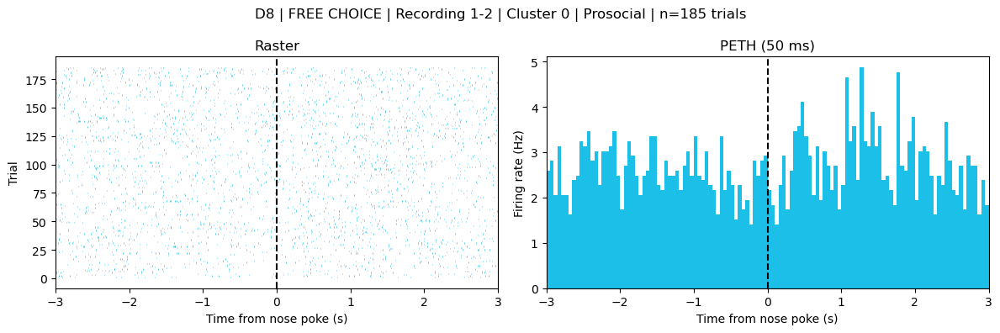

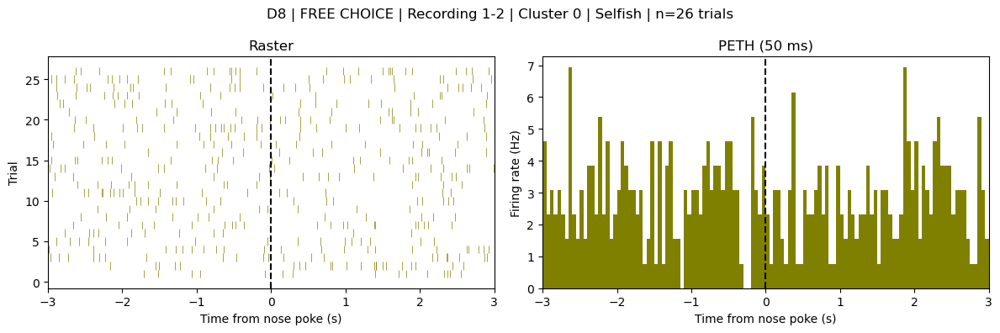

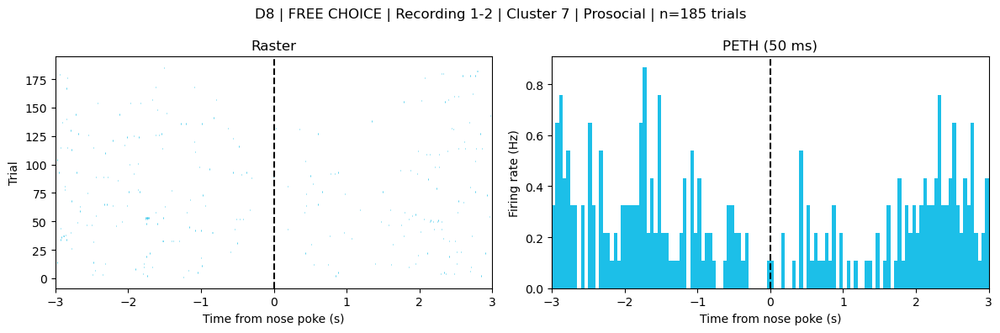

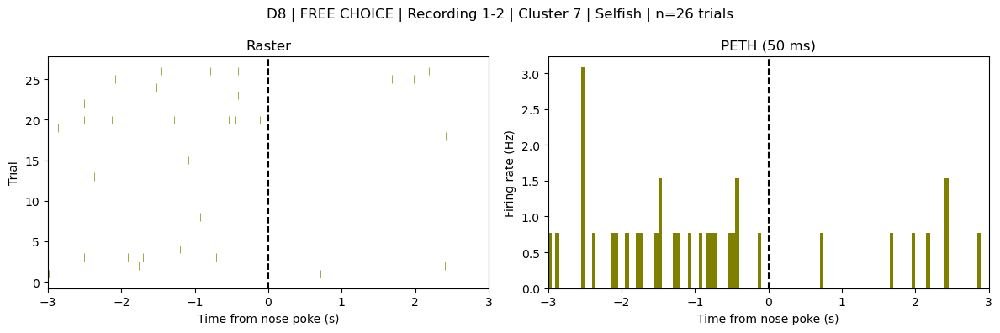

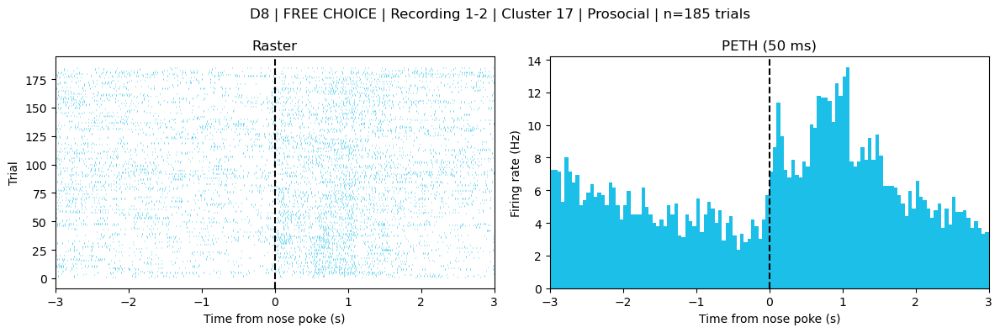

...

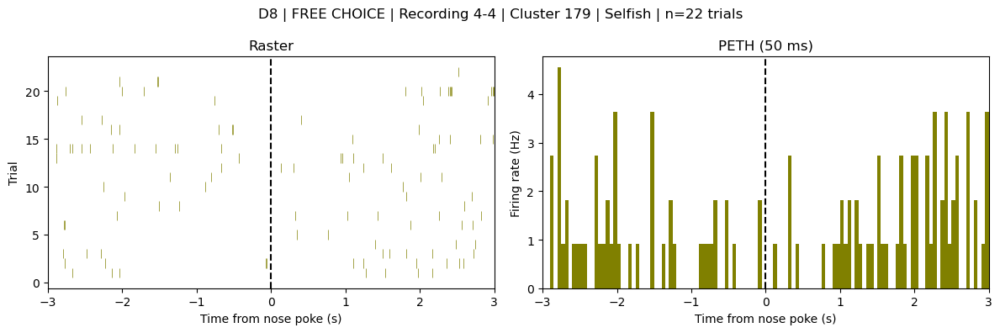

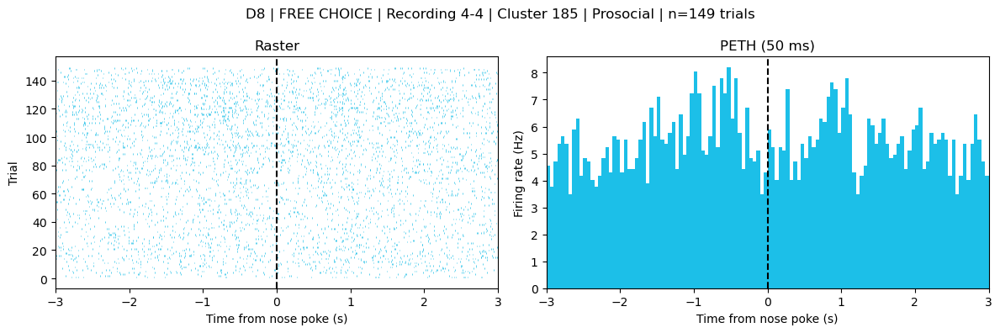

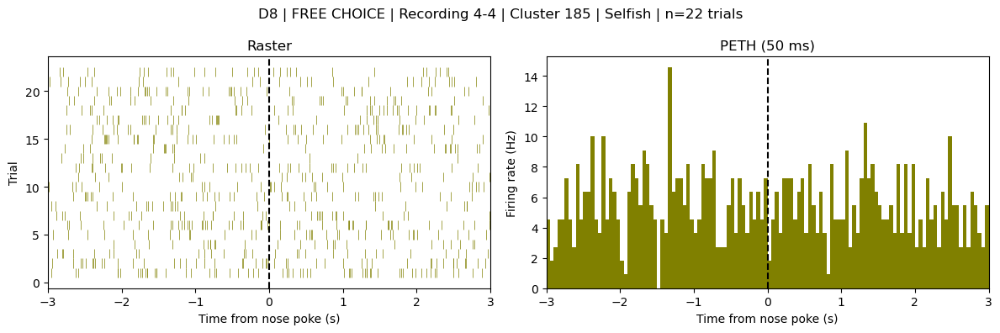

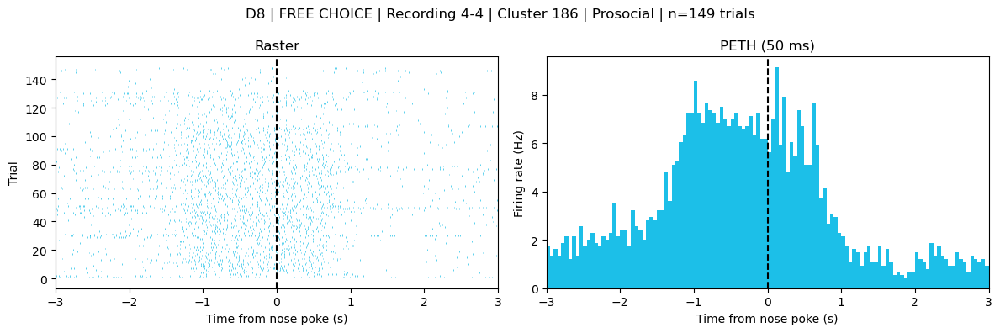

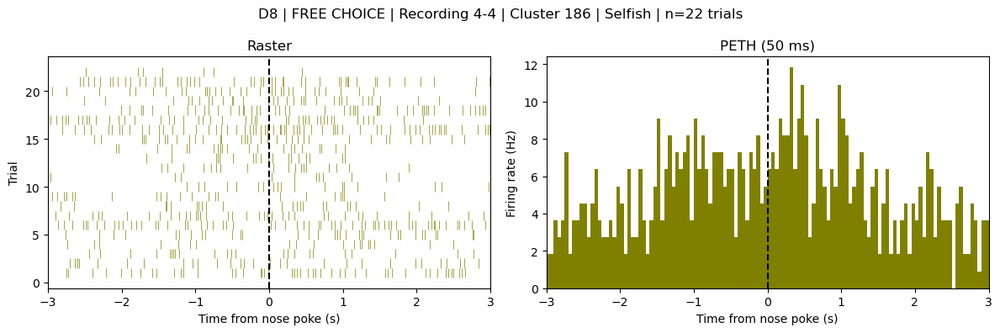

In [14]:
# ============================================
# QC: RASTER + PETH FOR ALL UNITS
# FREE-CHOICE TRIALS ONLY
# ============================================

import matplotlib.pyplot as plt

PROSOCIAL_COLOR = "#1CBFE8"
SELFISH_COLOR = "#808000"


def plot_unit_raster_peth_free(
    recording_id,
    cluster_id,
    condition,
    color
):

    # ========================================
    # GET FREE-CHOICE DATA
    # ========================================

    # Aligned spikes - FREE trials only
    aligned_trials = (
        analysis["free"]["aligned"]
        [recording_id]
        [cluster_id]
        [condition]
    )

    # Mean PETH - FREE trials only
    mean_rate = (
        peth_units_free
        [recording_id]
        [cluster_id]
        [f"{condition}_mean"]
    )


    # ========================================
    # FIGURE
    # ========================================

    fig, (ax_raster, ax_peth) = plt.subplots(
        1,
        2,
        figsize=(12, 4)
    )


    # ========================================
    # RASTER
    # ========================================

    for trial, spikes in enumerate(aligned_trials):

        ax_raster.vlines(
            spikes,
            trial + 0.5,
            trial + 1.5,
            color=color,
            linewidth=0.5
        )

    ax_raster.axvline(
        0,
        color="black",
        linestyle="--"
    )

    ax_raster.set_xlim(
        -pre_time,
        post_time
    )

    ax_raster.set_xlabel(
        "Time from nose poke (s)"
    )

    ax_raster.set_ylabel(
        "Trial"
    )

    ax_raster.set_title(
        "Raster"
    )


    # ========================================
    # PETH
    # ========================================

    ax_peth.bar(
        bin_centers,
        mean_rate,
        width=bin_size,
        color=color
    )

    ax_peth.axvline(
        0,
        color="black",
        linestyle="--"
    )

    ax_peth.set_xlim(
        -pre_time,
        post_time
    )

    ax_peth.set_xlabel(
        "Time from nose poke (s)"
    )

    ax_peth.set_ylabel(
        "Firing rate (Hz)"
    )

    ax_peth.set_title(
        "PETH (50 ms)"
    )


    # ========================================
    # TITLE
    # ========================================

    fig.suptitle(
        f"D8 | FREE CHOICE | "
        f"Recording {recording_id} | "
        f"Cluster {cluster_id} | "
        f"{condition.capitalize()} | "
        f"n={len(aligned_trials)} trials"
    )

    plt.tight_layout()
    plt.show()


# ============================================
# PLOT ALL UNITS
# FREE-CHOICE ONLY
# ============================================

for recording_id, units in peth_units_free.items():

    for cluster_id in units.keys():

        # Prosocial
        plot_unit_raster_peth_free(
            recording_id,
            cluster_id,
            "prosocial",
            PROSOCIAL_COLOR
        )

        # Selfish
        plot_unit_raster_peth_free(
            recording_id,
            cluster_id,
            "selfish",
            SELFISH_COLOR
        )

In [15]:
# ============================================================
# WILCOXON ANALYSIS
# NOSE-POKE: -1 TO 0 s vs 0 TO +1 s
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon


# ============================================================
# 1. CONFIGURATION
# ============================================================

alpha = 0.05

# Only these recordings will be used for nose-poke analysis
nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]

print("Recordings selected:")
print(nosepoke_recordings)


# ============================================================
# 2. DEFINE TIME WINDOWS
# ============================================================

# PRE: -1 to 0 seconds
pre_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0)
)

# POST: 0 to +1 seconds
post_mask = (
    (bin_centers >= 0) &
    (bin_centers <= 1.0)
)

print("\nPRE bins:")
print(bin_centers[pre_mask])

print("\nPOST bins:")
print(bin_centers[post_mask])

print("\nNumber of PRE bins:", np.sum(pre_mask))
print("Number of POST bins:", np.sum(post_mask))


# ============================================================
# 3. RUN WILCOXON FOR EACH NEURON
# ============================================================

results = []

for recording_id, units in peth_units_free.items():

    # ----------------------------------------
    # ONLY SELECTED RECORDINGS
    # ----------------------------------------

    if recording_id not in nosepoke_recordings:
        continue

    for cluster_id, data in units.items():

        # ------------------------------------
        # Mean PETH across trials
        # ------------------------------------

        prosocial_peth = data["prosocial_mean"]
        selfish_peth = data["selfish_mean"]

        # ------------------------------------
        # Extract PRE and POST
        # ------------------------------------

        pro_pre = prosocial_peth[pre_mask]
        pro_post = prosocial_peth[post_mask]

        self_pre = selfish_peth[pre_mask]
        self_post = selfish_peth[post_mask]

        # ------------------------------------
        # Wilcoxon - PROSOCIAL
        # ------------------------------------

        try:
            stat_pro, p_pro = wilcoxon(
                pro_pre,
                pro_post
            )

        except ValueError:
            stat_pro = np.nan
            p_pro = np.nan

        # ------------------------------------
        # Wilcoxon - SELFISH
        # ------------------------------------

        try:
            stat_self, p_self = wilcoxon(
                self_pre,
                self_post
            )

        except ValueError:
            stat_self = np.nan
            p_self = np.nan

        # ------------------------------------
        # Save results
        # ------------------------------------

        results.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            # Prosocial
            "mean_pre_prosocial":
                np.mean(pro_pre),

            "mean_post_prosocial":
                np.mean(pro_post),

            "wilcoxon_stat_prosocial":
                stat_pro,

            "wilcoxon_p_prosocial":
                p_pro,

            # Selfish
            "mean_pre_selfish":
                np.mean(self_pre),

            "mean_post_selfish":
                np.mean(self_post),

            "wilcoxon_stat_selfish":
                stat_self,

            "wilcoxon_p_selfish":
                p_self
        })


# ============================================================
# 4. CREATE RESULTS DATAFRAME
# ============================================================

wilcoxon_results = pd.DataFrame(results)


# ============================================================
# 5. VERIFY RECORDINGS AND NUMBER OF NEURONS
# ============================================================

print("\n====================================")
print("RECORDINGS INCLUDED")
print("====================================")

print(
    wilcoxon_results["recording"]
    .value_counts()
    .sort_index()
)

print(
    "\nTotal units analyzed:",
    len(wilcoxon_results)
)


# ============================================================
# 6. CLASSIFY NEURONS
# ============================================================

def classify_unit(row):

    pro_sig = (
        pd.notna(row["wilcoxon_p_prosocial"]) and
        row["wilcoxon_p_prosocial"] < alpha
    )

    self_sig = (
        pd.notna(row["wilcoxon_p_selfish"]) and
        row["wilcoxon_p_selfish"] < alpha
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return "Prosocial only"

    elif self_sig:
        return "Selfish only"

    else:
        return "Non-modulated"


wilcoxon_results["classification"] = (
    wilcoxon_results.apply(
        classify_unit,
        axis=1
    )
)


# ============================================================
# 7. DIRECTION OF MODULATION
# ============================================================

def get_direction(pre, post, pvalue):

    if pd.isna(pvalue) or pvalue >= alpha:
        return "NS"

    if post > pre:
        return "Increase"

    elif post < pre:
        return "Decrease"

    else:
        return "No change"


wilcoxon_results["direction_prosocial"] = (
    wilcoxon_results.apply(
        lambda row: get_direction(
            row["mean_pre_prosocial"],
            row["mean_post_prosocial"],
            row["wilcoxon_p_prosocial"]
        ),
        axis=1
    )
)

wilcoxon_results["direction_selfish"] = (
    wilcoxon_results.apply(
        lambda row: get_direction(
            row["mean_pre_selfish"],
            row["mean_post_selfish"],
            row["wilcoxon_p_selfish"]
        ),
        axis=1
    )
)


# ============================================================
# 8. PRINT CLASSIFICATION
# ============================================================

print("\n====================================")
print("NEURON CLASSIFICATION")
print("====================================")

classification_counts = (
    wilcoxon_results["classification"]
    .value_counts()
)

print(classification_counts)


# ============================================================
# 9. PRINT NEURONS IN EACH CATEGORY
# ============================================================

categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-modulated"
]

for category in categories:

    print("\n====================================")
    print(category)
    print("====================================")

    temp = wilcoxon_results[
        wilcoxon_results["classification"] == category
    ]

    print(
        temp[
            [
                "recording",
                "cluster_id",
                "wilcoxon_p_prosocial",
                "direction_prosocial",
                "wilcoxon_p_selfish",
                "direction_selfish"
            ]
        ].to_string(index=False)
    )


# ============================================================
# 10. FINAL CHECK
# ============================================================

print("\n====================================")
print("FINAL CHECK")
print("====================================")

print("Total neurons:", len(wilcoxon_results))
print(
    "Classified neurons:",
    classification_counts.sum()
)

print("\nAnalysis complete.")

Recordings selected:
['1-2', '2-4', '4-3', '4-4']

PRE bins:
[-0.975 -0.925 -0.875 -0.825 -0.775 -0.725 -0.675 -0.625 -0.575 -0.525
 -0.475 -0.425 -0.375 -0.325 -0.275 -0.225 -0.175 -0.125 -0.075 -0.025]

POST bins:
[0.025 0.075 0.125 0.175 0.225 0.275 0.325 0.375 0.425 0.475 0.525 0.575
 0.625 0.675 0.725 0.775 0.825 0.875 0.925 0.975]

Number of PRE bins: 20
Number of POST bins: 20

RECORDINGS INCLUDED
recording
1-2    16
2-4    13
4-3    27
4-4    13
Name: count, dtype: int64

Total units analyzed: 69

NEURON CLASSIFICATION
classification
Non-modulated     30
Prosocial only    21
Both              11
Selfish only       7
Name: count, dtype: int64

Prosocial only
recording  cluster_id  wilcoxon_p_prosocial direction_prosocial  wilcoxon_p_selfish direction_selfish
      1-2          17              0.000002            Increase            0.076141                NS
      1-2          62              0.000261            Decrease            0.063961                NS
      1-2          8

c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


In [16]:
print(
    wilcoxon_results["classification"]
    .value_counts()
)

print("\nPercentages:")

print(
    wilcoxon_results["classification"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

classification
Non-modulated     30
Prosocial only    21
Both              11
Selfish only       7
Name: count, dtype: int64

Percentages:
classification
Non-modulated     43.48
Prosocial only    30.43
Both              15.94
Selfish only      10.14
Name: proportion, dtype: float64


Counts:
Prosocial only: 21
Selfish only: 7
Both: 11
Non-modulated: 30

Total: 69

Figure saved:
C:\Cooperation project\Single_unit_pipeline\Results\D8_Free_neuron_classification.png


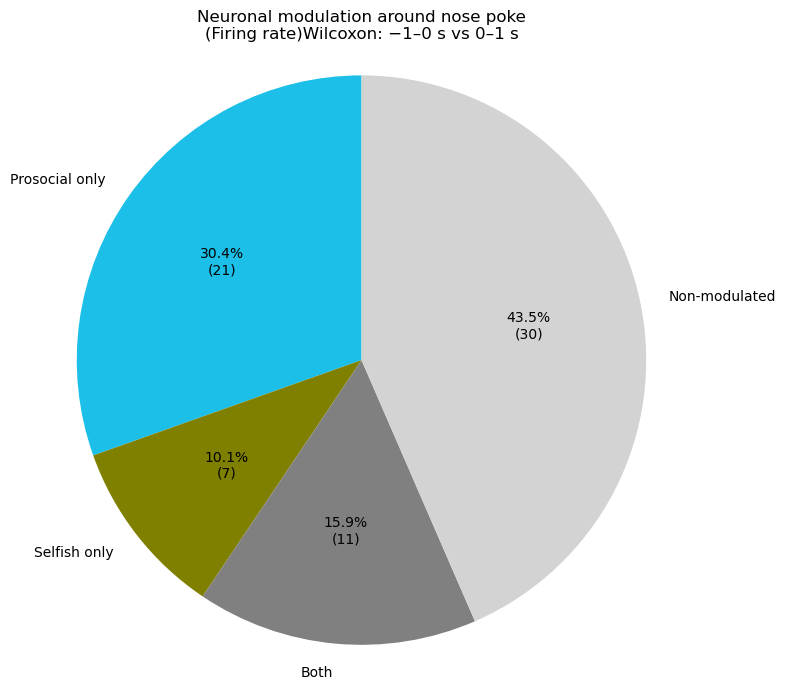

In [17]:
# ============================================
# PIE CHART - NEURON CLASSIFICATION
# SAVE + DISPLAY
# ============================================

import matplotlib.pyplot as plt
from pathlib import Path


# ============================================
# SAVE LOCATION
# ============================================

save_location = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Results"
)

# Name of the figure
figure_name = "D8_Free_neuron_classification.png"


# ============================================
# ORDER OF CATEGORIES
# ============================================

categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-modulated"
]


# Count neurons in each category
counts = [
    (wilcoxon_results["classification"] == category).sum()
    for category in categories
]


print("Counts:")

for category, count in zip(categories, counts):
    print(f"{category}: {count}")

print("\nTotal:", sum(counts))


# ============================================
# PIE CHART
# ============================================

colors = [
    "#1CBFE8",   # Prosocial
    "#808000",   # Selfish
    "gray",      # Both
    "lightgray"  # Non-modulated
]


fig, ax = plt.subplots(
    figsize=(8, 7)
)


ax.pie(
    counts,
    labels=categories,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct / 100. * sum(counts)))})"
    ),
    startangle=90
)


ax.set_title(
    "Neuronal modulation around nose poke\n(Firing rate)"
    "Wilcoxon: −1–0 s vs 0–1 s"
)

ax.axis("equal")

plt.tight_layout()


# ============================================
# SAVE FIGURE
# ============================================

figure_path = save_location / figure_name

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)


print("\nFigure saved:")
print(figure_path)


# ============================================
# DISPLAY FIGURE
# ============================================

plt.show()

In [18]:
# ============================================================
# DIRECTION OF MODULATION
# ONLY SIGNIFICANT NEURONS
# ============================================================

# ------------------------------------------------------------
# 1. PROSOCIAL SIGNIFICANT NEURONS
# ------------------------------------------------------------

sig_prosocial = wilcoxon_results[
    wilcoxon_results["wilcoxon_p_prosocial"] < alpha
].copy()


sig_prosocial["direction"] = np.where(
    sig_prosocial["mean_post_prosocial"] >
    sig_prosocial["mean_pre_prosocial"],
    "Increase",
    "Decrease"
)


print("====================================")
print("PROSOCIAL SIGNIFICANT NEURONS")
print("====================================")

print(
    sig_prosocial[
        [
            "recording",
            "cluster_id",
            "mean_pre_prosocial",
            "mean_post_prosocial",
            "wilcoxon_p_prosocial",
            "direction"
        ]
    ].to_string(index=False)
)

print("\nProsocial counts:")
print(sig_prosocial["direction"].value_counts())


# ------------------------------------------------------------
# 2. SELFISH SIGNIFICANT NEURONS
# ------------------------------------------------------------

sig_selfish = wilcoxon_results[
    wilcoxon_results["wilcoxon_p_selfish"] < alpha
].copy()


sig_selfish["direction"] = np.where(
    sig_selfish["mean_post_selfish"] >
    sig_selfish["mean_pre_selfish"],
    "Increase",
    "Decrease"
)


print("\n====================================")
print("SELFISH SIGNIFICANT NEURONS")
print("====================================")

print(
    sig_selfish[
        [
            "recording",
            "cluster_id",
            "mean_pre_selfish",
            "mean_post_selfish",
            "wilcoxon_p_selfish",
            "direction"
        ]
    ].to_string(index=False)
)

print("\nSelfish counts:")
print(sig_selfish["direction"].value_counts())

PROSOCIAL SIGNIFICANT NEURONS
recording  cluster_id  mean_pre_prosocial  mean_post_prosocial  wilcoxon_p_prosocial direction
      1-2          17            3.978378             9.416216              0.000002  Increase
      1-2          22           43.437838            39.151351              0.048441  Decrease
      1-2          62            5.772973             2.875676              0.000261  Decrease
      1-2          83           12.394595             8.762162              0.000342  Decrease
      1-2          86            2.054054             2.762162              0.019408  Increase
      2-4           4            0.716895             0.228311              0.000512  Decrease
      2-4          27            1.118721             0.771689              0.017181  Decrease
      2-4          49            0.493151             1.041096              0.001659  Increase
      2-4          58            3.242009             0.662100              0.000002  Decrease
      2-4          7

Prosocial
Increase: 8
Decrease: 24
Total significant: 32

Selfish
Increase: 10
Decrease: 8
Total significant: 18


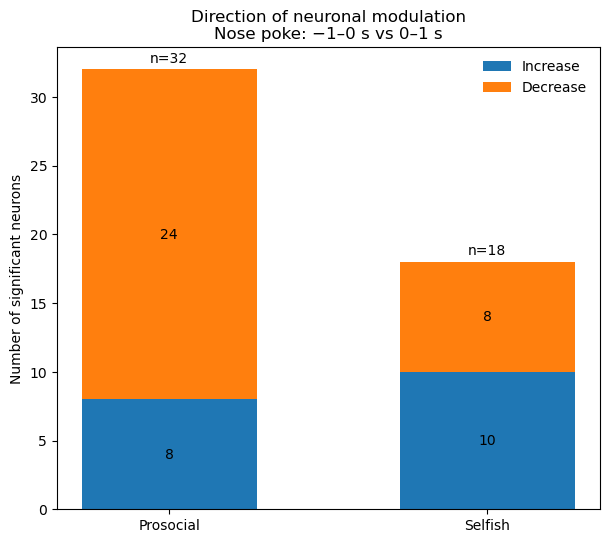

In [19]:
# ============================================
# STACKED BAR PLOT: INCREASE vs DECREASE
# SIGNIFICANT NEURONS ONLY
# ============================================

import matplotlib.pyplot as plt
import numpy as np



# Name of the figure
figure_name = "D8_Free_neuron_classification.png"


# ============================================
# COUNT DIRECTION
# ============================================

pro_counts = sig_prosocial["direction"].value_counts()
self_counts = sig_selfish["direction"].value_counts()


increase_counts = np.array([
    pro_counts.get("Increase", 0),
    self_counts.get("Increase", 0)
])

decrease_counts = np.array([
    pro_counts.get("Decrease", 0),
    self_counts.get("Decrease", 0)
])


conditions = [
    "Prosocial",
    "Selfish"
]

x = np.arange(len(conditions))


# ============================================
# PRINT COUNTS
# ============================================

print("Prosocial")
print("Increase:", increase_counts[0])
print("Decrease:", decrease_counts[0])
print("Total significant:", increase_counts[0] + decrease_counts[0])

print("\nSelfish")
print("Increase:", increase_counts[1])
print("Decrease:", decrease_counts[1])
print("Total significant:", increase_counts[1] + decrease_counts[1])


# ============================================
# STACKED BAR PLOT
# ============================================

fig, ax = plt.subplots(
    figsize=(7, 6)
)


# Increase - bottom
bars_increase = ax.bar(
    x,
    increase_counts,
    width=0.55,
    label="Increase"
)


# Decrease - stacked on top
bars_decrease = ax.bar(
    x,
    decrease_counts,
    width=0.55,
    bottom=increase_counts,
    label="Decrease"
)


# ============================================
# LABELS INSIDE BARS
# ============================================

for i in range(len(conditions)):

    # Increase
    if increase_counts[i] > 0:

        ax.text(
            x[i],
            increase_counts[i] / 2,
            str(increase_counts[i]),
            ha="center",
            va="center"
        )

    # Decrease
    if decrease_counts[i] > 0:

        ax.text(
            x[i],
            increase_counts[i] + decrease_counts[i] / 2,
            str(decrease_counts[i]),
            ha="center",
            va="center"
        )


# ============================================
# TOTAL ABOVE EACH BAR
# ============================================

totals = increase_counts + decrease_counts

for i, total in enumerate(totals):

    ax.text(
        x[i],
        total + 0.3,
        f"n={total}",
        ha="center",
        va="bottom"
    )


# ============================================
# AXES
# ============================================

ax.set_ylabel(
    "Number of significant neurons"
)

ax.set_xticks(x)

ax.set_xticklabels(
    conditions
)

ax.set_title(
    "Direction of neuronal modulation\n"
    "Nose poke: −1–0 s vs 0–1 s"
)

ax.legend(
    frameon=False
)


from pathlib import Path

save_location = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Results"
)

figure_name = "D8_Free_Increase_vs_Decrease.png"

fig.savefig(
    save_location / figure_name,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Counts:
  Prosocial only — Increase: 6
  Prosocial only — Decrease: 15
  Selfish only — Increase: 3
  Selfish only — Decrease: 4
  Both: 11
  Non-modulated: 30

Total: 69

Figure saved:
C:\Cooperation project\Single_unit_pipeline\Results\D8_Free_neuron_classification.png


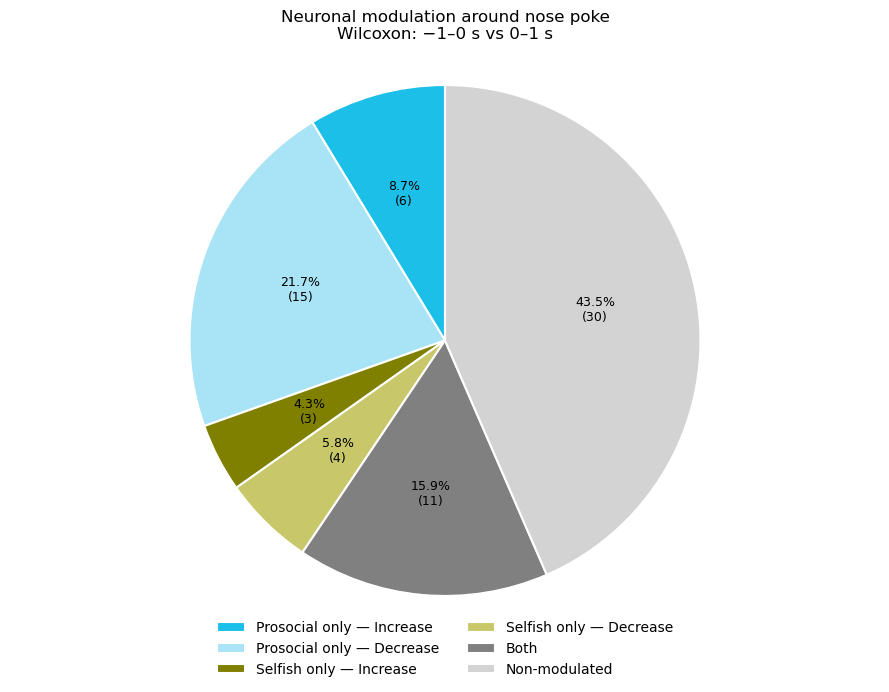

In [114]:
# ============================================================
# PIE CHART - NEURON CLASSIFICATION
# 6 categories: Prosocial/Selfish only (Inc/Dec), Both, Non-mod
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path


# ------------------------------------------------------------
# BUILD 6-CATEGORY CLASSIFICATION
# ------------------------------------------------------------

df = wilcoxon_results.copy()

# Direction for prosocial significant neurons
df["direction_prosocial"] = np.where(
    df["mean_post_prosocial"] > df["mean_pre_prosocial"],
    "Increase",
    "Decrease"
)

# Direction for selfish significant neurons
df["direction_selfish"] = np.where(
    df["mean_post_selfish"] > df["mean_pre_selfish"],
    "Increase",
    "Decrease"
)


# ------------------------------------------------------------
# ASSIGN FINAL CATEGORY
# ------------------------------------------------------------

def assign_category(row):

    base = row["classification"]

    if base == "Prosocial only":
        return f"Prosocial only — {row['direction_prosocial']}"

    elif base == "Selfish only":
        return f"Selfish only — {row['direction_selfish']}"

    elif base == "Both":
        return "Both"

    else:
        return "Non-modulated"


df["category_detail"] = df.apply(
    assign_category,
    axis=1
)


# ------------------------------------------------------------
# COUNT EACH CATEGORY
# ------------------------------------------------------------

category_order = [
    "Prosocial only — Increase",
    "Prosocial only — Decrease",
    "Selfish only — Increase",
    "Selfish only — Decrease",
    "Both",
    "Non-modulated"
]

counts = [
    (df["category_detail"] == cat).sum()
    for cat in category_order
]

print("Counts:")
for cat, count in zip(category_order, counts):
    print(f"  {cat}: {count}")
print(f"\nTotal: {sum(counts)}")


# ------------------------------------------------------------
# COLORS
# ------------------------------------------------------------

colors = [
    "#1CBFE8",   # Prosocial Increase
    "#A8E4F5",   # Prosocial Decrease
    "#808000",   # Selfish Increase
    "#C8C86A",   # Selfish Decrease
    "gray",      # Both
    "lightgray"  # Non-modulated
]


# ------------------------------------------------------------
# PIE CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    counts,
    labels=None,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct / 100. * sum(counts)))})"
        if pct > 0 else ""
    ),
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

# Autopct font size
for autotext in autotexts:
    autotext.set_fontsize(9)

ax.legend(
    wedges,
    category_order,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
    fontsize=10
)

ax.set_title(
    "Neuronal modulation around nose poke\n"
    "Wilcoxon: −1–0 s vs 0–1 s",
    fontsize=12,
    pad=15
)

ax.axis("equal")
plt.tight_layout()


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

save_location = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Results"
)

figure_path = save_location / "D8_Free_neuron_classification.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure saved:")
print(figure_path)

plt.show()

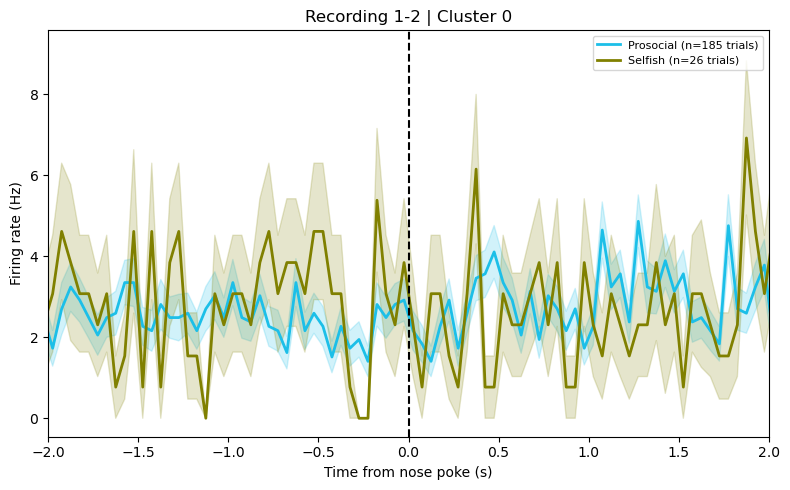

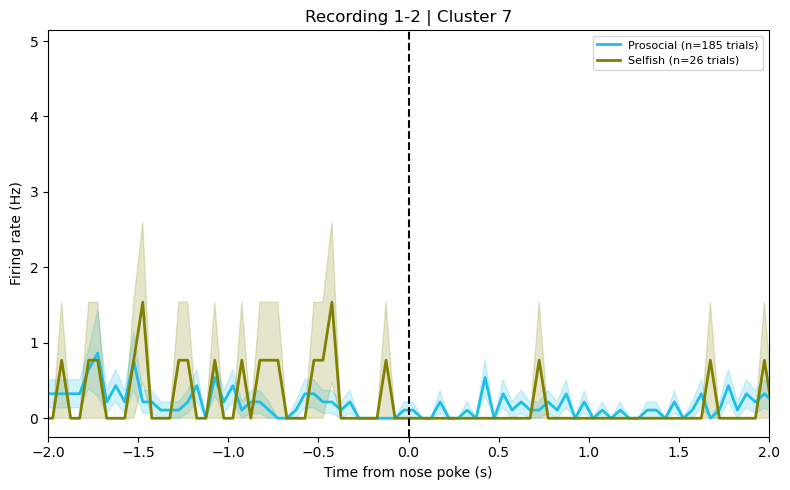

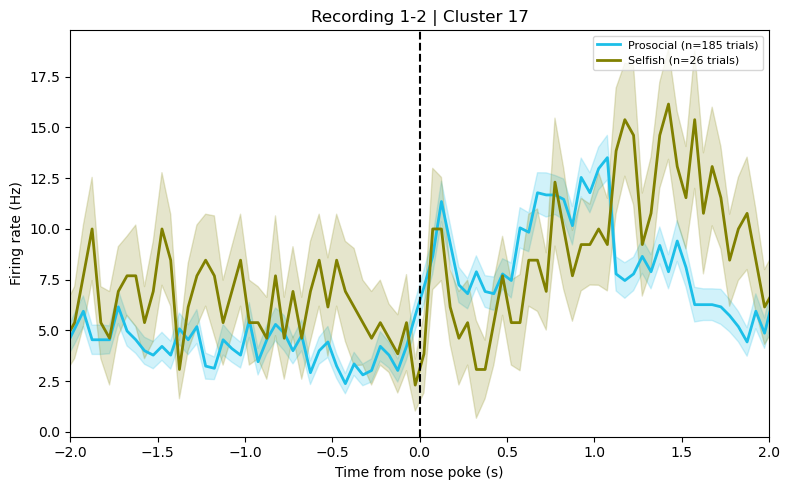

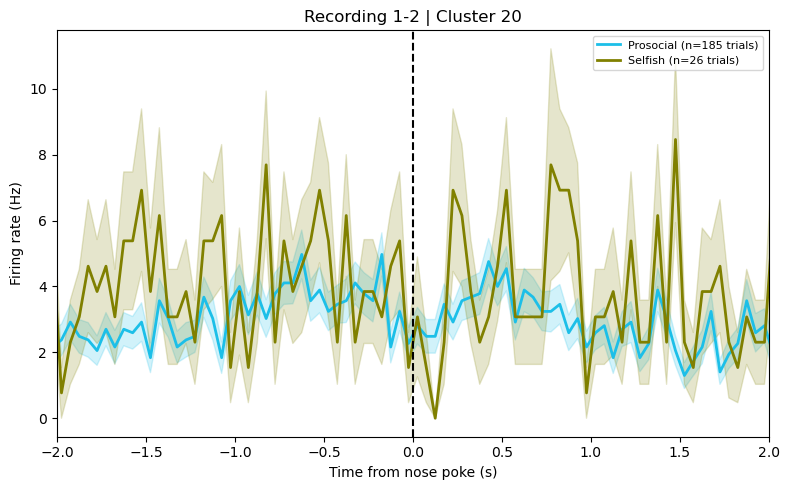

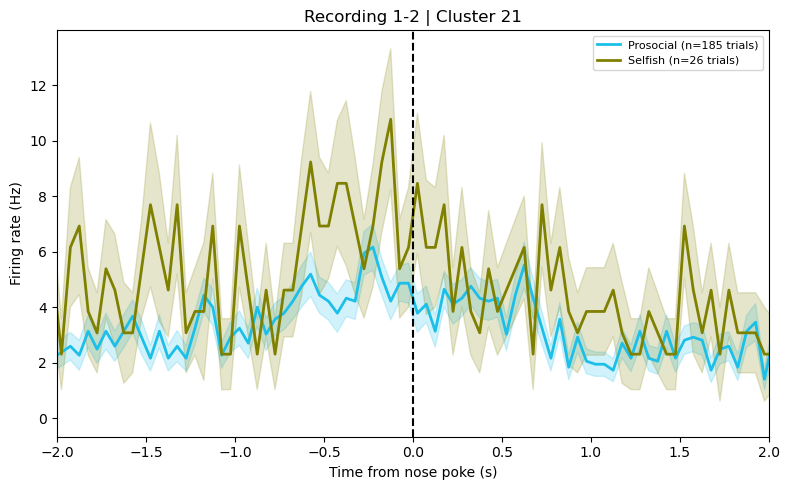

...

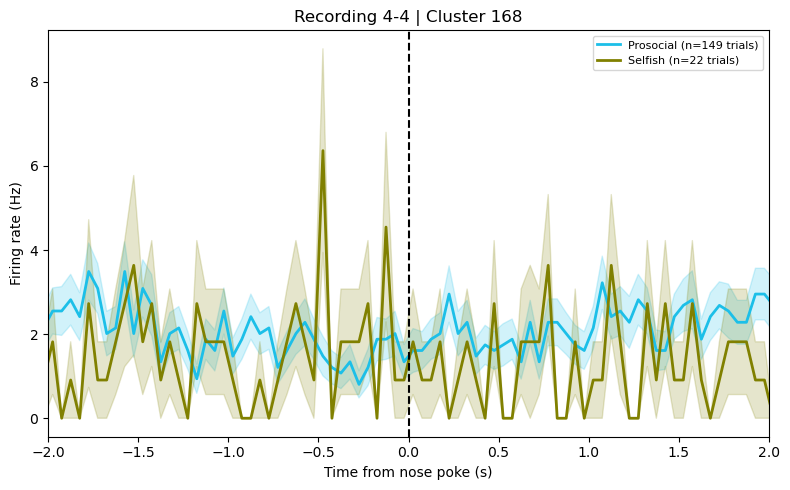

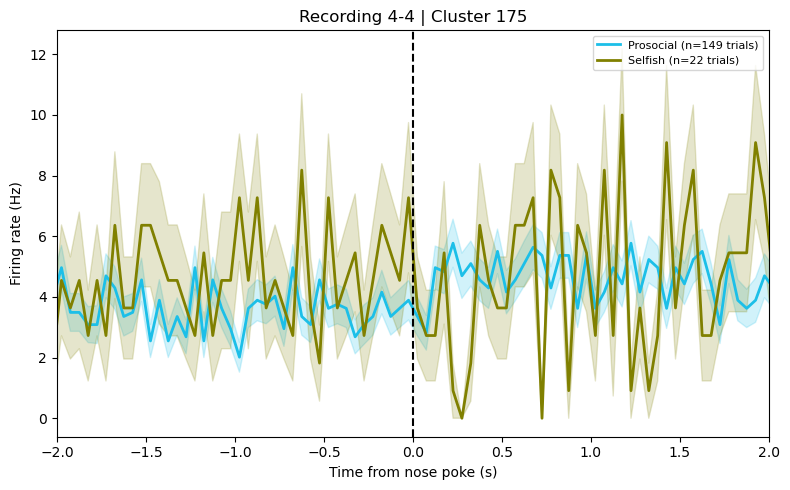

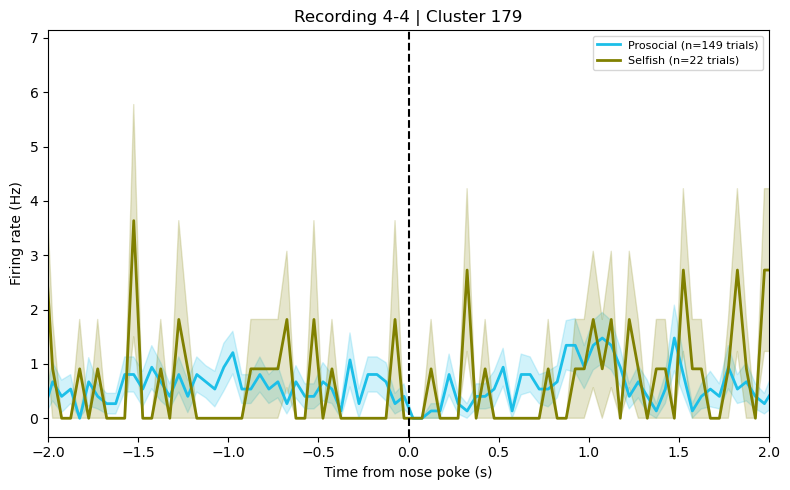

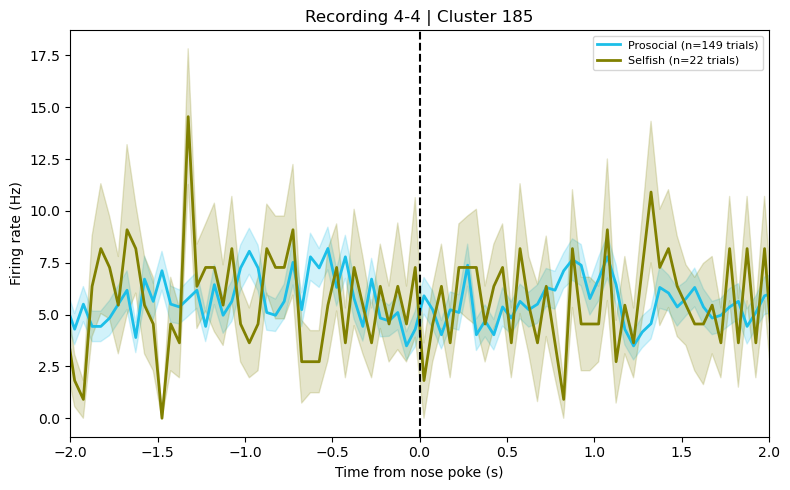

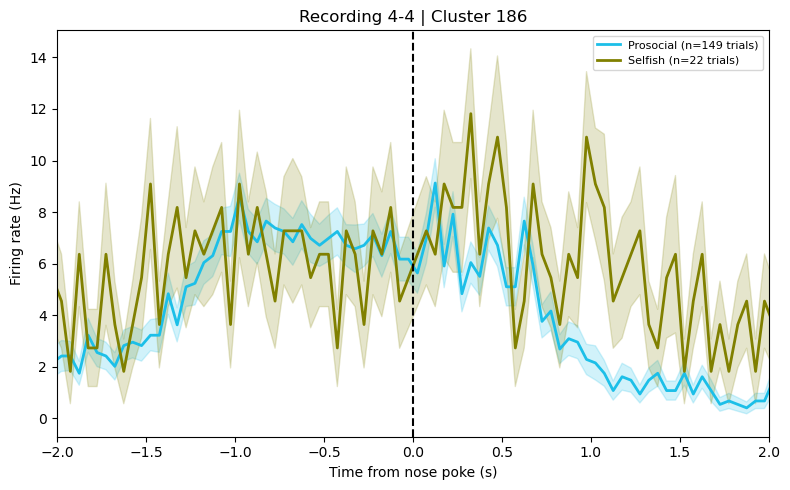

In [21]:
# ============================================
# PETH PER NEURON
# PROSOCIAL vs SELFISH
# MEAN ± SEM
# SHOW ALL - SAVE ONLY ONE SELECTED NEURON
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



# ============================================
# RECORDINGS
# ============================================

nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]


# ============================================
# PLOT ALL NEURONS
# ============================================

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        # ------------------------------------
        # Trial-by-trial firing rates
        # ------------------------------------

        pro_trials = data["prosocial_trials"]
        self_trials = data["selfish_trials"]

        # Mean
        pro_mean = np.mean(pro_trials, axis=0)
        self_mean = np.mean(self_trials, axis=0)

        # SEM across trials
        pro_sem = (
            np.std(pro_trials, axis=0, ddof=1)
            / np.sqrt(pro_trials.shape[0])
        )

        self_sem = (
            np.std(self_trials, axis=0, ddof=1)
            / np.sqrt(self_trials.shape[0])
        )


        # ------------------------------------
        # Plot
        # ------------------------------------

        fig, ax = plt.subplots(figsize=(8, 5))


        # Prosocial mean
        ax.plot(
            bin_centers,
            pro_mean,
            color="#1CBFE8",
            linewidth=2,
            label=f"Prosocial (n={pro_trials.shape[0]} trials)"
        )


        # Prosocial SEM
        ax.fill_between(
            bin_centers,
            pro_mean - pro_sem,
            pro_mean + pro_sem,
            color="#1CBFE8",
            alpha=0.20
        )


        # Selfish mean
        ax.plot(
            bin_centers,
            self_mean,
            color="#808000",
            linewidth=2,
            label=f"Selfish (n={self_trials.shape[0]} trials)"
        )


        # Selfish SEM
        ax.fill_between(
            bin_centers,
            self_mean - self_sem,
            self_mean + self_sem,
            color="#808000",
            alpha=0.20
        )


        # Nose poke onset
        ax.axvline(
            0,
            color="black",
            linestyle="--",
            linewidth=1.5
        )


        ax.set_xlim(-2, 2)

        ax.set_xlabel("Time from nose poke (s)")
        ax.set_ylabel("Firing rate (Hz)")

        ax.set_title(
            f"Recording {recording_id} | Cluster {cluster_id}"
        )

        ax.legend(fontsize=8)

        plt.tight_layout()


       

        # ====================================
        # SHOW ALL
        # ====================================

        plt.show()

In [22]:
# ============================================
# FUNCTION TO SAVE ONE SELECTED PETH
# ============================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def save_selected_peth(recording_id, cluster_id, save_location):

    data = peth_units_free[recording_id][cluster_id]

    pro_trials = data["prosocial_trials"]
    self_trials = data["selfish_trials"]

    # Mean
    pro_mean = np.mean(pro_trials, axis=0)
    self_mean = np.mean(self_trials, axis=0)

    # SEM
    pro_sem = (
        np.std(pro_trials, axis=0, ddof=1)
        / np.sqrt(pro_trials.shape[0])
    )

    self_sem = (
        np.std(self_trials, axis=0, ddof=1)
        / np.sqrt(self_trials.shape[0])
    )

    # ----------------------------------------
    # Plot
    # ----------------------------------------

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        bin_centers,
        pro_mean,
        color="#1CBFE8",
        linewidth=2,
        label=f"Prosocial (n={pro_trials.shape[0]} trials)"
    )

    ax.fill_between(
        bin_centers,
        pro_mean - pro_sem,
        pro_mean + pro_sem,
        color="#1CBFE8",
        alpha=0.20
    )

    ax.plot(
        bin_centers,
        self_mean,
        color="#808000",
        linewidth=2,
        label=f"Selfish (n={self_trials.shape[0]} trials)"
    )

    ax.fill_between(
        bin_centers,
        self_mean - self_sem,
        self_mean + self_sem,
        color="#808000",
        alpha=0.20
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_xlim(-2, 2)

    ax.set_xlabel("Time from nose poke (s)")
    ax.set_ylabel("Firing rate (Hz)")

    ax.set_title(
        f"Recording {recording_id} | Cluster {cluster_id}"
    )

    ax.legend(fontsize=8)

    plt.tight_layout()

    # ----------------------------------------
    # Save
    # ----------------------------------------

    save_location = Path(save_location)
    save_location.mkdir(parents=True, exist_ok=True)

    figure_name = (
        f"D8_Free_PETH_{recording_id}_"
        f"Cluster_{cluster_id}.png"
    )

    save_path = save_location / figure_name

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    print("Figure saved:")
    print(save_path)

    plt.show()

Figure saved:
C:\Cooperation project\Single_unit_pipeline\Results\D8_Free_PETH_1-2_Cluster_22.png


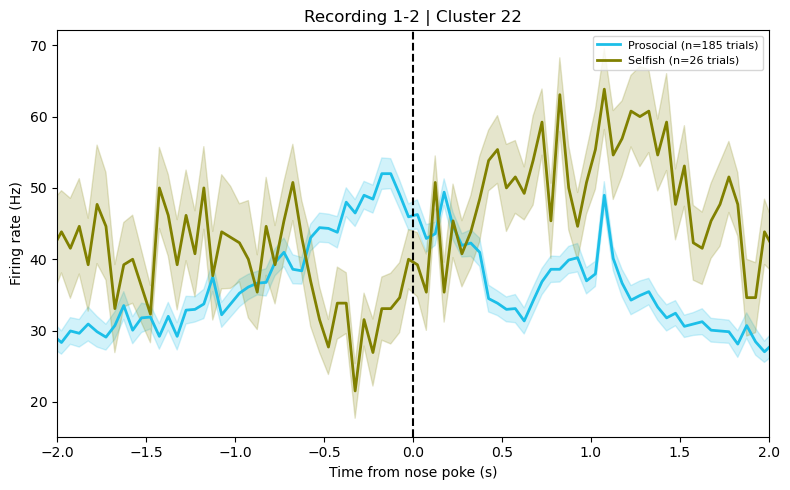

In [23]:
save_selected_peth(
    recording_id="1-2",
    cluster_id=22,
    save_location=r"C:\Cooperation project\Single_unit_pipeline\Results"
)

In [24]:
# ============================================================
# ANTICIPATORY ACTIVITY
# PETH-AVERAGED ANALYSIS
# Early: -2 to -1 s
# Late:  -1 to 0 s
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

alpha = 0.05

nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]

# ------------------------------------------------------------
# TIME WINDOWS
# ------------------------------------------------------------

early_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

late_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)

print("EARLY bins:")
print(bin_centers[early_mask])

print("\nLATE bins:")
print(bin_centers[late_mask])

print("\nEarly n bins:", early_mask.sum())
print("Late n bins:", late_mask.sum())


# ------------------------------------------------------------
# WILCOXON PER NEURON
# ------------------------------------------------------------

anticipatory_peth_results = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        # Mean PETH across all trials
        pro_peth = data["prosocial_mean"]
        self_peth = data["selfish_mean"]

        # ------------------------------------
        # PROSOCIAL
        # ------------------------------------

        pro_early = pro_peth[early_mask]
        pro_late = pro_peth[late_mask]

        try:
            stat_pro, p_pro = wilcoxon(
                pro_early,
                pro_late
            )
        except ValueError:
            stat_pro = np.nan
            p_pro = np.nan

        # ------------------------------------
        # SELFISH
        # ------------------------------------

        self_early = self_peth[early_mask]
        self_late = self_peth[late_mask]

        try:
            stat_self, p_self = wilcoxon(
                self_early,
                self_late
            )
        except ValueError:
            stat_self = np.nan
            p_self = np.nan

        # ------------------------------------
        # SAVE
        # ------------------------------------

        anticipatory_peth_results.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            "prosocial_early_mean": np.mean(pro_early),
            "prosocial_late_mean": np.mean(pro_late),
            "prosocial_p": p_pro,

            "selfish_early_mean": np.mean(self_early),
            "selfish_late_mean": np.mean(self_late),
            "selfish_p": p_self
        })


anticipatory_peth_results = pd.DataFrame(
    anticipatory_peth_results
)

print("\nTotal neurons:",
      len(anticipatory_peth_results))

EARLY bins:
[-1.975 -1.925 -1.875 -1.825 -1.775 -1.725 -1.675 -1.625 -1.575 -1.525
 -1.475 -1.425 -1.375 -1.325 -1.275 -1.225 -1.175 -1.125 -1.075 -1.025]

LATE bins:
[-0.975 -0.925 -0.875 -0.825 -0.775 -0.725 -0.675 -0.625 -0.575 -0.525
 -0.475 -0.425 -0.375 -0.325 -0.275 -0.225 -0.175 -0.125 -0.075 -0.025]

Early n bins: 20
Late n bins: 20

Total neurons: 69


c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


In [25]:
# ============================================================
# CLASSIFICATION
# ============================================================

def classify_condition(row):

    pro_sig = (
        not pd.isna(row["prosocial_p"])
        and row["prosocial_p"] < alpha
    )

    self_sig = (
        not pd.isna(row["selfish_p"])
        and row["selfish_p"] < alpha
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return "Prosocial only"

    elif self_sig:
        return "Selfish only"

    else:
        return "Non-regulated"


anticipatory_peth_results["classification"] = (
    anticipatory_peth_results.apply(
        classify_condition,
        axis=1
    )
)

print(
    anticipatory_peth_results["classification"]
    .value_counts()
)

classification
Prosocial only    24
Non-regulated     20
Both              17
Selfish only       8
Name: count, dtype: int64


Counts:
Prosocial only: 24
Selfish only: 8
Both: 17
Non-regulated: 20

Total: 69

Figure saved:
C:\Cooperation project\Single_unit_pipeline\Results\D8_Free_anticipatory_activity.png


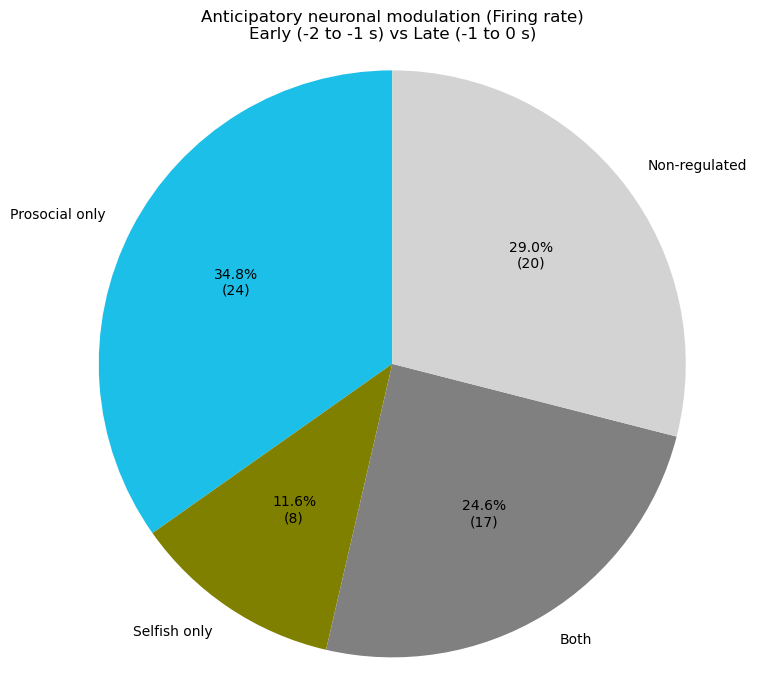

In [27]:
# ============================================================
# PIE CHART
# ANTICIPATORY ACTIVITY
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path


categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-regulated"
]

counts = [
    (
        anticipatory_peth_results["classification"]
        == category
    ).sum()
    for category in categories
]

colors = [
    "#1CBFE8",
    "#808000",
    "gray",
    "lightgray"
]


# ============================================================
# PRINT COUNTS
# ============================================================

print("Counts:")

for category, count in zip(categories, counts):
    print(f"{category}: {count}")

print("\nTotal:", sum(counts))


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

ax.pie(
    counts,
    labels=categories,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(counts)))})"
    ),
    startangle=90
)

ax.set_title(
    "Anticipatory neuronal modulation (Firing rate)\n"
    "Early (-2 to -1 s) vs Late (-1 to 0 s)"
)

ax.axis("equal")

plt.tight_layout()


# ============================================================
# SAVE FIGURE
# ============================================================

save_location = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Results"
)

figure_name = "D8_Free_anticipatory_activity.png"

save_path = save_location / figure_name

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure saved:")
print(save_path)


# ============================================================
# SHOW
# ============================================================

plt.show()

In [115]:
# ============================================================
# ANTICIPATORY ACTIVITY
# PETH-AVERAGED ANALYSIS
# Early: -2 to -1 s
# Late:  -1 to 0 s
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

alpha = 0.05

nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]

# ------------------------------------------------------------
# TIME WINDOWS
# ------------------------------------------------------------

early_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

late_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)


# ------------------------------------------------------------
# WILCOXON PER NEURON
# ------------------------------------------------------------

anticipatory_peth_results = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        pro_peth  = data["prosocial_mean"]
        self_peth = data["selfish_mean"]

        # ------------------------------------
        # PROSOCIAL
        # ------------------------------------

        pro_early = pro_peth[early_mask]
        pro_late  = pro_peth[late_mask]

        try:
            stat_pro, p_pro = wilcoxon(pro_early, pro_late)
        except ValueError:
            stat_pro = np.nan
            p_pro    = np.nan

        # ------------------------------------
        # SELFISH
        # ------------------------------------

        self_early = self_peth[early_mask]
        self_late  = self_peth[late_mask]

        try:
            stat_self, p_self = wilcoxon(self_early, self_late)
        except ValueError:
            stat_self = np.nan
            p_self    = np.nan

        # ------------------------------------
        # SAVE
        # ------------------------------------

        anticipatory_peth_results.append({

            "recording":  recording_id,
            "cluster_id": cluster_id,

            "prosocial_early_mean": np.mean(pro_early),
            "prosocial_late_mean":  np.mean(pro_late),
            "prosocial_p":          p_pro,

            "selfish_early_mean": np.mean(self_early),
            "selfish_late_mean":  np.mean(self_late),
            "selfish_p":          p_self
        })


anticipatory_peth_results = pd.DataFrame(
    anticipatory_peth_results
)

print("Total neurons:", len(anticipatory_peth_results))

c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


Total neurons: 69


In [116]:
# ============================================================
# CLASSIFICATION WITH DIRECTION
# ============================================================

def classify_anticipatory(row):

    pro_sig  = (
        not pd.isna(row["prosocial_p"])
        and row["prosocial_p"] < alpha
    )

    self_sig = (
        not pd.isna(row["selfish_p"])
        and row["selfish_p"] < alpha
    )

    # Direction: late > early = Increase
    pro_dir  = (
        "Increase"
        if row["prosocial_late_mean"] > row["prosocial_early_mean"]
        else "Decrease"
    )

    self_dir = (
        "Increase"
        if row["selfish_late_mean"] > row["selfish_early_mean"]
        else "Decrease"
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return f"Prosocial only — {pro_dir}"

    elif self_sig:
        return f"Selfish only — {self_dir}"

    else:
        return "Non-regulated"


anticipatory_peth_results["classification"] = (
    anticipatory_peth_results.apply(
        classify_anticipatory,
        axis=1
    )
)

print(
    anticipatory_peth_results["classification"]
    .value_counts()
)

classification
Non-regulated                20
Prosocial only — Increase    17
Both                         17
Prosocial only — Decrease     7
Selfish only — Decrease       4
Selfish only — Increase       4
Name: count, dtype: int64


Counts:
  Prosocial only — Increase: 17
  Prosocial only — Decrease: 7
  Selfish only — Increase: 4
  Selfish only — Decrease: 4
  Both: 17
  Non-regulated: 20

Total: 69


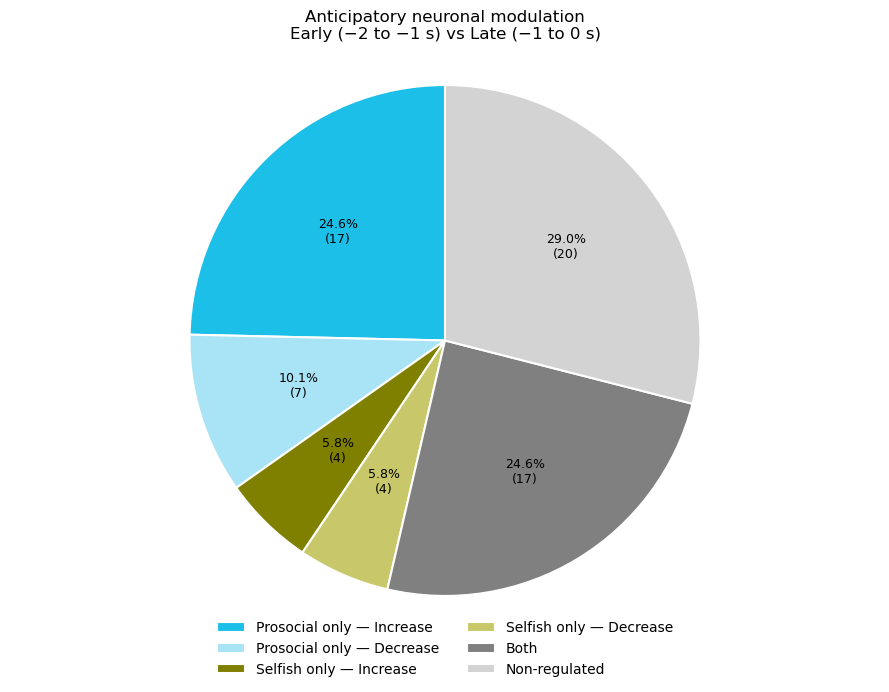

In [117]:
# ============================================================
# PIE CHART — 6 CATEGORIES
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path


# ------------------------------------------------------------
# CATEGORY ORDER + COUNTS
# ------------------------------------------------------------

category_order = [
    "Prosocial only — Increase",
    "Prosocial only — Decrease",
    "Selfish only — Increase",
    "Selfish only — Decrease",
    "Both",
    "Non-regulated"
]

counts = [
    (anticipatory_peth_results["classification"] == cat).sum()
    for cat in category_order
]

print("Counts:")
for cat, count in zip(category_order, counts):
    print(f"  {cat}: {count}")
print(f"\nTotal: {sum(counts)}")


# ------------------------------------------------------------
# COLORS
# ------------------------------------------------------------

colors = [
    "#1CBFE8",   # Prosocial Increase
    "#A8E4F5",   # Prosocial Decrease
    "#808000",   # Selfish Increase
    "#C8C86A",   # Selfish Decrease
    "gray",      # Both
    "lightgray"  # Non-regulated
]


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    counts,
    labels=None,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct / 100. * sum(counts)))})"
        if pct > 0 else ""
    ),
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

for autotext in autotexts:
    autotext.set_fontsize(9)

ax.legend(
    wedges,
    category_order,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
    fontsize=10
)

ax.set_title(
    "Anticipatory neuronal modulation\n"
    "Early (−2 to −1 s) vs Late (−1 to 0 s)",
    fontsize=12,
    pad=15
)

ax.axis("equal")
plt.tight_layout()


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

save_location = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Results"
)

fig.savefig(
    save_location / "D8_Free_anticipatory_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

trial per trial analysis

In [28]:
# ============================================================
# ANTICIPATORY ACTIVITY ANALYSIS
# Early Pre (-2 to -1 s) vs Late Pre (-1 to 0 s)
# Trial-by-trial Wilcoxon
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

alpha = 0.05

nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]


# ------------------------------------------------------------
# 2. DEFINE TIME WINDOWS
# ------------------------------------------------------------

early_pre_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

late_pre_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)


print("Early Pre bins:")
print(bin_centers[early_pre_mask])

print("\nLate Pre bins:")
print(bin_centers[late_pre_mask])

print("\nNumber Early Pre bins:", early_pre_mask.sum())
print("Number Late Pre bins:", late_pre_mask.sum())

Early Pre bins:
[-1.975 -1.925 -1.875 -1.825 -1.775 -1.725 -1.675 -1.625 -1.575 -1.525
 -1.475 -1.425 -1.375 -1.325 -1.275 -1.225 -1.175 -1.125 -1.075 -1.025]

Late Pre bins:
[-0.975 -0.925 -0.875 -0.825 -0.775 -0.725 -0.675 -0.625 -0.575 -0.525
 -0.475 -0.425 -0.375 -0.325 -0.275 -0.225 -0.175 -0.125 -0.075 -0.025]

Number Early Pre bins: 20
Number Late Pre bins: 20


In [29]:
# ============================================================
# 3. WILCOXON FOR EACH NEURON
# ============================================================

anticipatory_results = []


for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        # ====================================================
        # PROSOCIAL
        # ====================================================

        pro_trials = data["prosocial_trials"]

        # Mean firing rate for each trial
        # Early Pre: -2 to -1 s
        pro_early = np.mean(
            pro_trials[:, early_pre_mask],
            axis=1
        )

        # Late Pre: -1 to 0 s
        pro_late = np.mean(
            pro_trials[:, late_pre_mask],
            axis=1
        )


        # Wilcoxon paired across trials
        try:
            stat_pro, p_pro = wilcoxon(
                pro_early,
                pro_late
            )
        except ValueError:
            stat_pro = np.nan
            p_pro = np.nan


        # ====================================================
        # SELFISH
        # ====================================================

        self_trials = data["selfish_trials"]

        self_early = np.mean(
            self_trials[:, early_pre_mask],
            axis=1
        )

        self_late = np.mean(
            self_trials[:, late_pre_mask],
            axis=1
        )


        try:
            stat_self, p_self = wilcoxon(
                self_early,
                self_late
            )
        except ValueError:
            stat_self = np.nan
            p_self = np.nan


        # ====================================================
        # SAVE RESULTS
        # ====================================================

        anticipatory_results.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            # Prosocial
            "n_prosocial_trials": len(pro_early),

            "prosocial_early_mean":
                np.mean(pro_early),

            "prosocial_late_mean":
                np.mean(pro_late),

            "prosocial_wilcoxon_stat":
                stat_pro,

            "prosocial_p":
                p_pro,

            # Selfish
            "n_selfish_trials": len(self_early),

            "selfish_early_mean":
                np.mean(self_early),

            "selfish_late_mean":
                np.mean(self_late),

            "selfish_wilcoxon_stat":
                stat_self,

            "selfish_p":
                p_self
        })


anticipatory_results = pd.DataFrame(
    anticipatory_results
)


print("\nTotal neurons analyzed:",
      len(anticipatory_results))


Total neurons analyzed: 69


c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


In [30]:
# ============================================================
# 4. CLASSIFY ANTICIPATORY ACTIVITY
# ============================================================

def classify_anticipatory(
    early,
    late,
    pvalue,
    alpha=0.05
):

    if pd.isna(pvalue) or pvalue >= alpha:
        return "Non-significant"

    elif late > early:
        return "Increase"

    elif late < early:
        return "Decrease"

    else:
        return "No change"


# Prosocial
anticipatory_results["prosocial_anticipatory"] = (
    anticipatory_results.apply(
        lambda row: classify_anticipatory(
            row["prosocial_early_mean"],
            row["prosocial_late_mean"],
            row["prosocial_p"],
            alpha
        ),
        axis=1
    )
)


# Selfish
anticipatory_results["selfish_anticipatory"] = (
    anticipatory_results.apply(
        lambda row: classify_anticipatory(
            row["selfish_early_mean"],
            row["selfish_late_mean"],
            row["selfish_p"],
            alpha
        ),
        axis=1
    )
)

In [31]:
# ============================================================
# 5. SUMMARY
# ============================================================

print("================================")
print("PROSOCIAL")
print("================================")

print(
    anticipatory_results[
        "prosocial_anticipatory"
    ].value_counts()
)


print("\n================================")
print("SELFISH")
print("================================")

print(
    anticipatory_results[
        "selfish_anticipatory"
    ].value_counts()
)

PROSOCIAL
prosocial_anticipatory
Increase           29
Non-significant    27
Decrease           13
Name: count, dtype: int64

SELFISH
selfish_anticipatory
Non-significant    50
Increase           11
Decrease            8
Name: count, dtype: int64


In [32]:
# Prosocial anticipatory increase
pro_anticipatory_increase = anticipatory_results[
    anticipatory_results["prosocial_anticipatory"]
    == "Increase"
]

print("PROSOCIAL ANTICIPATORY INCREASE")
print(
    pro_anticipatory_increase[
        [
            "recording",
            "cluster_id",
            "prosocial_early_mean",
            "prosocial_late_mean",
            "prosocial_p"
        ]
    ].to_string(index=False)
)


# Selfish anticipatory increase
self_anticipatory_increase = anticipatory_results[
    anticipatory_results["selfish_anticipatory"]
    == "Increase"
]

print("\nSELFISH ANTICIPATORY INCREASE")
print(
    self_anticipatory_increase[
        [
            "recording",
            "cluster_id",
            "selfish_early_mean",
            "selfish_late_mean",
            "selfish_p"
        ]
    ].to_string(index=False)
)

PROSOCIAL ANTICIPATORY INCREASE
recording  cluster_id  prosocial_early_mean  prosocial_late_mean  prosocial_p
      1-2          20              2.643243             3.637838 1.774816e-07
      1-2          21              2.870270             4.329730 3.874606e-10
      1-2          22             31.454054            43.437838 1.555456e-22
      1-2          24              2.097297             2.659459 1.840459e-04
      1-2          40              0.475676             0.670270 9.375927e-03
      1-2          61             14.945946            18.859459 4.519826e-23
      1-2          62              2.372973             5.772973 4.130891e-25
      1-2          83              7.875676            12.394595 1.489197e-20
      2-4           4              0.173516             0.716895 3.364685e-07
      2-4          49              0.301370             0.493151 4.928791e-02
      2-4          58              1.333333             3.242009 6.166950e-14
      2-4          83           

Counts:
Prosocial only: 28
Selfish only: 5
Both: 14
Non-regulated: 22

Total neurons: 69


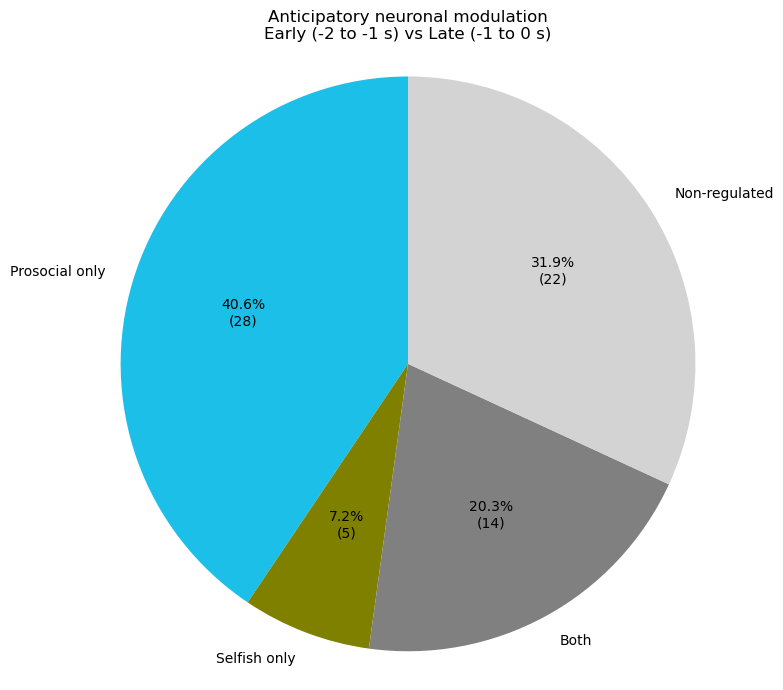

In [33]:
# ============================================
# CLASSIFICATION:
# PROSOCIAL / SELFISH / BOTH / NON-REGULATED
# Anticipatory activity
# ============================================

def classify_condition(row):

    pro_sig = (
        not pd.isna(row["prosocial_p"])
        and row["prosocial_p"] < alpha
    )

    self_sig = (
        not pd.isna(row["selfish_p"])
        and row["selfish_p"] < alpha
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return "Prosocial only"

    elif self_sig:
        return "Selfish only"

    else:
        return "Non-regulated"


anticipatory_results["classification"] = (
    anticipatory_results.apply(
        classify_condition,
        axis=1
    )
)


# ============================================
# COUNTS
# ============================================

categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-regulated"
]

counts = [
    (anticipatory_results["classification"] == category).sum()
    for category in categories
]

print("Counts:")

for category, count in zip(categories, counts):
    print(f"{category}: {count}")

print("\nTotal neurons:", sum(counts))


# ============================================
# PIE CHART
# ============================================

import matplotlib.pyplot as plt

colors = [
    "#1CBFE8",   # Prosocial
    "#808000",   # Selfish
    "gray",      # Both
    "lightgray"  # Non-regulated
]

plt.figure(figsize=(8, 7))

plt.pie(
    counts,
    labels=categories,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(counts)))})"
    ),
    startangle=90
)

plt.title(
    "Anticipatory neuronal modulation\n"
    "Early (-2 to -1 s) vs Late (-1 to 0 s)"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

PROSOCIAL: {'Increase': 29, 'Decrease': 13, 'Non-significant': 27}
SELFISH: {'Increase': 11, 'Decrease': 8, 'Non-significant': 50}


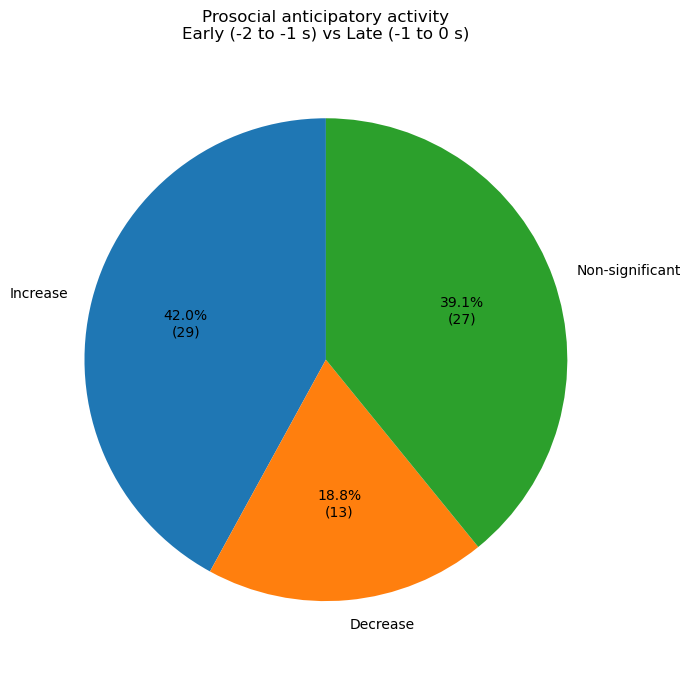

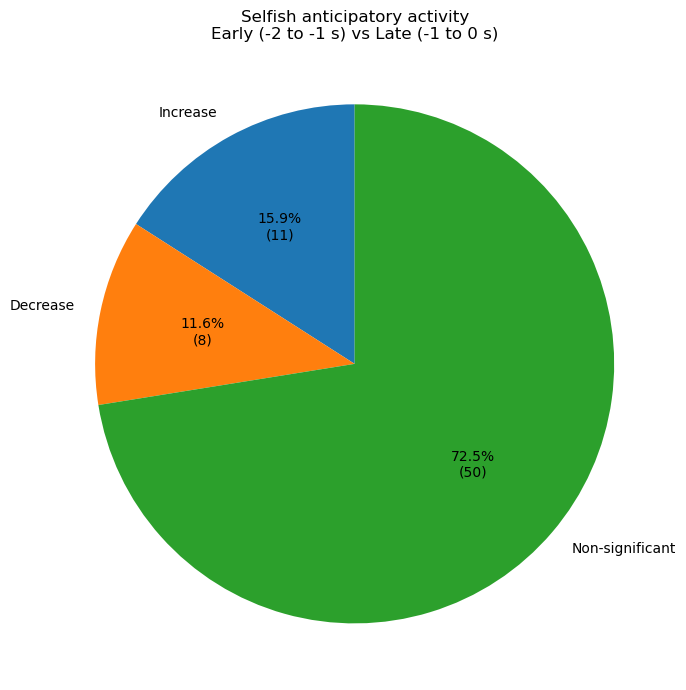

In [34]:
# ============================================
# PIE CHARTS - ANTICIPATORY ACTIVITY
# Early (-2 to -1 s) vs Late (-1 to 0 s)
# ============================================

import matplotlib.pyplot as plt

categories = [
    "Increase",
    "Decrease",
    "Non-significant"
]

# --------------------------------------------
# COUNTS
# --------------------------------------------

pro_counts = [
    (anticipatory_results["prosocial_anticipatory"] == cat).sum()
    for cat in categories
]

self_counts = [
    (anticipatory_results["selfish_anticipatory"] == cat).sum()
    for cat in categories
]

print("PROSOCIAL:", dict(zip(categories, pro_counts)))
print("SELFISH:", dict(zip(categories, self_counts)))


# ============================================
# PROSOCIAL PIE
# ============================================

plt.figure(figsize=(7, 7))

plt.pie(
    pro_counts,
    labels=categories,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(pro_counts)))})"
    ),
    startangle=90
)

plt.title(
    "Prosocial anticipatory activity\n"
    "Early (-2 to -1 s) vs Late (-1 to 0 s)"
)

plt.axis("equal")
plt.tight_layout()
plt.show()


# ============================================
# SELFISH PIE
# ============================================

plt.figure(figsize=(7, 7))

plt.pie(
    self_counts,
    labels=categories,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(self_counts)))})"
    ),
    startangle=90
)

plt.title(
    "Selfish anticipatory activity\n"
    "Early (-2 to -1 s) vs Late (-1 to 0 s)"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

In [35]:
# ============================================================
# PRE vs POST ACTIVITY
# Pre:  -1 to 0 s
# Post:  0 to 1 s
# Trial-by-trial Wilcoxon
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

alpha = 0.05

nosepoke_recordings = [
    "1-2",
    "2-4",
    "4-3",
    "4-4"
]

# Time windows
pre_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)

post_mask = (
    (bin_centers >= 0.0) &
    (bin_centers < 1.0)
)

print("PRE bins:")
print(bin_centers[pre_mask])

print("\nPOST bins:")
print(bin_centers[post_mask])

print("\nNumber PRE bins:", pre_mask.sum())
print("Number POST bins:", post_mask.sum())

PRE bins:
[-0.975 -0.925 -0.875 -0.825 -0.775 -0.725 -0.675 -0.625 -0.575 -0.525
 -0.475 -0.425 -0.375 -0.325 -0.275 -0.225 -0.175 -0.125 -0.075 -0.025]

POST bins:
[0.025 0.075 0.125 0.175 0.225 0.275 0.325 0.375 0.425 0.475 0.525 0.575
 0.625 0.675 0.725 0.775 0.825 0.875 0.925 0.975]

Number PRE bins: 20
Number POST bins: 20


In [36]:
# ============================================================
# WILCOXON PER NEURON
# ============================================================

prepost_results = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        # ====================================================
        # PROSOCIAL
        # ====================================================

        pro_trials = data["prosocial_trials"]

        pro_pre = np.mean(
            pro_trials[:, pre_mask],
            axis=1
        )

        pro_post = np.mean(
            pro_trials[:, post_mask],
            axis=1
        )

        try:
            stat_pro, p_pro = wilcoxon(
                pro_pre,
                pro_post
            )
        except ValueError:
            stat_pro = np.nan
            p_pro = np.nan


        # ====================================================
        # SELFISH
        # ====================================================

        self_trials = data["selfish_trials"]

        self_pre = np.mean(
            self_trials[:, pre_mask],
            axis=1
        )

        self_post = np.mean(
            self_trials[:, post_mask],
            axis=1
        )

        try:
            stat_self, p_self = wilcoxon(
                self_pre,
                self_post
            )
        except ValueError:
            stat_self = np.nan
            p_self = np.nan


        # ====================================================
        # SAVE
        # ====================================================

        prepost_results.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            # Prosocial
            "n_prosocial_trials": len(pro_pre),
            "prosocial_pre_mean": np.mean(pro_pre),
            "prosocial_post_mean": np.mean(pro_post),
            "prosocial_stat": stat_pro,
            "prosocial_p": p_pro,

            # Selfish
            "n_selfish_trials": len(self_pre),
            "selfish_pre_mean": np.mean(self_pre),
            "selfish_post_mean": np.mean(self_post),
            "selfish_stat": stat_self,
            "selfish_p": p_self
        })


prepost_results = pd.DataFrame(prepost_results)

print("Total neurons:", len(prepost_results))

Total neurons: 69


c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


In [37]:
# ============================================================
# CONDITION CLASSIFICATION
# ============================================================

def classify_prepost(row):

    pro_sig = (
        not pd.isna(row["prosocial_p"])
        and row["prosocial_p"] < alpha
    )

    self_sig = (
        not pd.isna(row["selfish_p"])
        and row["selfish_p"] < alpha
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return "Prosocial only"

    elif self_sig:
        return "Selfish only"

    else:
        return "Non-regulated"


prepost_results["classification"] = (
    prepost_results.apply(
        classify_prepost,
        axis=1
    )
)

print(
    prepost_results["classification"]
    .value_counts()
)

classification
Prosocial only    32
Non-regulated     25
Both               9
Selfish only       3
Name: count, dtype: int64


Counts:
Prosocial only: 32
Selfish only: 3
Both: 9
Non-regulated: 25

Total: 69


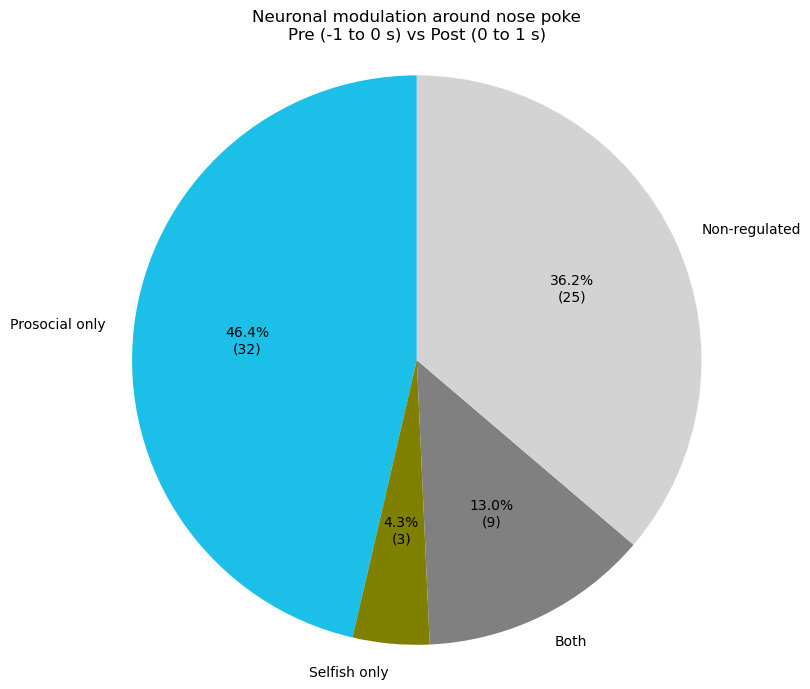

In [38]:
# ============================================================
# PIE CHART
# PRE (-1 to 0) vs POST (0 to 1)
# ============================================================

import matplotlib.pyplot as plt

categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-regulated"
]

counts = [
    (prepost_results["classification"] == category).sum()
    for category in categories
]

print("Counts:")

for category, count in zip(categories, counts):
    print(f"{category}: {count}")

print("\nTotal:", sum(counts))


colors = [
    "#1CBFE8",
    "#808000",
    "gray",
    "lightgray"
]

plt.figure(figsize=(8, 7))

plt.pie(
    counts,
    labels=categories,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(counts)))})"
    ),
    startangle=90
)

plt.title(
    "Neuronal modulation around nose poke\n"
    "Pre (-1 to 0 s) vs Post (0 to 1 s)"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

Zscore analisys

In [125]:
# ============================================================
# CHECK TRIAL-BY-TRIAL BASELINE VARIABILITY
# Baseline: -2 to -1 s
# ============================================================

import numpy as np
import pandas as pd

baseline_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

print("Baseline bins:")
print(bin_centers[baseline_mask])

print("Number of bins:", baseline_mask.sum())

Baseline bins:
[-1.975 -1.925 -1.875 -1.825 -1.775 -1.725 -1.675 -1.625 -1.575 -1.525
 -1.475 -1.425 -1.375 -1.325 -1.275 -1.225 -1.175 -1.125 -1.075 -1.025]
Number of bins: 20


In [127]:
baseline_check = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        # Trial x time-bin matrices Usamos este codigo para ver si hacer la normalizacion funcionaba tomando trial per trial pero encontramos varios SD con valores de 0. Por eso obtamos por hacer la normalizacion haciendo average de trials y luego zscore
        pro_trials = data["prosocial_trials"]
        self_trials = data["selfish_trials"]

        # ---------------------------------------
        # PROSOCIAL
        # ---------------------------------------

        for trial_idx in range(pro_trials.shape[0]):

            baseline_values = pro_trials[
                trial_idx,
                baseline_mask
            ]

            baseline_sd = np.std(
                baseline_values,
                ddof=1
            )

            baseline_mean = np.mean(
                baseline_values
            )

            baseline_check.append({
                "recording": recording_id,
                "cluster_id": cluster_id,
                "condition": "Prosocial",
                "trial": trial_idx,
                "baseline_mean": baseline_mean,
                "baseline_sd": baseline_sd
            })

        # ---------------------------------------
        # SELFISH
        # ---------------------------------------

        for trial_idx in range(self_trials.shape[0]):

            baseline_values = self_trials[
                trial_idx,
                baseline_mask
            ]

            baseline_sd = np.std(
                baseline_values,
                ddof=1
            )

            baseline_mean = np.mean(
                baseline_values
            )

            baseline_check.append({
                "recording": recording_id,
                "cluster_id": cluster_id,
                "condition": "Selfish",
                "trial": trial_idx,
                "baseline_mean": baseline_mean,
                "baseline_sd": baseline_sd
            })


baseline_check = pd.DataFrame(baseline_check)

In [128]:
print("Total neuron-trials:")
print(len(baseline_check))

print("\nSD = 0:")
print((baseline_check["baseline_sd"] == 0).sum())

print("\nPercentage SD = 0:")
print(
    100 *
    (baseline_check["baseline_sd"] == 0).mean()
)

Total neuron-trials:
13436

SD = 0:
5489

Percentage SD = 0:
40.8529324203632


In [129]:
# ============================================================
# CHECK BASELINE SD FROM MEAN PETH
# Baseline: -2 to -1 s
# Prosocial and Selfish separately
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# BASELINE WINDOW
# ------------------------------------------------------------

baseline_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

print("Baseline bins:")
print(bin_centers[baseline_mask])

print("\nNumber of baseline bins:",
      baseline_mask.sum())


# ------------------------------------------------------------
# CHECK EACH NEURON
# ------------------------------------------------------------

baseline_peth_check = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_free[recording_id].items():

        # Mean PETH across ALL trials
        pro_peth = data["prosocial_mean"]
        self_peth = data["selfish_mean"]

        # ------------------------------------
        # PROSOCIAL BASELINE
        # ------------------------------------

        pro_baseline = pro_peth[baseline_mask]

        pro_baseline_mean = np.mean(pro_baseline)
        pro_baseline_sd = np.std(
            pro_baseline,
            ddof=1
        )

        # ------------------------------------
        # SELFISH BASELINE
        # ------------------------------------

        self_baseline = self_peth[baseline_mask]

        self_baseline_mean = np.mean(self_baseline)
        self_baseline_sd = np.std(
            self_baseline,
            ddof=1
        )

        # ------------------------------------
        # SAVE
        # ------------------------------------

        baseline_peth_check.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            "prosocial_baseline_mean":
                pro_baseline_mean,

            "prosocial_baseline_sd":
                pro_baseline_sd,

            "selfish_baseline_mean":
                self_baseline_mean,

            "selfish_baseline_sd":
                self_baseline_sd
        })


baseline_peth_check = pd.DataFrame(
    baseline_peth_check
)

print("\nTotal neurons:",
      len(baseline_peth_check))

Baseline bins:
[-1.975 -1.925 -1.875 -1.825 -1.775 -1.725 -1.675 -1.625 -1.575 -1.525
 -1.475 -1.425 -1.375 -1.325 -1.275 -1.225 -1.175 -1.125 -1.075 -1.025]

Number of baseline bins: 20

Total neurons: 69


In [130]:
# ============================================================
# HOW MANY NEURONS HAVE BASELINE SD = 0?
# ============================================================

pro_zero = (
    baseline_peth_check["prosocial_baseline_sd"] == 0
).sum()

self_zero = (
    baseline_peth_check["selfish_baseline_sd"] == 0
).sum()

n_neurons = len(baseline_peth_check)


print("PROSOCIAL")
print("SD = 0:", pro_zero)
print(
    "Percentage:",
    100 * pro_zero / n_neurons
)


print("\nSELFISH")
print("SD = 0:", self_zero)
print(
    "Percentage:",
    100 * self_zero / n_neurons
)

# ============================================================
# FILTER UNITS WITH VALID BASELINE SD
# For z-score based analyses
# ============================================================

valid_zscore_units = baseline_peth_check[
    (baseline_peth_check["prosocial_baseline_sd"] > 0) &
    (baseline_peth_check["selfish_baseline_sd"] > 0)
].copy()

invalid_zscore_units = baseline_peth_check[
    (baseline_peth_check["prosocial_baseline_sd"] == 0) |
    (baseline_peth_check["selfish_baseline_sd"] == 0)
].copy()


print("====================================")
print("Z-SCORE QC")
print("====================================")

print("Total units:", len(baseline_peth_check))
print("Valid units:", len(valid_zscore_units))
print("Excluded units:", len(invalid_zscore_units))

print("\nExcluded units:")
print(
    invalid_zscore_units[
        [
            "recording",
            "cluster_id",
            "prosocial_baseline_sd",
            "selfish_baseline_sd"
        ]
    ].to_string(index=False)
)

PROSOCIAL
SD = 0: 0
Percentage: 0.0

SELFISH
SD = 0: 2
Percentage: 2.898550724637681
Z-SCORE QC
Total units: 69
Valid units: 67
Excluded units: 2

Excluded units:
recording  cluster_id  prosocial_baseline_sd  selfish_baseline_sd
      2-4           4               0.162017                  0.0
      2-4         109               0.341543                  0.0


In [132]:
# ============================================================
# CREATE SET OF VALID UNIT IDs
# ============================================================

valid_zscore_ids = set(
    zip(
        valid_zscore_units["recording"],
        valid_zscore_units["cluster_id"]
    )
)

print("\nNumber of valid unit IDs:", len(valid_zscore_ids))


Number of valid unit IDs: 67


In [133]:
print("PROSOCIAL baseline SD:")
print(
    baseline_peth_check[
        "prosocial_baseline_sd"
    ].describe()
)

print("\nSELFISH baseline SD:")
print(
    baseline_peth_check[
        "selfish_baseline_sd"
    ].describe()
)

PROSOCIAL baseline SD:
count    69.000000
mean      0.617095
std       0.523124
min       0.086891
25%       0.298656
50%       0.442636
75%       0.793275
max       2.744170
Name: prosocial_baseline_sd, dtype: float64

SELFISH baseline SD:
count    69.000000
mean      1.294892
std       0.976174
min       0.000000
25%       0.650164
50%       1.032031
75%       1.634645
max       4.981904
Name: selfish_baseline_sd, dtype: float64


In [134]:
# ============================================================
# Z-SCORE NORMALIZATION
# FREE TRIALS
# ONLY UNITS WITH VALID BASELINE SD
# ============================================================

peth_units_z_free = {}

for recording_id in nosepoke_recordings:

    peth_units_z_free[recording_id] = {}

    for cluster_id, data in peth_units_free[recording_id].items():

        # ------------------------------------
        # QC FILTER
        # ------------------------------------
        if (recording_id, cluster_id) not in valid_zscore_ids:
            continue

        # ------------------------------------
        # Mean PETH
        # ------------------------------------
        pro_peth = data["prosocial_mean"]
        self_peth = data["selfish_mean"]

        # ------------------------------------
        # Baseline
        # ------------------------------------
        pro_baseline = pro_peth[baseline_mask]
        self_baseline = self_peth[baseline_mask]

        pro_baseline_mean = np.mean(pro_baseline)
        pro_baseline_sd = np.std(
            pro_baseline,
            ddof=1
        )

        self_baseline_mean = np.mean(self_baseline)
        self_baseline_sd = np.std(
            self_baseline,
            ddof=1
        )

        # ------------------------------------
        # Z-SCORE
        # ------------------------------------
        pro_z = (
            pro_peth - pro_baseline_mean
        ) / pro_baseline_sd

        self_z = (
            self_peth - self_baseline_mean
        ) / self_baseline_sd

        # ------------------------------------
        # STORE
        # ------------------------------------
        peth_units_z_free[recording_id][cluster_id] = {

            "prosocial_mean_z": pro_z,
            "selfish_mean_z": self_z,

            "prosocial_baseline_mean":
                pro_baseline_mean,

            "prosocial_baseline_sd":
                pro_baseline_sd,

            "selfish_baseline_mean":
                self_baseline_mean,

            "selfish_baseline_sd":
                self_baseline_sd
        }


# ============================================================
# CHECK
# ============================================================

n_zscore_units = sum(
    len(units)
    for units in peth_units_z_free.values()
)

print("Units included in z-score analysis:", n_zscore_units)

Units included in z-score analysis: 67


In [135]:
recording_id = "1-2"
cluster_id = 61

print("Prosocial baseline z mean:")
print(
    np.mean(
        peth_units_z_free[recording_id][cluster_id]
        ["prosocial_mean_z"][baseline_mask]
    )
)

print("Selfish baseline z mean:")
print(
    np.mean(
        peth_units_z_free[recording_id][cluster_id]
        ["selfish_mean_z"][baseline_mask]
    )
)

Prosocial baseline z mean:
6.7723604502134545e-16
Selfish baseline z mean:
-1.7763568394002506e-16


In [136]:
print("Prosocial baseline z SD:")
print(
    np.std(
        peth_units_z_free["1-2"][61]
        ["prosocial_mean_z"][baseline_mask],
        ddof=1
    )
)

print("Selfish baseline z SD:")
print(
    np.std(
        peth_units_z_free["1-2"][61]
        ["selfish_mean_z"][baseline_mask],
        ddof=1
    )
)

Prosocial baseline z SD:
0.9999999999999999
Selfish baseline z SD:
1.0000000000000002


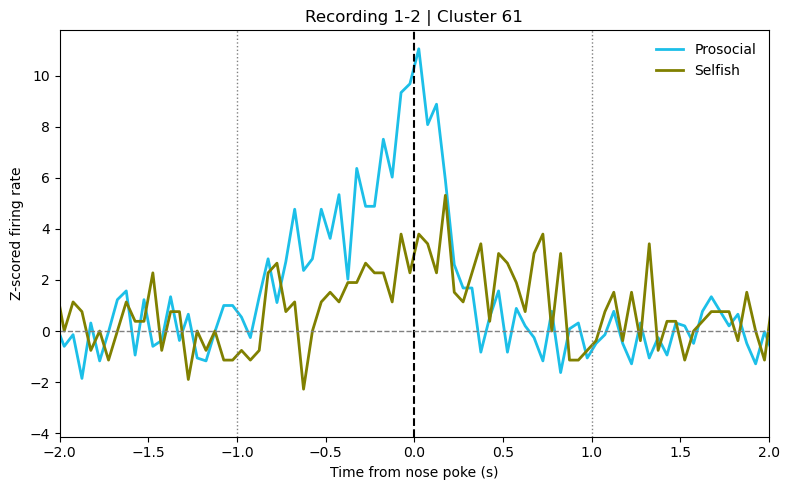

In [137]:
recording_id = "1-2"
cluster_id = 61

pro_z = peth_units_z_free[recording_id][cluster_id]["prosocial_mean_z"]
self_z = peth_units_z_free[recording_id][cluster_id]["selfish_mean_z"]

plt.figure(figsize=(8, 5))

plt.plot(
    bin_centers,
    pro_z,
    color="#1CBFE8",
    linewidth=2,
    label="Prosocial"
)

plt.plot(
    bin_centers,
    self_z,
    color="#808000",
    linewidth=2,
    label="Selfish"
)

# Nose poke
plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

# Window boundaries
plt.axvline(-1, color="gray", linestyle=":", linewidth=1)
plt.axvline(1, color="gray", linestyle=":", linewidth=1)

# Baseline reference
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.xlim(-2, 2)

plt.xlabel("Time from nose poke (s)")
plt.ylabel("Z-scored firing rate")

plt.title(
    f"Recording {recording_id} | Cluster {cluster_id}"
)

plt.legend(frameon=False)

plt.tight_layout()
plt.show()

In [138]:
# ============================================================
# TIME WINDOWS
# 50 ms bins
# ============================================================

baseline_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

anticipatory_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)

post_mask = (
    (bin_centers >= 0.0) &
    (bin_centers < 1.0)
)

print("Baseline bins:", baseline_mask.sum())
print("Anticipatory bins:", anticipatory_mask.sum())
print("Post-NP bins:", post_mask.sum())

Baseline bins: 20
Anticipatory bins: 20
Post-NP bins: 20


In [139]:
# ============================================================
# BASELINE vs ANTICIPATORY
# BASELINE vs POST-NOSE-POKE
#
# Separate analyses for Prosocial and Selfish
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

alpha = 0.05

modulation_results = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_z_free[recording_id].items():

        # ====================================================
        # QC FILTER
        # Exclude units with baseline SD = 0
        # ====================================================

        if (recording_id, cluster_id) not in valid_zscore_ids:
            continue

        pro_z = data["prosocial_mean_z"]
        self_z = data["selfish_mean_z"]

        # ====================================================
        # PROSOCIAL
        # ====================================================

        pro_baseline = pro_z[baseline_mask]
        pro_anticipatory = pro_z[anticipatory_mask]
        pro_post = pro_z[post_mask]

        # Baseline vs Anticipatory
        try:
            stat_pro_ant, p_pro_ant = wilcoxon(
                pro_baseline,
                pro_anticipatory
            )
        except ValueError:
            stat_pro_ant = np.nan
            p_pro_ant = np.nan

        # Baseline vs Post-NP
        try:
            stat_pro_post, p_pro_post = wilcoxon(
                pro_baseline,
                pro_post
            )
        except ValueError:
            stat_pro_post = np.nan
            p_pro_post = np.nan


        # ====================================================
        # SELFISH
        # ====================================================

        self_baseline = self_z[baseline_mask]
        self_anticipatory = self_z[anticipatory_mask]
        self_post = self_z[post_mask]

        # Baseline vs Anticipatory
        try:
            stat_self_ant, p_self_ant = wilcoxon(
                self_baseline,
                self_anticipatory
            )
        except ValueError:
            stat_self_ant = np.nan
            p_self_ant = np.nan

        # Baseline vs Post-NP
        try:
            stat_self_post, p_self_post = wilcoxon(
                self_baseline,
                self_post
            )
        except ValueError:
            stat_self_post = np.nan
            p_self_post = np.nan


        # ====================================================
        # SAVE
        # ====================================================

        modulation_results.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            # Prosocial means
            "pro_baseline": np.mean(pro_baseline),
            "pro_anticipatory": np.mean(pro_anticipatory),
            "pro_post": np.mean(pro_post),

            # Prosocial p-values
            "pro_ant_p": p_pro_ant,
            "pro_post_p": p_pro_post,

            # Selfish means
            "self_baseline": np.mean(self_baseline),
            "self_anticipatory": np.mean(self_anticipatory),
            "self_post": np.mean(self_post),

            # Selfish p-values
            "self_ant_p": p_self_ant,
            "self_post_p": p_self_post
        })


modulation_results = pd.DataFrame(modulation_results)

print("Total neurons:", len(modulation_results))

c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
c:\Users\illes\anaconda3\Lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


Total neurons: 67


In [140]:
# ============================================================
# DIRECTION OF MODULATION
# ============================================================

def get_direction(baseline, period, p, alpha=0.05):

    if pd.isna(p) or p >= alpha:
        return "Non-significant"

    elif period > baseline:
        return "Increase"

    elif period < baseline:
        return "Decrease"

    else:
        return "No change"


# Prosocial anticipatory
modulation_results["pro_ant_direction"] = (
    modulation_results.apply(
        lambda row: get_direction(
            row["pro_baseline"],
            row["pro_anticipatory"],
            row["pro_ant_p"]
        ),
        axis=1
    )
)

# Prosocial post
modulation_results["pro_post_direction"] = (
    modulation_results.apply(
        lambda row: get_direction(
            row["pro_baseline"],
            row["pro_post"],
            row["pro_post_p"]
        ),
        axis=1
    )
)

# Selfish anticipatory
modulation_results["self_ant_direction"] = (
    modulation_results.apply(
        lambda row: get_direction(
            row["self_baseline"],
            row["self_anticipatory"],
            row["self_ant_p"]
        ),
        axis=1
    )
)

# Selfish post
modulation_results["self_post_direction"] = (
    modulation_results.apply(
        lambda row: get_direction(
            row["self_baseline"],
            row["self_post"],
            row["self_post_p"]
        ),
        axis=1
    )
)

In [141]:
print("PROSOCIAL - ANTICIPATORY")
print(
    modulation_results["pro_ant_direction"]
    .value_counts()
)

print("\nPROSOCIAL - POST-NP")
print(
    modulation_results["pro_post_direction"]
    .value_counts()
)

print("\nSELFISH - ANTICIPATORY")
print(
    modulation_results["self_ant_direction"]
    .value_counts()
)

print("\nSELFISH - POST-NP")
print(
    modulation_results["self_post_direction"]
    .value_counts()
)

PROSOCIAL - ANTICIPATORY
pro_ant_direction
Non-significant    28
Increase           28
Decrease           11
Name: count, dtype: int64

PROSOCIAL - POST-NP
pro_post_direction
Non-significant    25
Increase           22
Decrease           20
Name: count, dtype: int64

SELFISH - ANTICIPATORY
self_ant_direction
Non-significant    42
Increase           15
Decrease           10
Name: count, dtype: int64

SELFISH - POST-NP
self_post_direction
Non-significant    42
Increase           15
Decrease           10
Name: count, dtype: int64


In [143]:
print(modulation_results.columns.tolist())

['recording', 'cluster_id', 'pro_baseline', 'pro_anticipatory', 'pro_post', 'pro_ant_p', 'pro_post_p', 'self_baseline', 'self_anticipatory', 'self_post', 'self_ant_p', 'self_post_p', 'pro_ant_direction', 'pro_post_direction', 'self_ant_direction', 'self_post_direction']


In [144]:
print(modulation_results.head(2))

  recording  cluster_id  pro_baseline  pro_anticipatory  pro_post  pro_ant_p  \
0       1-2           0  9.797718e-16         -0.528665 -0.037762   0.090799   
1       1-2           7  5.551115e-18         -0.861472 -0.861472   0.003113   

   pro_post_p  self_baseline  self_anticipatory  self_post  self_ant_p  \
0    0.956329  -2.595146e-16       2.887170e-01  -0.157482    0.394798   
1    0.029463   3.885781e-17       3.330669e-17  -0.661370    1.000000   

   self_post_p pro_ant_direction pro_post_direction self_ant_direction  \
0     0.585424   Non-significant    Non-significant    Non-significant   
1     0.011412          Decrease           Decrease    Non-significant   

  self_post_direction  
0     Non-significant  
1            Decrease  


In [145]:
# ============================================================
# CLASIFICACIÓN — correr esta celda primero
# ============================================================

def classify_modulation(row, period):

    pro_dir  = row[f"pro_{period}_direction"]
    self_dir = row[f"self_{period}_direction"]

    pro_sig  = pro_dir  != "Non-significant"
    self_sig = self_dir != "Non-significant"

    if pro_sig and self_sig:
        return "Both"
    elif pro_sig:
        return f"Prosocial only — {pro_dir}"
    elif self_sig:
        return f"Selfish only — {self_dir}"
    else:
        return "Non-modulated"


modulation_results["classification_ant"] = modulation_results.apply(
    lambda row: classify_modulation(row, "ant"), axis=1
)

modulation_results["classification_post"] = modulation_results.apply(
    lambda row: classify_modulation(row, "post"), axis=1
)

# Verificar
print(modulation_results["classification_ant"].value_counts())
print("\n")
print(modulation_results["classification_post"].value_counts())

classification_ant
Non-modulated                20
Both                         17
Prosocial only — Increase    15
Prosocial only — Decrease     7
Selfish only — Decrease       4
Selfish only — Increase       4
Name: count, dtype: int64


classification_post
Non-modulated                18
Both                         18
Prosocial only — Increase    12
Prosocial only — Decrease    12
Selfish only — Increase       4
Selfish only — Decrease       3
Name: count, dtype: int64


ANTICIPATORY counts:
  Prosocial only — Increase: 15
  Prosocial only — Decrease: 7
  Selfish only — Increase: 4
  Selfish only — Decrease: 4
  Both: 17
  Non-modulated: 20

POST-NP counts:
  Prosocial only — Increase: 12
  Prosocial only — Decrease: 12
  Selfish only — Increase: 4
  Selfish only — Decrease: 3
  Both: 18
  Non-modulated: 18


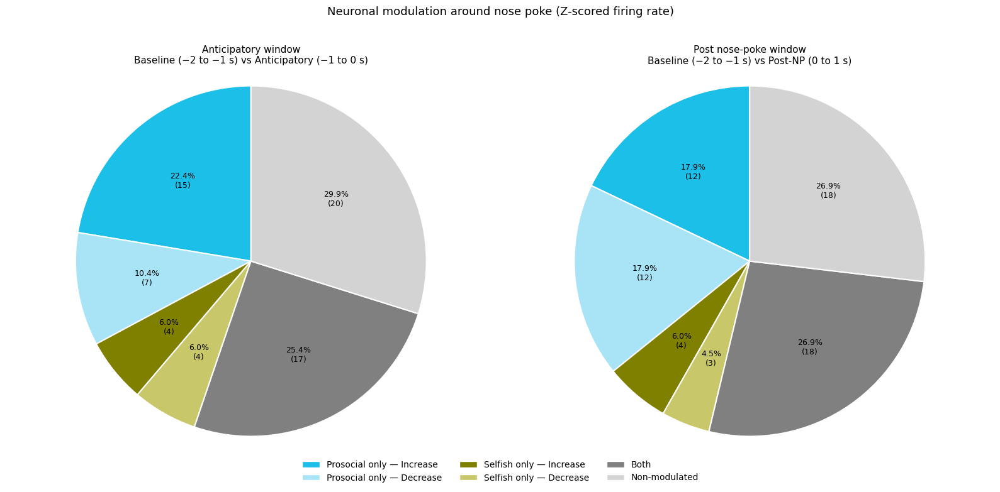

In [146]:
# ============================================================
# TWO PIE CHARTS
# Left: Anticipatory | Right: Post-NP
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path


# ------------------------------------------------------------
# CATEGORY ORDER + COLORS
# ------------------------------------------------------------

category_order = [
    "Prosocial only — Increase",
    "Prosocial only — Decrease",
    "Selfish only — Increase",
    "Selfish only — Decrease",
    "Both",
    "Non-modulated"
]

colors = [
    "#1CBFE8",   # Prosocial Increase
    "#A8E4F5",   # Prosocial Decrease
    "#808000",   # Selfish Increase
    "#C8C86A",   # Selfish Decrease
    "gray",      # Both
    "lightgray"  # Non-modulated
]


# ------------------------------------------------------------
# COUNTS
# ------------------------------------------------------------

counts_ant = [
    (modulation_results["classification_ant"] == cat).sum()
    for cat in category_order
]

counts_post = [
    (modulation_results["classification_post"] == cat).sum()
    for cat in category_order
]

total = len(modulation_results)

print("ANTICIPATORY counts:")
for cat, n in zip(category_order, counts_ant):
    print(f"  {cat}: {n}")

print("\nPOST-NP counts:")
for cat, n in zip(category_order, counts_post):
    print(f"  {cat}: {n}")


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

titles = [
    "Anticipatory window\nBaseline (−2 to −1 s) vs Anticipatory (−1 to 0 s)",
    "Post nose-poke window\nBaseline (−2 to −1 s) vs Post-NP (0 to 1 s)"
]

all_counts = [counts_ant, counts_post]

for ax, counts, title in zip(axes, all_counts, titles):

    wedges, texts, autotexts = ax.pie(
        counts,
        labels=None,
        colors=colors,
        autopct=lambda pct: (
            f"{pct:.1f}%\n"
            f"({int(round(pct / 100. * total))})"
            if pct > 0 else ""
        ),
        startangle=90,
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1.5
        }
    )

    for autotext in autotexts:
        autotext.set_fontsize(9)

    ax.set_title(title, fontsize=11, pad=15)
    ax.axis("equal")


# ------------------------------------------------------------
# SHARED LEGEND (bottom center)
# ------------------------------------------------------------

fig.legend(
    handles=[
        plt.matplotlib.patches.Patch(
            facecolor=c,
            edgecolor="white",
            label=cat
        )
        for c, cat in zip(colors, category_order)
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.suptitle(
    "Neuronal modulation around nose poke (Z-scored firing rate)",
    fontsize=13,
    y=1.02
)

plt.tight_layout()


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

save_location = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Results"
)

fig.savefig(
    save_location / "D8_Free_modulation_piecharts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Prosocial Anticipatory
 Increase: 28
 Decrease: 11
 Total significant: 39

Prosocial Post-NP
 Increase: 22
 Decrease: 20
 Total significant: 42

Selfish Anticipatory
 Increase: 15
 Decrease: 10
 Total significant: 25

Selfish Post-NP
 Increase: 15
 Decrease: 10
 Total significant: 25



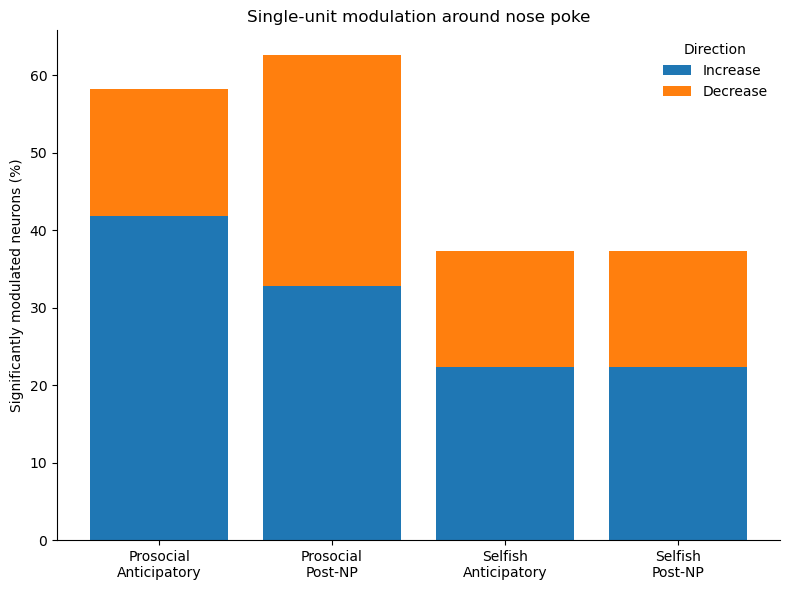

In [55]:
# ============================================================
# STACKED BAR PLOT
# Increase / Decrease
# ============================================================

import matplotlib.pyplot as plt

columns = [
    "pro_ant_direction",
    "pro_post_direction",
    "self_ant_direction",
    "self_post_direction"
]

labels = [
    "Prosocial\nAnticipatory",
    "Prosocial\nPost-NP",
    "Selfish\nAnticipatory",
    "Selfish\nPost-NP"
]

n_total = len(modulation_results)

increase_counts = []
decrease_counts = []

for col in columns:

    increase_counts.append(
        (modulation_results[col] == "Increase").sum()
    )

    decrease_counts.append(
        (modulation_results[col] == "Decrease").sum()
    )


increase_pct = (
    np.array(increase_counts) /
    n_total * 100
)

decrease_pct = (
    np.array(decrease_counts) /
    n_total * 100
)


# Print counts
for label, inc, dec in zip(
    labels,
    increase_counts,
    decrease_counts
):
    print(label.replace("\n", " "))
    print(" Increase:", inc)
    print(" Decrease:", dec)
    print(" Total significant:", inc + dec)
    print()


# ============================================================
# PLOT
# ============================================================

x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8, 6))

ax.bar(
    x,
    increase_pct,
    label="Increase"
)

ax.bar(
    x,
    decrease_pct,
    bottom=increase_pct,
    label="Decrease"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylabel("Significantly modulated neurons (%)")

ax.set_title(
    "Single-unit modulation around nose poke"
)

ax.legend(
    frameon=False,
    title="Direction"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

anticipatory_class
Prosocial only    22
Non-regulated     20
Both              17
Selfish only       8
Name: count, dtype: int64
ANTICIPATORY
----------------
Prosocial only: 22 (32.8%)
Selfish only: 8 (11.9%)
Both: 17 (25.4%)
Non-regulated: 20 (29.9%)
Total: 67


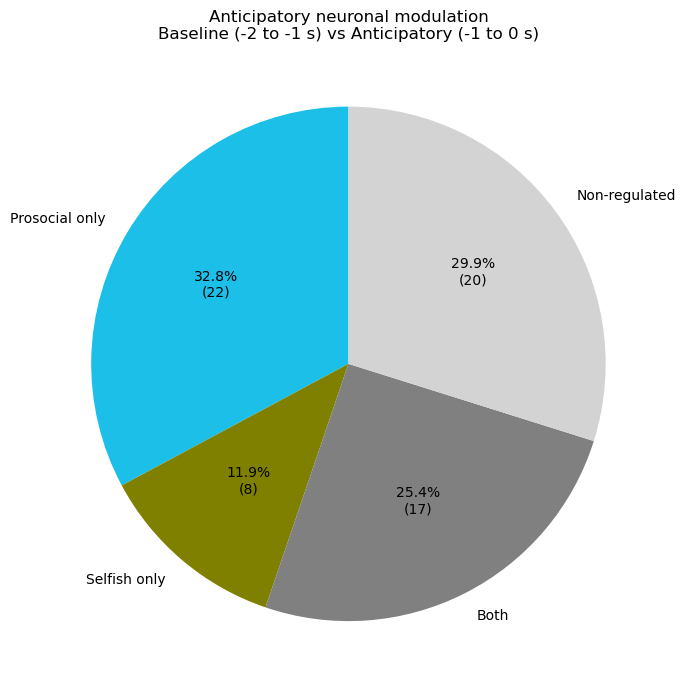

In [56]:
# ============================================================
# CLASSIFICATION - ANTICIPATORY ACTIVITY
# Baseline (-2:-1) vs Anticipatory (-1:0)
# ============================================================

alpha = 0.05

def classify_ant(row):

    pro_sig = (
        not pd.isna(row["pro_ant_p"])
        and row["pro_ant_p"] < alpha
    )

    self_sig = (
        not pd.isna(row["self_ant_p"])
        and row["self_ant_p"] < alpha
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return "Prosocial only"

    elif self_sig:
        return "Selfish only"

    else:
        return "Non-regulated"


modulation_results["anticipatory_class"] = (
    modulation_results.apply(
        classify_ant,
        axis=1
    )
)

print(
    modulation_results["anticipatory_class"]
    .value_counts()
)

import matplotlib.pyplot as plt

categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-regulated"
]

counts = [
    (
        modulation_results["anticipatory_class"]
        == category
    ).sum()
    for category in categories
]

colors = [
    "#1CBFE8",   # Prosocial
    "#808000",   # Selfish
    "gray",      # Both
    "lightgray"  # Non-regulated
]

print("ANTICIPATORY")
print("----------------")

for category, count in zip(categories, counts):
    print(
        f"{category}: {count} "
        f"({100*count/sum(counts):.1f}%)"
    )

print("Total:", sum(counts))


plt.figure(figsize=(7, 7))

plt.pie(
    counts,
    labels=categories,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(counts)))})"
    ),
    startangle=90
)

plt.title(
    "Anticipatory neuronal modulation\n"
    "Baseline (-2 to -1 s) vs Anticipatory (-1 to 0 s)"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

POST-NOSE-POKE
----------------
Prosocial only: 24 (35.8%)
Selfish only: 7 (10.4%)
Both: 18 (26.9%)
Non-regulated: 18 (26.9%)
Total: 67


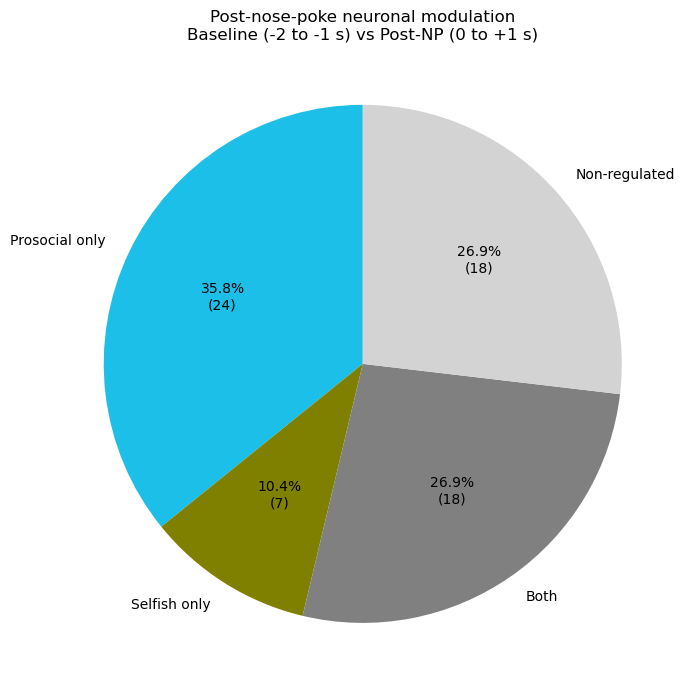

In [57]:
# ============================================================
# CLASSIFICATION - POST-NOSE-POKE
# Baseline (-2:-1) vs Post-NP (0:+1)
# ============================================================

def classify_post(row):

    pro_sig = (
        not pd.isna(row["pro_post_p"])
        and row["pro_post_p"] < alpha
    )

    self_sig = (
        not pd.isna(row["self_post_p"])
        and row["self_post_p"] < alpha
    )

    if pro_sig and self_sig:
        return "Both"

    elif pro_sig:
        return "Prosocial only"

    elif self_sig:
        return "Selfish only"

    else:
        return "Non-regulated"


modulation_results["post_class"] = (
    modulation_results.apply(
        classify_post,
        axis=1
    )
)


categories = [
    "Prosocial only",
    "Selfish only",
    "Both",
    "Non-regulated"
]

counts = [
    (
        modulation_results["post_class"]
        == category
    ).sum()
    for category in categories
]

colors = [
    "#1CBFE8",
    "#808000",
    "gray",
    "lightgray"
]

print("POST-NOSE-POKE")
print("----------------")

for category, count in zip(categories, counts):
    print(
        f"{category}: {count} "
        f"({100*count/sum(counts):.1f}%)"
    )

print("Total:", sum(counts))


plt.figure(figsize=(7, 7))

plt.pie(
    counts,
    labels=categories,
    colors=colors,
    autopct=lambda pct: (
        f"{pct:.1f}%\n"
        f"({int(round(pct/100 * sum(counts)))})"
    ),
    startangle=90
)

plt.title(
    "Post-nose-poke neuronal modulation\n"
    "Baseline (-2 to -1 s) vs Post-NP (0 to +1 s)"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

POPULATION QC
Prosocial: (67, 120)
Selfish: (67, 120)
Units: 67
NaNs Prosocial: 0
NaNs Selfish: 0


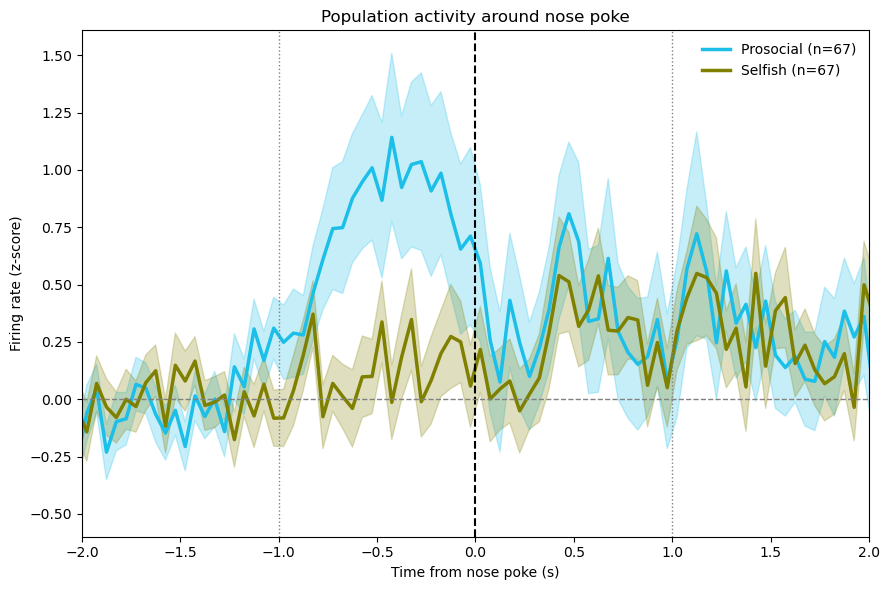

In [59]:
# ============================================================
# POPULATION MATRICES
# FREE TRIALS
# ONLY UNITS WITH VALID Z-SCORE
#
# Rows    = neurons
# Columns = time bins
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem


pro_population = []
self_population = []
unit_labels = []


for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_z_free[recording_id].items():

        # ====================================================
        # QC FILTER
        # Keep only units with valid baseline SD
        # in BOTH Prosocial and Selfish
        # ====================================================

        if (recording_id, cluster_id) not in valid_zscore_ids:
            continue

        # ----------------------------------------------------
        # Store population data
        # ----------------------------------------------------

        pro_population.append(
            data["prosocial_mean_z"]
        )

        self_population.append(
            data["selfish_mean_z"]
        )

        unit_labels.append(
            f"{recording_id}_C{cluster_id}"
        )


# ============================================================
# CONVERT TO MATRICES
# ============================================================

pro_population = np.vstack(pro_population)
self_population = np.vstack(self_population)

unit_labels = np.array(unit_labels)


# ============================================================
# QC CHECK
# ============================================================

print("====================================")
print("POPULATION QC")
print("====================================")

print("Prosocial:", pro_population.shape)
print("Selfish:", self_population.shape)
print("Units:", len(unit_labels))

print(
    "NaNs Prosocial:",
    np.isnan(pro_population).sum()
)

print(
    "NaNs Selfish:",
    np.isnan(self_population).sum()
)


# ============================================================
# POPULATION MEAN ± SEM
# ============================================================

pro_mean = np.mean(
    pro_population,
    axis=0
)

pro_sem = sem(
    pro_population,
    axis=0
)

self_mean = np.mean(
    self_population,
    axis=0
)

self_sem = sem(
    self_population,
    axis=0
)


# ============================================================
# POPULATION PETH
# VALID Z-SCORE UNITS ONLY
# ============================================================

plt.figure(figsize=(9, 6))


# ------------------------------------------------------------
# PROSOCIAL
# ------------------------------------------------------------

plt.plot(
    bin_centers,
    pro_mean,
    color="#1CBFE8",
    linewidth=2.5,
    label=f"Prosocial (n={pro_population.shape[0]})"
)

plt.fill_between(
    bin_centers,
    pro_mean - pro_sem,
    pro_mean + pro_sem,
    color="#1CBFE8",
    alpha=0.25
)


# ------------------------------------------------------------
# SELFISH
# ------------------------------------------------------------

plt.plot(
    bin_centers,
    self_mean,
    color="#808000",
    linewidth=2.5,
    label=f"Selfish (n={self_population.shape[0]})"
)

plt.fill_between(
    bin_centers,
    self_mean - self_sem,
    self_mean + self_sem,
    color="#808000",
    alpha=0.25
)


# ------------------------------------------------------------
# EVENT / WINDOWS
# ------------------------------------------------------------

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

plt.axvline(
    -1,
    color="gray",
    linestyle=":",
    linewidth=1
)

plt.axvline(
    1,
    color="gray",
    linestyle=":",
    linewidth=1
)

plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)


# ------------------------------------------------------------
# FORMAT
# ------------------------------------------------------------

plt.xlim(-2, 2)

plt.xlabel(
    "Time from nose poke (s)"
)

plt.ylabel(
    "Firing rate (z-score)"
)

plt.title(
    "Population activity around nose poke"
)

plt.legend(
    frameon=False
)

plt.tight_layout()
plt.show()

In [75]:
# ============================================================
# QUANTIFY POPULATION ACTIVITY BY TIME WINDOW
# One value per neuron per condition
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# DEFINE TIME WINDOWS
# ------------------------------------------------------------

anticipatory_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)

post_mask = (
    (bin_centers >= 0.0) &
    (bin_centers < 1.0)
)


print("Anticipatory bins:",
      anticipatory_mask.sum())

print("Post-NP bins:",
      post_mask.sum())

Anticipatory bins: 20
Post-NP bins: 20


In [76]:
# ============================================================
# ONE MEAN VALUE PER NEURON / CONDITION / WINDOW
# ONLY VALID Z-SCORE UNITS
# ============================================================

population_windows = []

for recording_id in nosepoke_recordings:

    for cluster_id, data in peth_units_z_free[recording_id].items():

        # ----------------------------------------------------
        # QC FILTER
        # Keep same valid neurons for Pro and Self
        # ----------------------------------------------------

        if (recording_id, cluster_id) not in valid_zscore_ids:
            continue

        # Complete z-scored PETH
        pro_z = data["prosocial_mean_z"]
        self_z = data["selfish_mean_z"]


        # ----------------------------------------------------
        # ANTICIPATORY (-1 to 0 s)
        # ----------------------------------------------------

        pro_ant = np.mean(
            pro_z[anticipatory_mask]
        )

        self_ant = np.mean(
            self_z[anticipatory_mask]
        )


        # ----------------------------------------------------
        # POST-NOSE-POKE (0 to +1 s)
        # ----------------------------------------------------

        pro_post = np.mean(
            pro_z[post_mask]
        )

        self_post = np.mean(
            self_z[post_mask]
        )


        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        population_windows.append({

            "recording": recording_id,
            "cluster_id": cluster_id,

            "prosocial_anticipatory": pro_ant,
            "selfish_anticipatory": self_ant,

            "prosocial_post": pro_post,
            "selfish_post": self_post
        })


population_windows = pd.DataFrame(
    population_windows
)


# ============================================================
# QC
# ============================================================

print(
    "Total neurons:",
    len(population_windows)
)

print(
    "NaNs:",
    population_windows.isna().sum().sum()
)

population_windows.head(10)

Total neurons: 67
NaNs: 0


,recording,cluster_id,prosocial_anticipatory,selfish_anticipatory,prosocial_post,selfish_post
0,1-2,0,-0.528665,2.887170e-01,-0.037762,-1.574820e-01
1,1-2,7,-0.861472,3.330669e-17,-0.861472,-6.613698e-01
2,1-2,17,-0.647527,-7.417549e-01,6.282386,6.544897e-02
3,1-2,20,1.832397,9.306433e-02,1.274711,1.554312e-16
4,1-2,21,2.302876,9.737595e-01,1.373197,2.751929e-01
5,1-2,22,5.401165,-1.142597e+00,3.469219,1.273841e+00
6,1-2,24,1.289857,1.182939e+00,2.071212,1.537821e+00
7,1-2,40,0.766423,-1.021742e-01,0.617396,4.086967e-01
8,1-2,61,4.132795,1.195089e+00,1.923690,1.934907e+00
9,1-2,62,6.573214,1.165615e+00,0.971874,1.869841e+00


In [77]:
population_windows[
    [
        "prosocial_anticipatory",
        "selfish_anticipatory",
        "prosocial_post",
        "selfish_post"
    ]
].describe()



,prosocial_anticipatory,selfish_anticipatory,prosocial_post,selfish_post
count,67.000000,6.700000e+01,67.000000,67.000000
mean,0.763776,1.194998e-01,0.352298,0.232887
std,2.041229,7.632844e-01,1.812689,1.048652
min,-4.495682,-1.556701e+00,-4.087072,-2.184844
25%,-0.458158,-3.191730e-01,-0.715151,-0.436299
50%,0.367523,3.330669e-17,0.133788,-0.054830
75%,1.811699,5.709968e-01,1.346357,0.611095
max,6.573214,2.192938e+00,6.282386,3.401073


In [63]:
population_windows["delta_anticipatory"] = (
    population_windows["prosocial_anticipatory"]
    - population_windows["selfish_anticipatory"]
)

population_windows["delta_post"] = (
    population_windows["prosocial_post"]
    - population_windows["selfish_post"]
)

In [64]:
# ============================================================
# PROSOCIAL vs SELFISH
# ANTICIPATORY WINDOW (-1 to 0 s)
# ============================================================

from scipy.stats import wilcoxon
import numpy as np

pro_ant = population_windows[
    "prosocial_anticipatory"
].to_numpy()

self_ant = population_windows[
    "selfish_anticipatory"
].to_numpy()


# ------------------------------------------------------------
# WILCOXON PAIRED TEST
# ------------------------------------------------------------

stat_ant, p_ant = wilcoxon(
    pro_ant,
    self_ant
)

print("ANTICIPATORY (-1 to 0 s)")
print("-------------------------")
print("N neurons:", len(pro_ant))

print("\nProsocial:")
print("Mean =", np.mean(pro_ant))
print("Median =", np.median(pro_ant))

print("\nSelfish:")
print("Mean =", np.mean(self_ant))
print("Median =", np.median(self_ant))

print("\nWilcoxon statistic =", stat_ant)
print("p =", p_ant)


# ============================================================
# PROSOCIAL vs SELFISH
# POST-NOSE-POKE WINDOW (0 to +1 s)
# ============================================================

pro_post = population_windows[
    "prosocial_post"
].to_numpy()

self_post = population_windows[
    "selfish_post"
].to_numpy()


stat_post, p_post = wilcoxon(
    pro_post,
    self_post
)

print("POST-NOSE-POKE (0 to +1 s)")
print("---------------------------")
print("N neurons:", len(pro_post))

print("\nProsocial:")
print("Mean =", np.mean(pro_post))
print("Median =", np.median(pro_post))

print("\nSelfish:")
print("Mean =", np.mean(self_post))
print("Median =", np.median(self_post))

print("\nWilcoxon statistic =", stat_post)
print("p =", p_post)

ANTICIPATORY (-1 to 0 s)
-------------------------
N neurons: 67

Prosocial:
Mean = 0.7637762830385916
Median = 0.3675226024777532

Selfish:
Mean = 0.11949977950893458
Median = 3.3306690738754695e-17

Wilcoxon statistic = 796.0
p = 0.03214527146365967
POST-NOSE-POKE (0 to +1 s)
---------------------------
N neurons: 67

Prosocial:
Mean = 0.3522984861127072
Median = 0.13378815086196846

Selfish:
Mean = 0.23288748386850333
Median = -0.054830001950793725

Wilcoxon statistic = 1028.0
p = 0.48807256543801614


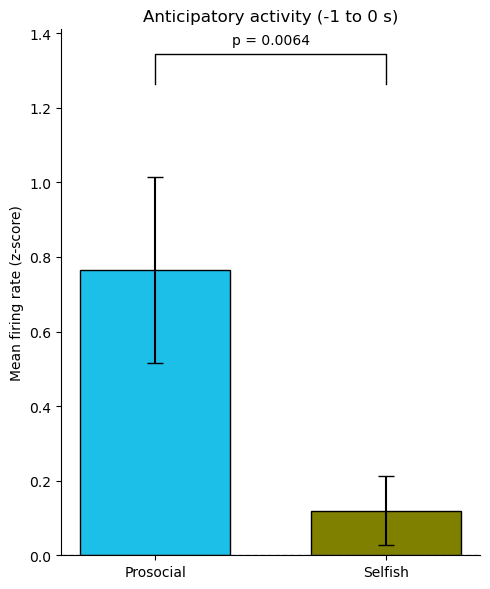

In [65]:
# ============================================================
# BAR PLOT - ANTICIPATORY (-1 to 0 s)
# Mean ± SEM across neurons
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem

pro_ant = population_windows[
    "prosocial_anticipatory"
].to_numpy()

self_ant = population_windows[
    "selfish_anticipatory"
].to_numpy()

means = [
    np.mean(pro_ant),
    np.mean(self_ant)
]

sems = [
    sem(pro_ant),
    sem(self_ant)
]

fig, ax = plt.subplots(figsize=(5, 6))

x = np.arange(2)

ax.bar(
    x,
    means,
    yerr=sems,
    capsize=6,
    width=0.65,
    color=["#1CBFE8", "#808000"],
    edgecolor="black",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels([
    "Prosocial",
    "Selfish"
])

ax.set_ylabel("Mean firing rate (z-score)")

ax.set_title(
    "Anticipatory activity (-1 to 0 s)"
)

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# Significance line
y_max = max(
    means[0] + sems[0],
    means[1] + sems[1]
)

y = y_max + 0.25

ax.plot(
    [0, 0, 1, 1],
    [y, y + 0.08, y + 0.08, y],
    color="black",
    linewidth=1
)

ax.text(
    0.5,
    y + 0.10,
    "p = 0.0064",
    ha="center",
    va="bottom"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

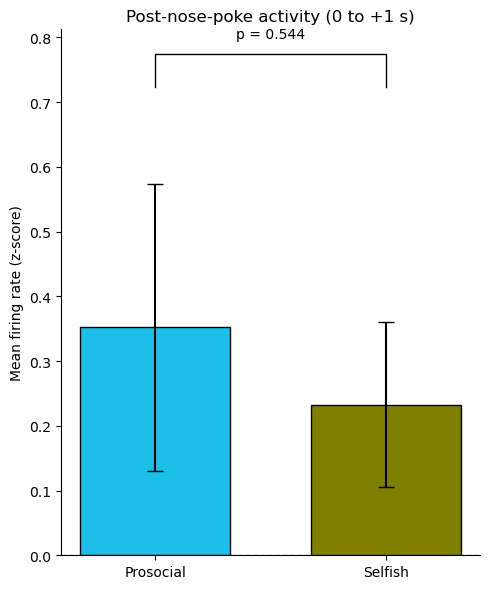

In [66]:
# ============================================================
# BAR PLOT - POST-NOSE-POKE (0 to +1 s)
# Mean ± SEM across neurons
# ============================================================

pro_post = population_windows[
    "prosocial_post"
].to_numpy()

self_post = population_windows[
    "selfish_post"
].to_numpy()

means = [
    np.mean(pro_post),
    np.mean(self_post)
]

sems = [
    sem(pro_post),
    sem(self_post)
]

fig, ax = plt.subplots(figsize=(5, 6))

x = np.arange(2)

ax.bar(
    x,
    means,
    yerr=sems,
    capsize=6,
    width=0.65,
    color=["#1CBFE8", "#808000"],
    edgecolor="black",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels([
    "Prosocial",
    "Selfish"
])

ax.set_ylabel("Mean firing rate (z-score)")

ax.set_title(
    "Post-nose-poke activity (0 to +1 s)"
)

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# p-value
y_max = max(
    means[0] + sems[0],
    means[1] + sems[1]
)

y = y_max + 0.15

ax.plot(
    [0, 0, 1, 1],
    [y, y + 0.05, y + 0.05, y],
    color="black",
    linewidth=1
)

ax.text(
    0.5,
    y + 0.07,
    "p = 0.544",
    ha="center",
    va="bottom"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Heat map

In [199]:
pro_population.shape
# (69, 80)

self_population.shape
# (69, 80)

(67, 120)

In [200]:
# ============================================================
# SORT NEURONS BY PROSOCIAL ANTICIPATORY ACTIVITY
# ============================================================

anticipatory_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)

# Mean anticipatory activity for each neuron
pro_ant_activity = np.mean(
    pro_population[:, anticipatory_mask],
    axis=1
)

# Sort highest -> lowest
sort_idx = np.argsort(
    pro_ant_activity
)[::-1]

# Apply SAME order to both conditions
pro_sorted = pro_population[sort_idx, :]
self_sorted = self_population[sort_idx, :]

sorted_labels = unit_labels[sort_idx]

print(pro_sorted.shape)
print(self_sorted.shape)

(67, 120)
(67, 120)


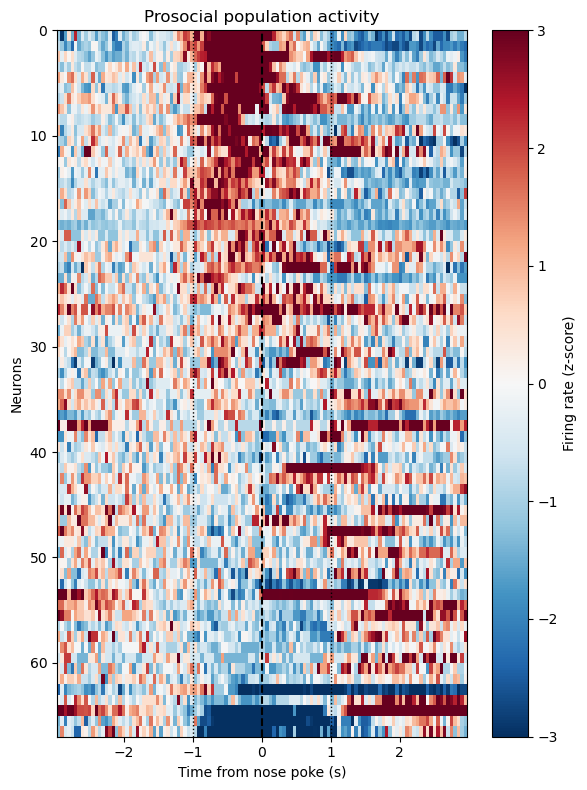

In [201]:
# ============================================================
# PROSOCIAL HEATMAP
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 8))

im = ax.imshow(
    pro_sorted,
    aspect="auto",
    interpolation="nearest",
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    extent=[
        bin_centers[0],
        bin_centers[-1],
        len(pro_sorted),
        0
    ]
)

# Nose poke
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

# Window boundaries
ax.axvline(
    -1,
    color="black",
    linestyle=":",
    linewidth=1
)

ax.axvline(
    1,
    color="black",
    linestyle=":",
    linewidth=1
)

ax.set_xlabel(
    "Time from nose poke (s)"
)

ax.set_ylabel(
    "Neurons"
)

ax.set_title(
    "Prosocial population activity"
)

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Firing rate (z-score)"
)

plt.tight_layout()
plt.show()

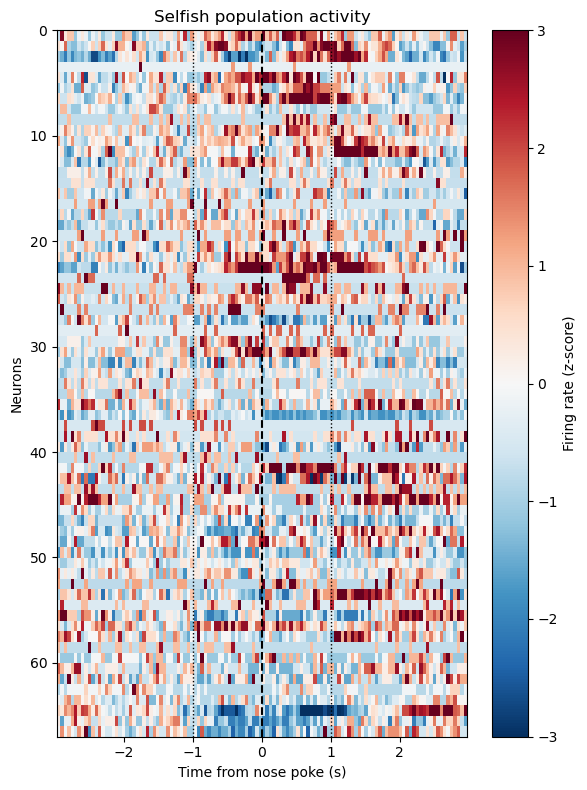

In [202]:
# ============================================================
# SELFISH HEATMAP
# SAME NEURON ORDER AS PROSOCIAL
# ============================================================

fig, ax = plt.subplots(figsize=(6, 8))

im = ax.imshow(
    self_sorted,
    aspect="auto",
    interpolation="nearest",
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    extent=[
        bin_centers[0],
        bin_centers[-1],
        len(self_sorted),
        0
    ]
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

ax.axvline(
    -1,
    color="black",
    linestyle=":",
    linewidth=1
)

ax.axvline(
    1,
    color="black",
    linestyle=":",
    linewidth=1
)

ax.set_xlabel(
    "Time from nose poke (s)"
)

ax.set_ylabel(
    "Neurons"
)

ax.set_title(
    "Selfish population activity"
)

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Firing rate (z-score)"
)

plt.tight_layout()
plt.show()

In [80]:
# ============================================================
# OVERLAP: ANTICIPATORY vs POST-NOSE-POKE
# ============================================================

import pandas as pd
import numpy as np

alpha = 0.05


def classify_period_overlap(ant_p, post_p):

    ant_sig = (
        not pd.isna(ant_p)
        and ant_p < alpha
    )

    post_sig = (
        not pd.isna(post_p)
        and post_p < alpha
    )

    if ant_sig and post_sig:
        return "Both"

    elif ant_sig:
        return "Anticipatory only"

    elif post_sig:
        return "Post-NP only"

    else:
        return "Neither"


# ------------------------------------------------------------
# PROSOCIAL
# ------------------------------------------------------------

modulation_results["pro_period_class"] = (
    modulation_results.apply(
        lambda row: classify_period_overlap(
            row["pro_ant_p"],
            row["pro_post_p"]
        ),
        axis=1
    )
)


# ------------------------------------------------------------
# SELFISH
# ------------------------------------------------------------

modulation_results["self_period_class"] = (
    modulation_results.apply(
        lambda row: classify_period_overlap(
            row["self_ant_p"],
            row["self_post_p"]
        ),
        axis=1
    )
)

print("PROSOCIAL")
print(
    modulation_results[
        "pro_period_class"
    ].value_counts()
)

print("\nSELFISH")
print(
    modulation_results[
        "self_period_class"
    ].value_counts()
)

print("PROSOCIAL (%)")
print(
    modulation_results[
        "pro_period_class"
    ].value_counts(normalize=True) * 100
)

print("\nSELFISH (%)")
print(
    modulation_results[
        "self_period_class"
    ].value_counts(normalize=True) * 100
)

PROSOCIAL
pro_period_class
Both                 27
Post-NP only         15
Neither              13
Anticipatory only    12
Name: count, dtype: int64

SELFISH
self_period_class
Neither              34
Both                 17
Post-NP only          8
Anticipatory only     8
Name: count, dtype: int64
PROSOCIAL (%)
pro_period_class
Both                 40.298507
Post-NP only         22.388060
Neither              19.402985
Anticipatory only    17.910448
Name: proportion, dtype: float64

SELFISH (%)
self_period_class
Neither              50.746269
Both                 25.373134
Post-NP only         11.940299
Anticipatory only    11.940299
Name: proportion, dtype: float64


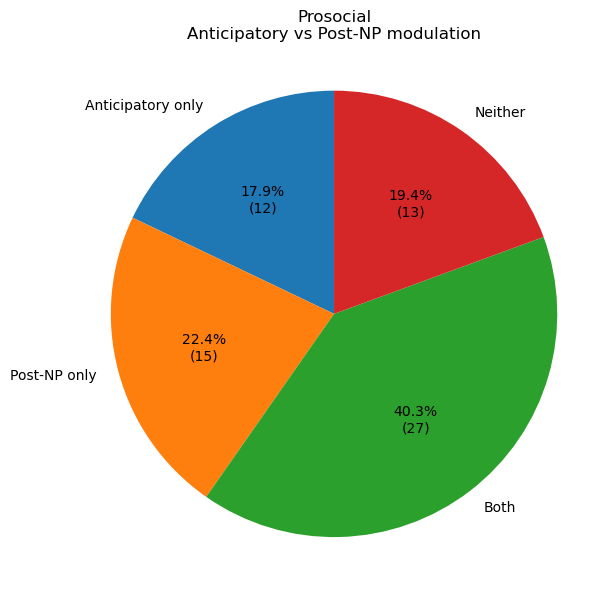

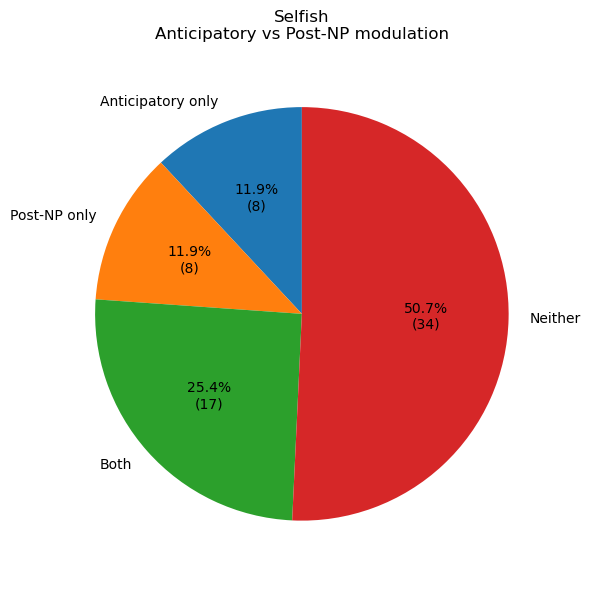

In [81]:
import matplotlib.pyplot as plt

categories = [
    "Anticipatory only",
    "Post-NP only",
    "Both",
    "Neither"
]

for condition, column in [
    ("Prosocial", "pro_period_class"),
    ("Selfish", "self_period_class")
]:

    counts = [
        (
            modulation_results[column]
            == category
        ).sum()
        for category in categories
    ]

    plt.figure(figsize=(6, 6))

    plt.pie(
        counts,
        labels=categories,
        autopct=lambda pct:
            f"{pct:.1f}%\n({int(round(pct/100*sum(counts)))})",
        startangle=90
    )

    plt.title(
        f"{condition}\n"
        "Anticipatory vs Post-NP modulation"
    )

    plt.axis("equal")
    plt.tight_layout()
    plt.show()

PROSOCIAL
Neurons significant in both periods: 27
direction_transition
Increase → Increase    15
Decrease → Decrease     9
Increase → Decrease     3
Name: count, dtype: int64


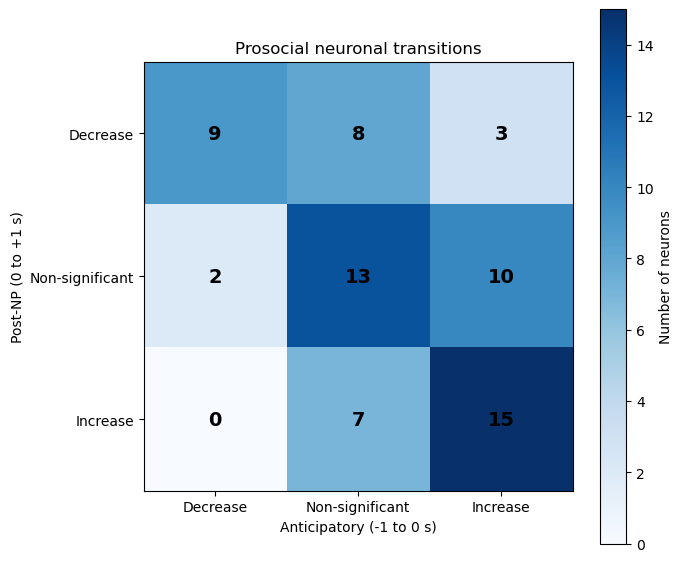

In [82]:
# ============================================================
# DIRECTION CHANGE: ANTICIPATORY -> POST-NP
# PROSOCIAL
# ============================================================

pro_both = modulation_results[
    modulation_results["pro_period_class"] == "Both"
].copy()


def classify_direction_change(ant_direction, post_direction):

    if ant_direction == "Increase" and post_direction == "Increase":
        return "Increase → Increase"

    elif ant_direction == "Increase" and post_direction == "Decrease":
        return "Increase → Decrease"

    elif ant_direction == "Decrease" and post_direction == "Increase":
        return "Decrease → Increase"

    elif ant_direction == "Decrease" and post_direction == "Decrease":
        return "Decrease → Decrease"

    else:
        return "Other"


pro_both["direction_transition"] = pro_both.apply(
    lambda row: classify_direction_change(
        row["pro_ant_direction"],
        row["pro_post_direction"]
    ),
    axis=1
)

print("PROSOCIAL")
print("Neurons significant in both periods:", len(pro_both))

print(
    pro_both["direction_transition"]
    .value_counts()
)





# ============================================================
# TRANSITION MATRIX
# PROSOCIAL
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

order = [
    "Decrease",
    "Non-significant",
    "Increase"
]

transition_matrix = pd.crosstab(
    modulation_results["pro_post_direction"],
    modulation_results["pro_ant_direction"]
)

transition_matrix = transition_matrix.reindex(
    index=order,
    columns=order,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    transition_matrix.values,
    cmap="Blues"
)

# Numbers inside cells
for i in range(len(order)):
    for j in range(len(order)):

        n = transition_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            str(n),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold"
        )

ax.set_xticks(range(3))
ax.set_xticklabels(order)

ax.set_yticks(range(3))
ax.set_yticklabels(order)

ax.set_xlabel(
    "Anticipatory (-1 to 0 s)"
)

ax.set_ylabel(
    "Post-NP (0 to +1 s)"
)

ax.set_title(
    "Prosocial neuronal transitions"
)

plt.colorbar(
    im,
    ax=ax,
    label="Number of neurons"
)

plt.tight_layout()
plt.show()

SELFISH
Neurons significant in both periods: 17
direction_transition
Increase → Increase    10
Decrease → Decrease     5
Decrease → Increase     2
Name: count, dtype: int64


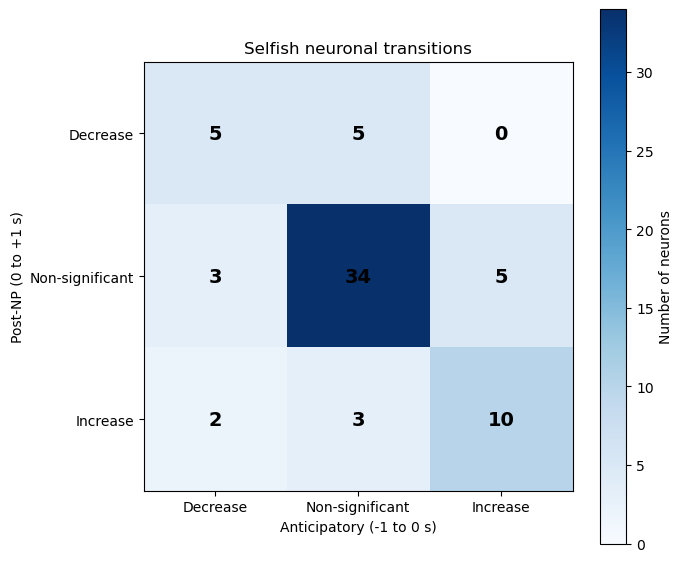

In [83]:
# ============================================================
# DIRECTION CHANGE: ANTICIPATORY -> POST-NP
# SELFISH
# ============================================================

self_both = modulation_results[
    modulation_results["self_period_class"] == "Both"
].copy()


def classify_direction_change(ant_direction, post_direction):

    if ant_direction == "Increase" and post_direction == "Increase":
        return "Increase → Increase"

    elif ant_direction == "Increase" and post_direction == "Decrease":
        return "Increase → Decrease"

    elif ant_direction == "Decrease" and post_direction == "Increase":
        return "Decrease → Increase"

    elif ant_direction == "Decrease" and post_direction == "Decrease":
        return "Decrease → Decrease"

    else:
        return "Other"


self_both["direction_transition"] = self_both.apply(
    lambda row: classify_direction_change(
        row["self_ant_direction"],
        row["self_post_direction"]
    ),
    axis=1
)

print("SELFISH")
print("Neurons significant in both periods:", len(self_both))

print(
    self_both["direction_transition"]
    .value_counts()
)



# ============================================================
# TRANSITION MATRIX
# SELFISH
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

order = [
    "Decrease",
    "Non-significant",
    "Increase"
]

transition_matrix_self = pd.crosstab(
    modulation_results["self_post_direction"],
    modulation_results["self_ant_direction"]
)

transition_matrix_self = transition_matrix_self.reindex(
    index=order,
    columns=order,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    transition_matrix_self.values,
    cmap="Blues"
)

# Numbers inside cells
for i in range(len(order)):
    for j in range(len(order)):

        n = transition_matrix_self.iloc[i, j]

        ax.text(
            j,
            i,
            str(n),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold"
        )

ax.set_xticks(range(3))
ax.set_xticklabels(order)

ax.set_yticks(range(3))
ax.set_yticklabels(order)

ax.set_xlabel(
    "Anticipatory (-1 to 0 s)"
)

ax.set_ylabel(
    "Post-NP (0 to +1 s)"
)

ax.set_title(
    "Selfish neuronal transitions"
)

plt.colorbar(
    im,
    ax=ax,
    label="Number of neurons"
)

plt.tight_layout()
plt.show()

PCA

In [86]:
print("pro_population:", pro_population.shape)
print("self_population:", self_population.shape)

print(
    "NaNs Prosocial:",
    np.isnan(pro_population).sum()
)

print(
    "NaNs Selfish:",
    np.isnan(self_population).sum()
)

pro_nan_units = np.where(
    np.isnan(pro_population).any(axis=1)
)[0]

self_nan_units = np.where(
    np.isnan(self_population).any(axis=1)
)[0]

print("\nUnits with NaN - Prosocial:", pro_nan_units)
print("Units with NaN - Selfish:", self_nan_units)

print("\nNumber of units with NaN:")
print("Prosocial:", len(pro_nan_units))
print("Selfish:", len(self_nan_units))

pro_population: (67, 120)
self_population: (67, 120)
NaNs Prosocial: 0
NaNs Selfish: 0

Units with NaN - Prosocial: []
Units with NaN - Selfish: []

Number of units with NaN:
Prosocial: 0
Selfish: 0


In [87]:
# ============================================================
# CELL 1 — PREPARE DATA FOR POPULATION PCA
# ============================================================

import numpy as np

# Current shape:
# neurons × time bins
print("Prosocial original:", pro_population.shape)
print("Selfish original:", self_population.shape)

# Transpose:
# time bins × neurons
pro_pca_data = pro_population.T
self_pca_data = self_population.T

print("\nProsocial for PCA:", pro_pca_data.shape)
print("Selfish for PCA:", self_pca_data.shape)

Prosocial original: (67, 120)
Selfish original: (67, 120)

Prosocial for PCA: (120, 67)
Selfish for PCA: (120, 67)


In [88]:
# ============================================================
# CELL 2 — FIT COMMON PCA SPACE
# ============================================================

from sklearn.decomposition import PCA

# Combine both conditions
# 160 time points × 69 neurons
combined_data = np.vstack([
    pro_pca_data,
    self_pca_data
])

print("Combined data:", combined_data.shape)

# PCA
pca = PCA(n_components=3)

combined_pca = pca.fit_transform(combined_data)

print("\nPCA output:", combined_pca.shape)

print("\nExplained variance:")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {var*100:.2f}%")

print(
    "\nTotal PC1-PC3:",
    pca.explained_variance_ratio_.sum() * 100,
    "%"
)

Combined data: (240, 67)

PCA output: (240, 3)

Explained variance:
PC1: 26.58%
PC2: 11.30%
PC3: 7.28%

Total PC1-PC3: 45.15652459991974 %


In [89]:
# ============================================================
# CELL 3 — SEPARATE PCA TRAJECTORIES
# ============================================================

n_timebins = len(bin_centers)

pro_trajectory = combined_pca[:n_timebins, :]
self_trajectory = combined_pca[n_timebins:, :]

print("Prosocial trajectory:", pro_trajectory.shape)
print("Selfish trajectory:", self_trajectory.shape)

Prosocial trajectory: (120, 3)
Selfish trajectory: (120, 3)


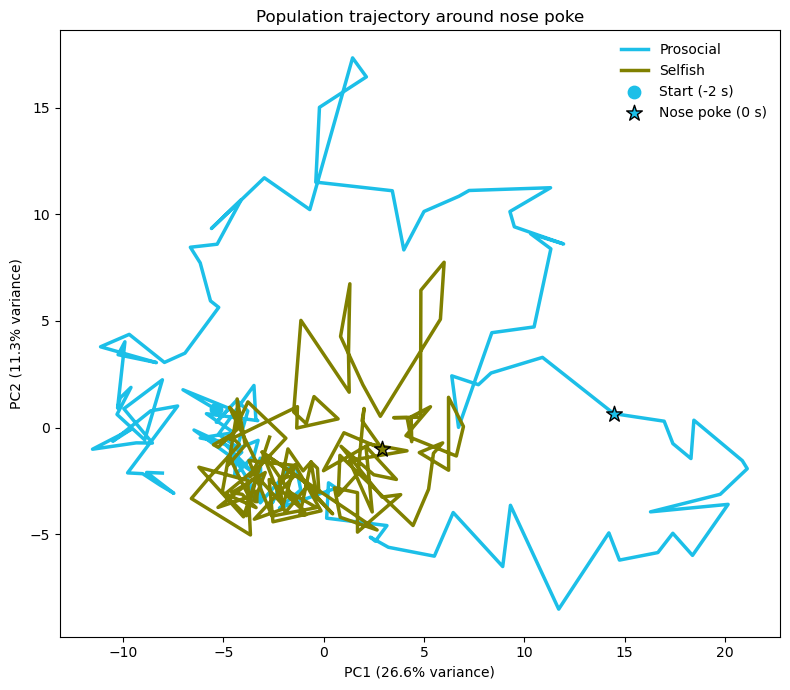

In [90]:
# ============================================================
# CELL 4 — PC1 vs PC2 POPULATION TRAJECTORY
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))

# Prosocial trajectory
ax.plot(
    pro_trajectory[:, 0],
    pro_trajectory[:, 1],
    linewidth=2.5,
    color="#1CBFE8",
    label="Prosocial"
)

# Selfish trajectory
ax.plot(
    self_trajectory[:, 0],
    self_trajectory[:, 1],
    linewidth=2.5,
    color="#808000",
    label="Selfish"
)

# ============================================================
# START (-2 s) — CIRCLE
# ============================================================

ax.scatter(
    pro_trajectory[0, 0],
    pro_trajectory[0, 1],
    color="#1CBFE8",
    s=80,
    marker="o",
    label="Start (-2 s)"
)

ax.scatter(
    self_trajectory[0, 0],
    self_trajectory[0, 1],
    color="#808000",
    s=80,
    marker="o"
)

# ============================================================
# NOSE POKE (0 s) — STAR
# ============================================================

zero_idx = np.argmin(np.abs(bin_centers))

ax.scatter(
    pro_trajectory[zero_idx, 0],
    pro_trajectory[zero_idx, 1],
    color="#1CBFE8",
    s=140,
    marker="*",
    edgecolor="black",
    zorder=5,
    label="Nose poke (0 s)"
)

ax.scatter(
    self_trajectory[zero_idx, 0],
    self_trajectory[zero_idx, 1],
    color="#808000",
    s=140,
    marker="*",
    edgecolor="black",
    zorder=5
)

# ============================================================
# LABELS
# ============================================================

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
)

ax.set_title(
    "Population trajectory around nose poke"
)

# ONE LEGEND
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

PCs needed for 80% variance: 23
Variance explained: 80.56031769007375 %


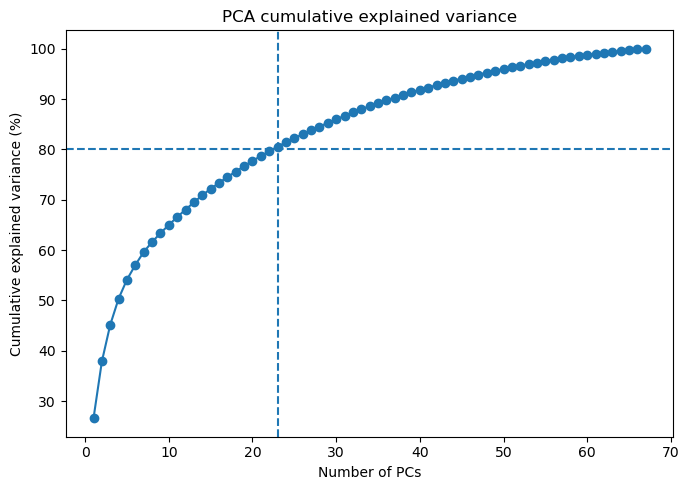

In [91]:
# ============================================================
# CELL 6 — EXPLAINED VARIANCE
# ============================================================

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# PCA using all possible components
pca_full = PCA()

pca_full.fit(combined_data)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Number of PCs needed to explain at least 80%
n_pcs_80 = np.argmax(cumulative_variance >= 0.80) + 1

print("PCs needed for 80% variance:", n_pcs_80)

print(
    "Variance explained:",
    cumulative_variance[n_pcs_80 - 1] * 100,
    "%"
)


# Plot cumulative explained variance
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

ax.axhline(
    80,
    linestyle="--"
)

ax.axvline(
    n_pcs_80,
    linestyle="--"
)

ax.set_xlabel("Number of PCs")
ax.set_ylabel("Cumulative explained variance (%)")

ax.set_title(
    "PCA cumulative explained variance"
)

plt.tight_layout()
plt.show()

In [92]:
# ============================================================
# CELL 7 — PCA FOR TRAJECTORY DISTANCE
# ============================================================

pca_80 = PCA(
    n_components=n_pcs_80
)

combined_pca_80 = pca_80.fit_transform(
    combined_data
)

# Separate conditions again
n_timebins = len(bin_centers)

pro_trajectory_80 = combined_pca_80[
    :n_timebins,
    :
]

self_trajectory_80 = combined_pca_80[
    n_timebins:,
    :
]

print(
    "Prosocial trajectory:",
    pro_trajectory_80.shape
)

print(
    "Selfish trajectory:",
    self_trajectory_80.shape
)

print(
    "Total variance explained:",
    pca_80.explained_variance_ratio_.sum() * 100,
    "%"
)

Prosocial trajectory: (120, 23)
Selfish trajectory: (120, 23)
Total variance explained: 80.56031769007375 %


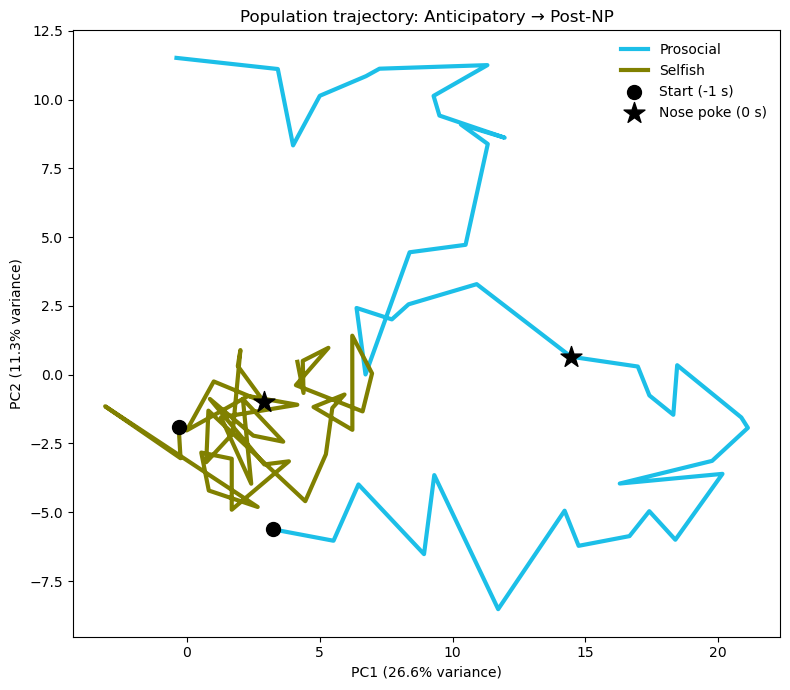

In [93]:
# ============================================================
# CLEAN POPULATION TRAJECTORY
# -1 to +1 s
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Time window
plot_mask = (
    (bin_centers >= -1.0) &
    (bin_centers <= 1.0)
)

pro_plot = pro_trajectory[plot_mask, :]
self_plot = self_trajectory[plot_mask, :]

time_plot = bin_centers[plot_mask]


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))


# ------------------------------------------------------------
# PROSOCIAL
# ------------------------------------------------------------

ax.plot(
    pro_plot[:, 0],
    pro_plot[:, 1],
    color="#1CBFE8",
    linewidth=3,
    label="Prosocial"
)


# ------------------------------------------------------------
# SELFISH
# ------------------------------------------------------------

ax.plot(
    self_plot[:, 0],
    self_plot[:, 1],
    color="#808000",
    linewidth=3,
    label="Selfish"
)


# ------------------------------------------------------------
# START OF ANTICIPATORY PERIOD (-1 s)
# Black circle
# ------------------------------------------------------------

ax.scatter(
    pro_plot[0, 0],
    pro_plot[0, 1],
    color="black",
    s=100,
    marker="o",
    zorder=5,
    label="Start (-1 s)"
)

ax.scatter(
    self_plot[0, 0],
    self_plot[0, 1],
    color="black",
    s=100,
    marker="o",
    zorder=5
)


# ------------------------------------------------------------
# NOSE POKE (0 s)
# Black star
# ------------------------------------------------------------

zero_idx = np.argmin(
    np.abs(time_plot)
)

ax.scatter(
    pro_plot[zero_idx, 0],
    pro_plot[zero_idx, 1],
    color="black",
    marker="*",
    s=250,
    zorder=6,
    label="Nose poke (0 s)"
)

ax.scatter(
    self_plot[zero_idx, 0],
    self_plot[zero_idx, 1],
    color="black",
    marker="*",
    s=250,
    zorder=6
)


# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
)

ax.set_title(
    "Population trajectory: Anticipatory → Post-NP"
)


# ------------------------------------------------------------
# ONE LEGEND
# ------------------------------------------------------------

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# CLEAN POPULATION TRAJECTORY
# -1 to +1 s
# SMOOTHING FOR PLOT ONLY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d


# ============================================================
# SMOOTHING
# Plot only — does NOT modify original trajectories
# ============================================================

smooth_sigma = 1   # ~50 ms with 50-ms bins


# Time window
plot_mask = (
    (bin_centers >= -1.0) &
    (bin_centers <= 1.0)
)

pro_plot = pro_trajectory[plot_mask, :]
self_plot = self_trajectory[plot_mask, :]

time_plot = bin_centers[plot_mask]


# ============================================================
# SMOOTH TRAJECTORIES FOR VISUALIZATION ONLY
# ============================================================

pro_plot_smooth = gaussian_filter1d(
    pro_plot,
    sigma=smooth_sigma,
    axis=0
)

self_plot_smooth = gaussian_filter1d(
    self_plot,
    sigma=smooth_sigma,
    axis=0
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))


# ------------------------------------------------------------
# PROSOCIAL
# ------------------------------------------------------------

ax.plot(
    pro_plot_smooth[:, 0],
    pro_plot_smooth[:, 1],
    color="#1CBFE8",
    linewidth=3,
    label="Prosocial"
)


# ------------------------------------------------------------
# SELFISH
# ------------------------------------------------------------

ax.plot(
    self_plot_smooth[:, 0],
    self_plot_smooth[:, 1],
    color="#808000",
    linewidth=3,
    label="Selfish"
)


# ------------------------------------------------------------
# START OF ANTICIPATORY PERIOD (-1 s)
# Black circle
# ------------------------------------------------------------

ax.scatter(
    pro_plot_smooth[0, 0],
    pro_plot_smooth[0, 1],
    color="black",
    s=100,
    marker="o",
    zorder=5,
    label="Start (-1 s)"
)

ax.scatter(
    self_plot_smooth[0, 0],
    self_plot_smooth[0, 1],
    color="black",
    s=100,
    marker="o",
    zorder=5
)


# ------------------------------------------------------------
# NOSE POKE (0 s)
# Black star
# ------------------------------------------------------------

zero_idx = np.argmin(
    np.abs(time_plot)
)

ax.scatter(
    pro_plot_smooth[zero_idx, 0],
    pro_plot_smooth[zero_idx, 1],
    color="black",
    marker="*",
    s=250,
    zorder=6,
    label="Nose poke (0 s)"
)

ax.scatter(
    self_plot_smooth[zero_idx, 0],
    self_plot_smooth[zero_idx, 1],
    color="black",
    marker="*",
    s=250,
    zorder=6
)


# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
)

ax.set_title(
    "Population trajectory: Anticipatory → Post-NP"
)


# ------------------------------------------------------------
# ONE LEGEND
# ------------------------------------------------------------

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()

NameError: name 'bin_centers' is not defined

In [94]:
# ============================================================
# CELL 8 — PROSOCIAL vs SELFISH TRAJECTORY DISTANCE
# ============================================================

trajectory_distance = np.linalg.norm(
    pro_trajectory_80 - self_trajectory_80,
    axis=1
)

print(
    "Distance shape:",
    trajectory_distance.shape
)

print(
    "Minimum distance:",
    trajectory_distance.min()
)

print(
    "Maximum distance:",
    trajectory_distance.max()
)

Distance shape: (120,)
Minimum distance: 5.881717628555566
Maximum distance: 25.507709078211658


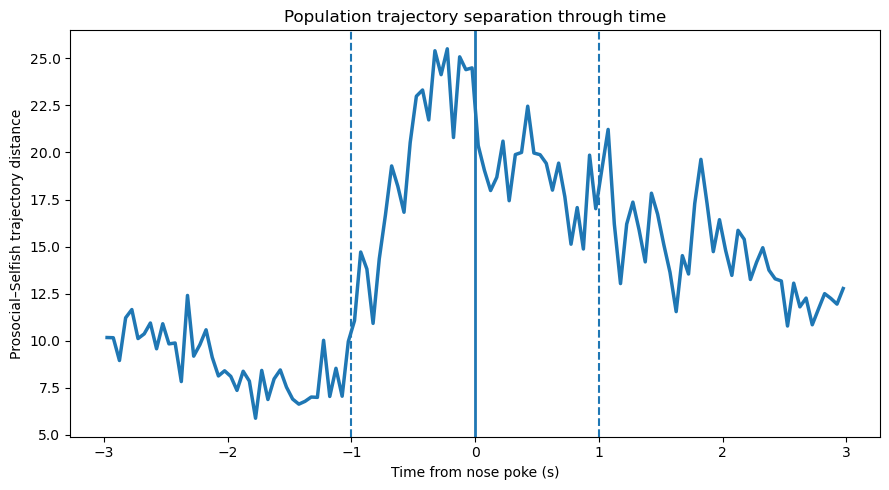

In [95]:
# ============================================================
# CELL 9 — DISTANCE THROUGH TIME
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    bin_centers,
    trajectory_distance,
    linewidth=2.5
)

# Window boundaries
ax.axvline(
    -1,
    linestyle="--",
    linewidth=1.5
)

ax.axvline(
    0,
    linestyle="-",
    linewidth=2
)

ax.axvline(
    1,
    linestyle="--",
    linewidth=1.5
)

ax.set_xlabel(
    "Time from nose poke (s)"
)

ax.set_ylabel(
    "Prosocial–Selfish trajectory distance"
)

ax.set_title(
    "Population trajectory separation through time"
)

plt.tight_layout()
plt.show()

In [96]:
# ============================================================
# CELL 10 — MEAN DISTANCE BY BEHAVIORAL WINDOW
# ============================================================

baseline_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)

anticipatory_mask = (
    (bin_centers >= -1.0) &
    (bin_centers < 0.0)
)

post_mask = (
    (bin_centers >= 0.0) &
    (bin_centers < 1.0)
)


baseline_distance = np.mean(
    trajectory_distance[baseline_mask]
)

anticipatory_distance = np.mean(
    trajectory_distance[anticipatory_mask]
)

post_distance = np.mean(
    trajectory_distance[post_mask]
)


print(
    "Baseline distance:",
    baseline_distance
)

print(
    "Anticipatory distance:",
    anticipatory_distance
)

print(
    "Post-NP distance:",
    post_distance
)

Baseline distance: 7.687829744256911
Anticipatory distance: 19.711951370825812
Post-NP distance: 18.738959740466836


analisis para ver si la diferencia de ensayos afecta

In [97]:
# ============================================================
# CELL 1 — CHECK TRIAL IMBALANCE
# ============================================================

for recording_id in nosepoke_recordings:

    # Any unit works because neurons from the same recording
    # have the same behavioral trials
    cluster_id = next(
        iter(peth_units_free[recording_id])
    )

    data = peth_units_free[recording_id][cluster_id]

    n_pro = data["prosocial_trials"].shape[0]
    n_self = data["selfish_trials"].shape[0]

    print(
        f"{recording_id}: "
        f"Prosocial = {n_pro}, "
        f"Selfish = {n_self}, "
        f"Matched N = {min(n_pro, n_self)}"
    )

1-2: Prosocial = 185, Selfish = 26, Matched N = 26
2-4: Prosocial = 219, Selfish = 10, Matched N = 10
4-3: Prosocial = 126, Selfish = 54, Matched N = 54
4-4: Prosocial = 149, Selfish = 22, Matched N = 22


In [98]:
# ============================================================
# CELL 2 — ONE TRIAL-MATCHED ITERATION
# ============================================================

import numpy as np


baseline_mask = (
    (bin_centers >= -2.0) &
    (bin_centers < -1.0)
)


def trial_matched_iteration(
    peth_units_free,
    recordings,
    valid_zscore_ids,
    rng
):

    pro_population = []
    self_population = []
    labels = []

    for recording_id in recordings:

        # ----------------------------------------------------
        # Get number of trials in this recording
        # ----------------------------------------------------

        first_cluster = next(
            iter(peth_units_free[recording_id])
        )

        first_data = peth_units_free[
            recording_id
        ][first_cluster]

        n_pro = first_data[
            "prosocial_trials"
        ].shape[0]

        n_self = first_data[
            "selfish_trials"
        ].shape[0]

        n_match = min(n_pro, n_self)


        # ----------------------------------------------------
        # Randomly select equal numbers of Pro and Self trials
        # Same trial indices are used for every neuron
        # within the recording
        # ----------------------------------------------------

        pro_idx = rng.choice(
            n_pro,
            size=n_match,
            replace=False
        )

        self_idx = rng.choice(
            n_self,
            size=n_match,
            replace=False
        )


        # ----------------------------------------------------
        # Neurons
        # ----------------------------------------------------

        for cluster_id, data in peth_units_free[
            recording_id
        ].items():

            # Only original 67 valid units
            if (
                recording_id,
                cluster_id
            ) not in valid_zscore_ids:
                continue


            # ------------------------------------------------
            # Select matched trials
            # ------------------------------------------------

            pro_trials = data[
                "prosocial_trials"
            ][pro_idx, :]

            self_trials = data[
                "selfish_trials"
            ][self_idx, :]


            # ------------------------------------------------
            # Mean PETH after trial matching
            # ------------------------------------------------

            pro_mean = np.mean(
                pro_trials,
                axis=0
            )

            self_mean = np.mean(
                self_trials,
                axis=0
            )


            # ------------------------------------------------
            # Baseline
            # ------------------------------------------------

            pro_baseline = pro_mean[
                baseline_mask
            ]

            self_baseline = self_mean[
                baseline_mask
            ]

            pro_mu = np.mean(pro_baseline)
            self_mu = np.mean(self_baseline)

            pro_sd = np.std(
                pro_baseline,
                ddof=1
            )

            self_sd = np.std(
                self_baseline,
                ddof=1
            )


            # ------------------------------------------------
            # If subsampling creates SD = 0,
            # unit cannot be z-scored in this iteration
            # ------------------------------------------------

            if (
                pro_sd == 0 or
                self_sd == 0 or
                not np.isfinite(pro_sd) or
                not np.isfinite(self_sd)
            ):
                continue


            # ------------------------------------------------
            # Z-score
            # ------------------------------------------------

            pro_z = (
                pro_mean - pro_mu
            ) / pro_sd

            self_z = (
                self_mean - self_mu
            ) / self_sd


            pro_population.append(pro_z)
            self_population.append(self_z)

            labels.append(
                f"{recording_id}_C{cluster_id}"
            )


    return (
        np.vstack(pro_population),
        np.vstack(self_population),
        np.array(labels)
    )

In [99]:
# ============================================================
# CELL 3 — TEST ONE ITERATION
# ============================================================

rng = np.random.default_rng(12345)

pro_matched, self_matched, matched_labels = (
    trial_matched_iteration(
        peth_units_free,
        nosepoke_recordings,
        valid_zscore_ids,
        rng
    )
)

print("Prosocial:", pro_matched.shape)
print("Selfish:", self_matched.shape)
print("Units retained:", len(matched_labels))

Prosocial: (66, 120)
Selfish: (66, 120)
Units retained: 66


In [100]:
# ============================================================
# CELL 4 — 1000 TRIAL-MATCHED ITERATIONS
# ============================================================

import numpy as np
import pandas as pd


n_iterations = 1000

rng = np.random.default_rng(12345)

iteration_results = []


for iteration in range(n_iterations):

    pro_matched, self_matched, matched_labels = (
        trial_matched_iteration(
            peth_units_free,
            nosepoke_recordings,
            valid_zscore_ids,
            rng
        )
    )


    # --------------------------------------------------------
    # ANTICIPATORY (-1 to 0 s)
    # One mean value per neuron
    # --------------------------------------------------------

    pro_ant = np.mean(
        pro_matched[:, anticipatory_mask],
        axis=1
    )

    self_ant = np.mean(
        self_matched[:, anticipatory_mask],
        axis=1
    )


    # --------------------------------------------------------
    # POST-NOSE-POKE (0 to +1 s)
    # One mean value per neuron
    # --------------------------------------------------------

    pro_post = np.mean(
        pro_matched[:, post_mask],
        axis=1
    )

    self_post = np.mean(
        self_matched[:, post_mask],
        axis=1
    )


    # --------------------------------------------------------
    # PAIRED DIFFERENCE FOR EACH NEURON
    # Prosocial - Selfish
    # --------------------------------------------------------

    delta_ant = pro_ant - self_ant
    delta_post = pro_post - self_post


    # --------------------------------------------------------
    # Population effect for this iteration
    # --------------------------------------------------------

    iteration_results.append({

        "iteration": iteration + 1,

        "n_units": len(matched_labels),

        "anticipatory_delta":
            np.mean(delta_ant),

        "post_delta":
            np.mean(delta_post)
    })


iteration_results = pd.DataFrame(
    iteration_results
)

print(iteration_results.head())

print(
    "\nMean units retained:",
    iteration_results["n_units"].mean()
)

print(
    "Min units retained:",
    iteration_results["n_units"].min()
)

print(
    "Max units retained:",
    iteration_results["n_units"].max()
)

   iteration  n_units  anticipatory_delta  post_delta
0          1       66            0.311023    0.073564
1          2       65            0.322299    0.067714
2          3       65            0.254122   -0.052328
3          4       66            0.314766    0.094184
4          5       67            0.242998    0.033258

Mean units retained: 66.117
Min units retained: 63
Max units retained: 67


In [101]:
# ============================================================
# CELL 5 — SUMMARY OF TRIAL-MATCHED RESULTS
# ============================================================

# ------------------------------------------------------------
# ANTICIPATORY
# ------------------------------------------------------------

ant_mean = iteration_results[
    "anticipatory_delta"
].mean()

ant_ci = np.percentile(
    iteration_results[
        "anticipatory_delta"
    ],
    [2.5, 97.5]
)

ant_positive = (
    iteration_results[
        "anticipatory_delta"
    ] > 0
).mean() * 100


# ------------------------------------------------------------
# POST-NOSE-POKE
# ------------------------------------------------------------

post_mean = iteration_results[
    "post_delta"
].mean()

post_ci = np.percentile(
    iteration_results[
        "post_delta"
    ],
    [2.5, 97.5]
)

post_positive = (
    iteration_results[
        "post_delta"
    ] > 0
).mean() * 100


# ============================================================
# PRINT
# ============================================================

print("====================================")
print("TRIAL-MATCHED RESULTS")
print("====================================")

print("\nANTICIPATORY (-1 to 0 s)")
print(
    f"Mean Pro - Self = {ant_mean:.4f}"
)
print(
    f"95% resampling interval = "
    f"[{ant_ci[0]:.4f}, {ant_ci[1]:.4f}]"
)
print(
    f"Iterations Pro > Self = "
    f"{ant_positive:.1f}%"
)


print("\nPOST-NOSE-POKE (0 to +1 s)")
print(
    f"Mean Pro - Self = {post_mean:.4f}"
)
print(
    f"95% resampling interval = "
    f"[{post_ci[0]:.4f}, {post_ci[1]:.4f}]"
)
print(
    f"Iterations Pro > Self = "
    f"{post_positive:.1f}%"
)


print("\nUNITS RETAINED")
print(
    f"Mean = "
    f"{iteration_results['n_units'].mean():.1f}"
)
print(
    f"Range = "
    f"{iteration_results['n_units'].min()}–"
    f"{iteration_results['n_units'].max()}"
)

TRIAL-MATCHED RESULTS

ANTICIPATORY (-1 to 0 s)
Mean Pro - Self = 0.3005
95% resampling interval = [0.1695, 0.4489]
Iterations Pro > Self = 100.0%

POST-NOSE-POKE (0 to +1 s)
Mean Pro - Self = 0.0012
95% resampling interval = [-0.1154, 0.1371]
Iterations Pro > Self = 47.4%

UNITS RETAINED
Mean = 66.1
Range = 63–67


Decoder analisis

In [102]:
# ============================================================
# CELL 1 — BUILD DECODING DATA
# FREE TRIALS
# ANTICIPATORY WINDOW (-1 to 0 s)
#
# Rows    = trials
# Columns = neurons
# y: 0 = Selfish, 1 = Prosocial
# ============================================================

import numpy as np


decoding_data = {}


for recording_id in nosepoke_recordings:

    X_pro = []
    X_self = []
    unit_labels_decoder = []


    # --------------------------------------------------------
    # NEURONS
    # --------------------------------------------------------

    for cluster_id, data in peth_units_free[
        recording_id
    ].items():

        # Keep only the 67 units that passed original QC
        if (
            recording_id,
            cluster_id
        ) not in valid_zscore_ids:
            continue


        # ----------------------------------------------------
        # Trial-by-trial firing rate
        # ANTICIPATORY WINDOW (-1 to 0 s)
        # ----------------------------------------------------

        pro_trials = data[
            "prosocial_trials"
        ]

        self_trials = data[
            "selfish_trials"
        ]


        pro_ant = np.mean(
            pro_trials[:, anticipatory_mask],
            axis=1
        )

        self_ant = np.mean(
            self_trials[:, anticipatory_mask],
            axis=1
        )


        X_pro.append(pro_ant)
        X_self.append(self_ant)

        unit_labels_decoder.append(
            f"{recording_id}_C{cluster_id}"
        )


    # --------------------------------------------------------
    # Convert:
    # neurons × trials
    #       ↓
    # trials × neurons
    # --------------------------------------------------------

    X_pro = np.column_stack(X_pro)

    X_self = np.column_stack(X_self)


    # --------------------------------------------------------
    # COMBINE CONDITIONS
    # --------------------------------------------------------

    X = np.vstack([
        X_pro,
        X_self
    ])


    # --------------------------------------------------------
    # LABELS
    #
    # 1 = Prosocial
    # 0 = Selfish
    # --------------------------------------------------------

    y = np.concatenate([

        np.ones(
            X_pro.shape[0],
            dtype=int
        ),

        np.zeros(
            X_self.shape[0],
            dtype=int
        )
    ])


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    decoding_data[recording_id] = {

        "X": X,
        "y": y,

        "unit_labels":
            np.array(unit_labels_decoder),

        "n_pro":
            X_pro.shape[0],

        "n_self":
            X_self.shape[0],

        "n_units":
            X.shape[1]
    }


# ============================================================
# CHECK
# ============================================================

for recording_id, data in decoding_data.items():

    print(
        f"{recording_id}: "
        f"X={data['X'].shape}, "
        f"Pro={data['n_pro']}, "
        f"Self={data['n_self']}, "
        f"Units={data['n_units']}"
    )

1-2: X=(211, 16), Pro=185, Self=26, Units=16
2-4: X=(229, 11), Pro=219, Self=10, Units=11
4-3: X=(180, 27), Pro=126, Self=54, Units=27
4-4: X=(171, 13), Pro=149, Self=22, Units=13


In [103]:
# ============================================================
# CELL 2 — DECODER
# Logistic regression + stratified cross-validation
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


decoder = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000
        )
    )

])

In [104]:
# ============================================================
# CELL 3 — DECODING BY RECORDING
# ============================================================

decoding_results = {}


for recording_id, data in decoding_data.items():

    X = data["X"]
    y = data["y"]


    scores = cross_val_score(
        decoder,
        X,
        y,
        cv=cv,
        scoring="roc_auc"
    )


    decoding_results[recording_id] = scores


    print("\n", recording_id)

    print(
        "Fold AUC:",
        np.round(scores, 3)
    )

    print(
        "Mean AUC:",
        np.mean(scores)
    )

    print(
        "SEM:",
        np.std(scores, ddof=1)
        / np.sqrt(len(scores))
    )


 1-2
Fold AUC: [0.842 0.897 0.995 0.951 0.676]
Mean AUC: 0.8722522522522522
SEM: 0.0554024023210158

 2-4
Fold AUC: [0.955 1.    1.    0.909 1.   ]
Mean AUC: 0.9727272727272727
SEM: 0.018181818181818167

 4-3
Fold AUC: [0.988 0.971 0.88  0.811 0.898]
Mean AUC: 0.9096923076923076
SEM: 0.032190320506553446

 4-4
Fold AUC: [0.973 0.983 0.917 0.833 0.993]
Mean AUC: 0.9399540229885058
SEM: 0.029775053955005997


In [105]:
# ============================================================
# CELL 4 — PERMUTATION TEST
# ============================================================

n_permutations = 1000

rng = np.random.default_rng(12345)

permutation_results = {}


for recording_id, data in decoding_data.items():

    print(
        f"Running permutations: {recording_id}"
    )

    X = data["X"]
    y = data["y"]


    # ----------------------------------------------
    # Real decoding
    # ----------------------------------------------

    real_scores = cross_val_score(
        decoder,
        X,
        y,
        cv=cv,
        scoring="roc_auc"
    )

    real_auc = np.mean(
        real_scores
    )


    # ----------------------------------------------
    # Null distribution
    # ----------------------------------------------

    null_auc = []


    for permutation in range(
        n_permutations
    ):

        y_shuffled = rng.permutation(y)


        scores = cross_val_score(
            decoder,
            X,
            y_shuffled,
            cv=cv,
            scoring="roc_auc"
        )


        null_auc.append(
            np.mean(scores)
        )


    null_auc = np.array(
        null_auc
    )


    # ----------------------------------------------
    # Permutation p-value
    # ----------------------------------------------

    p_value = (
        np.sum(
            null_auc >= real_auc
        ) + 1
    ) / (
        n_permutations + 1
    )


    permutation_results[
        recording_id
    ] = {

        "real_auc":
            real_auc,

        "null_auc":
            null_auc,

        "p_value":
            p_value

    }


    print(
        "Real AUC:",
        round(real_auc, 3)
    )

    print(
        "Null mean:",
        round(
            np.mean(null_auc),
            3
        )
    )

    print(
        "Permutation p:",
        p_value
    )

    print()

Running permutations: 1-2
Real AUC: 0.872
Null mean: 0.505
Permutation p: 0.000999000999000999

Running permutations: 2-4
Real AUC: 0.973
Null mean: 0.499
Permutation p: 0.000999000999000999

Running permutations: 4-3
Real AUC: 0.91
Null mean: 0.506
Permutation p: 0.000999000999000999

Running permutations: 4-4
Real AUC: 0.94
Null mean: 0.506
Permutation p: 0.000999000999000999



In [106]:
# ============================================================
# CELL 5 — DECODING SUMMARY
# ============================================================

import pandas as pd
import numpy as np


summary = []


for recording_id, result in permutation_results.items():

    summary.append({

        "recording":
            recording_id,

        "n_neurons":
            decoding_data[
                recording_id
            ]["n_units"],

        "n_pro_trials":
            decoding_data[
                recording_id
            ]["n_pro"],

        "n_self_trials":
            decoding_data[
                recording_id
            ]["n_self"],

        "real_auc":
            result["real_auc"],

        "null_auc":
            np.mean(
                result["null_auc"]
            ),

        "p_value":
            result["p_value"]
    })


decoding_summary = pd.DataFrame(
    summary
)


# ------------------------------------------------------------
# Round for display
# ------------------------------------------------------------

decoding_summary_display = (
    decoding_summary.copy()
)

decoding_summary_display[
    "real_auc"
] = decoding_summary_display[
    "real_auc"
].round(3)

decoding_summary_display[
    "null_auc"
] = decoding_summary_display[
    "null_auc"
].round(3)

decoding_summary_display[
    "p_value"
] = decoding_summary_display[
    "p_value"
].round(4)


display(
    decoding_summary_display
)

,recording,n_neurons,n_pro_trials,n_self_trials,real_auc,null_auc,p_value
0,1-2,16,185,26,0.872,0.505,0.001
1,2-4,11,219,10,0.973,0.499,0.001
2,4-3,27,126,54,0.910,0.506,0.001
3,4-4,13,149,22,0.940,0.506,0.001


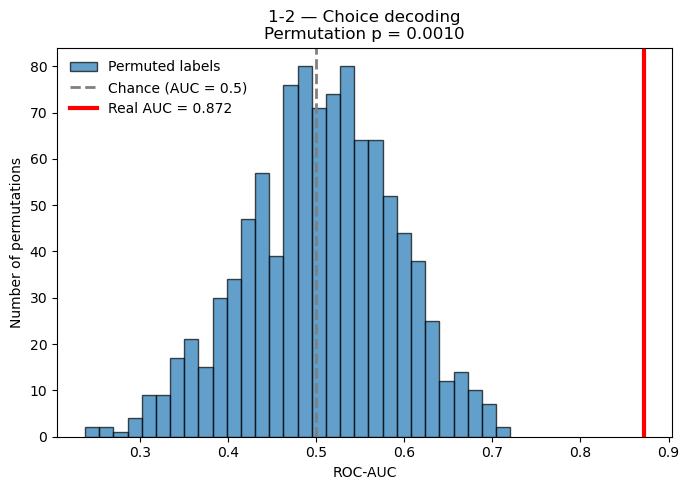

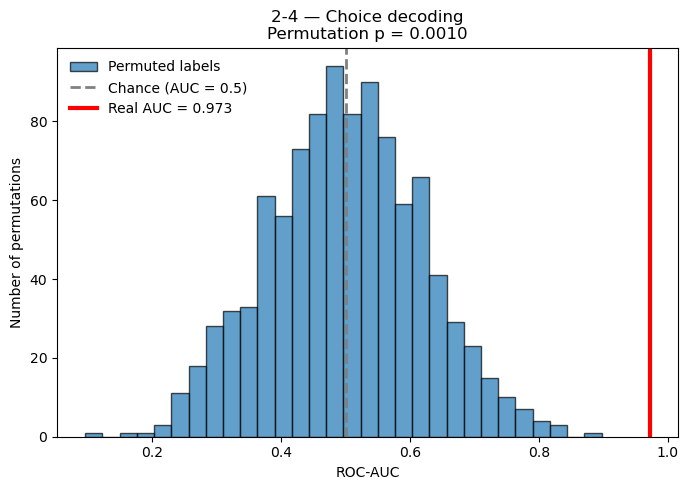

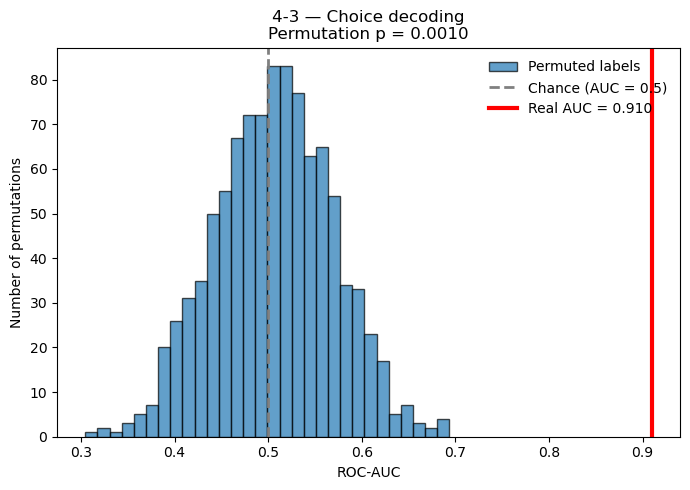

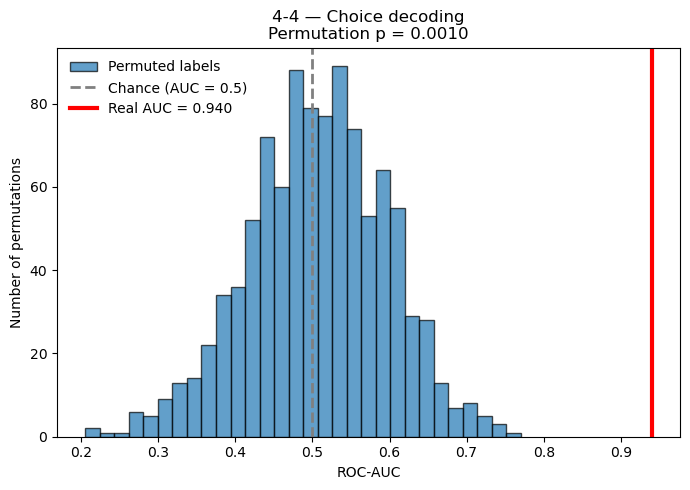

In [107]:
# ============================================================
# CELL 6 — PERMUTATION TEST PLOTS
# Real AUC vs null distribution
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


for recording_id, result in permutation_results.items():

    real_auc = result["real_auc"]
    null_auc = result["null_auc"]
    p_value = result["p_value"]

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )

    # Null distribution
    ax.hist(
        null_auc,
        bins=30,
        alpha=0.7,
        edgecolor="black",
        label="Permuted labels"
    )

    # Chance level
    ax.axvline(
        0.5,
        color="gray",
        linestyle="--",
        linewidth=2,
        label="Chance (AUC = 0.5)"
    )

    # Real AUC
    ax.axvline(
        real_auc,
        color="red",
        linestyle="-",
        linewidth=3,
        label=f"Real AUC = {real_auc:.3f}"
    )

    # --------------------------------------------------------
    # LABELS
    # --------------------------------------------------------

    ax.set_xlabel(
        "ROC-AUC"
    )

    ax.set_ylabel(
        "Number of permutations"
    )

    ax.set_title(
        f"{recording_id} — Choice decoding\n"
        f"Permutation p = {p_value:.4f}"
    )

    ax.legend(
        frameon=False
    )

    plt.tight_layout()
    plt.show()

In [108]:
StratifiedKFold(
    n_splits=5,
    shuffle=True
)

StratifiedKFold(n_splits=5, random_state=None, shuffle=True)

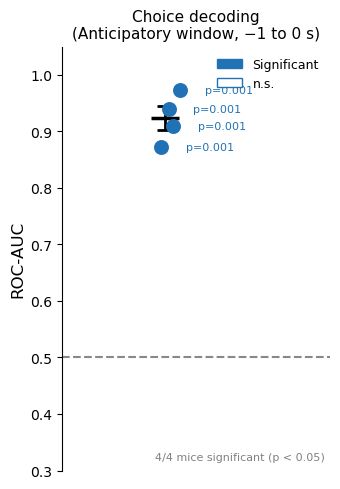

In [110]:
# ============================================================
# CELL 7 — POPULATION DECODING PLOT
# One point per mouse, mean ± SEM, chance reference
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ------------------------------------------------------------
# COLLECT DATA
# ------------------------------------------------------------

mouse_ids = list(permutation_results.keys())

aucs = np.array([
    permutation_results[m]["real_auc"]
    for m in mouse_ids
])

pvals = np.array([
    permutation_results[m]["p_value"]
    for m in mouse_ids
])

significant = pvals < 0.05


# ------------------------------------------------------------
# SUMMARY STATS
# ------------------------------------------------------------

mean_auc = np.mean(aucs)
sem_auc  = np.std(aucs, ddof=1) / np.sqrt(len(aucs))


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(3.5, 5))

x_pos = 0  # single column

# --- Chance line ---
ax.axhline(
    0.5,
    color="#888888",
    linestyle="--",
    linewidth=1.5,
    zorder=1,
    label="Chance (AUC = 0.5)"
)

# --- Mean ± SEM bar ---
ax.errorbar(
    x_pos,
    mean_auc,
    yerr=sem_auc,
    fmt="none",
    color="black",
    capsize=6,
    capthick=2,
    linewidth=2,
    zorder=2
)

ax.plot(
    x_pos,
    mean_auc,
    marker="_",
    markersize=20,
    markeredgewidth=2.5,
    color="black",
    zorder=3
)

# --- Individual mice ---
np.random.seed(42)
jitter = np.random.uniform(-0.08, 0.08, size=len(aucs))

for i, (auc, sig) in enumerate(zip(aucs, significant)):

    ax.scatter(
        x_pos + jitter[i],
        auc,
        s=80,
        color="#2171b5" if sig else "white",
        edgecolors="#2171b5",
        linewidths=1.8,
        zorder=4
    )

    # p-value annotation next to significant points
    if sig:
        ax.text(
            x_pos + jitter[i] + 0.12,
            auc,
            f"p={pvals[i]:.3f}",
            va="center",
            fontsize=8,
            color="#2171b5"
        )


# ------------------------------------------------------------
# AXES
# ------------------------------------------------------------

ax.set_xlim(-0.5, 0.8)
ax.set_ylim(0.3, 1.05)

ax.set_xticks([])
ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_title(
    "Choice decoding\n(Anticipatory window, −1 to 0 s)",
    fontsize=11
)

# How many significant
n_sig = significant.sum()

ax.text(
    0.98, 0.02,
    f"{n_sig}/{len(aucs)} mice significant (p < 0.05)",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
    color="gray"
)

# Legend
sig_patch = mpatches.Patch(
    facecolor="#2171b5",
    edgecolor="#2171b5",
    label="Significant"
)

ns_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="#2171b5",
    label="n.s."
)

ax.legend(
    handles=[sig_patch, ns_patch],
    frameon=False,
    fontsize=9,
    loc="upper right"
)

ax.spines[["top", "right", "bottom"]].set_visible(False)

plt.tight_layout()
plt.show()

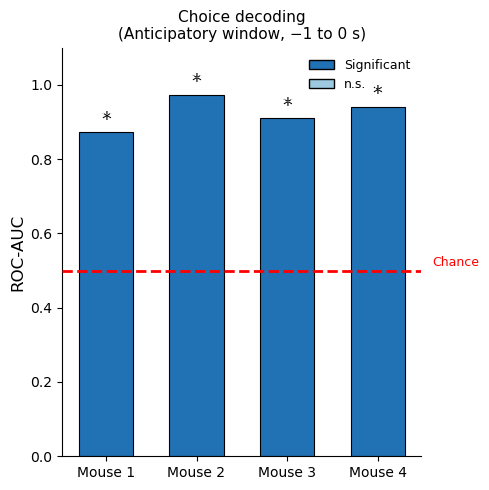

In [112]:
# ============================================================
# CELL 7 — POPULATION DECODING PLOT (BAR)
# One bar per mouse, chance reference at 0.5
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# COLLECT DATA
# ------------------------------------------------------------

mouse_ids = list(permutation_results.keys())

aucs = np.array([
    permutation_results[m]["real_auc"]
    for m in mouse_ids
])

pvals = np.array([
    permutation_results[m]["p_value"]
    for m in mouse_ids
])

significant = pvals < 0.05

n_mice = len(mouse_ids)
x_pos  = np.arange(n_mice)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 5))

# --- Bars ---
colors = [
    "#2171b5" if sig else "#9ecae1"
    for sig in significant
]

bars = ax.bar(
    x_pos,
    aucs,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    width=0.6,
    zorder=2
)

# --- Chance line at 0.5 ---
ax.axhline(
    0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    zorder=3,
    label="Chance (AUC = 0.5)"
)

ax.text(
    n_mice - 0.4,
    0.505,
    "Chance",
    color="red",
    fontsize=9,
    va="bottom"
)

# --- Significance stars above bars ---
for i, (auc, sig, p) in enumerate(
    zip(aucs, significant, pvals)
):
    if sig:
        ax.text(
            i,
            auc + 0.01,
            "*",
            ha="center",
            va="bottom",
            fontsize=14,
            color="black"
        )

    ax.text(
        i,
        auc + 0.04,
        f"p={p:.3f}",
        ha="center",
        va="bottom",
        fontsize=8,
        color="white"
    )


# ------------------------------------------------------------
# AXES
# ------------------------------------------------------------

ax.set_xticks(x_pos)
ax.set_xticklabels(
    [f"Mouse {i+1}" for i in range(n_mice)],
    fontsize=10
)

ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_ylim(0.0, 1.1)
ax.set_title(
    "Choice decoding\n(Anticipatory window, −1 to 0 s)",
    fontsize=11
)

# Legend
from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(facecolor="#2171b5", edgecolor="black", label="Significant"),
        Patch(facecolor="#9ecae1", edgecolor="black", label="n.s."),
    ],
    frameon=False,
    fontsize=9
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

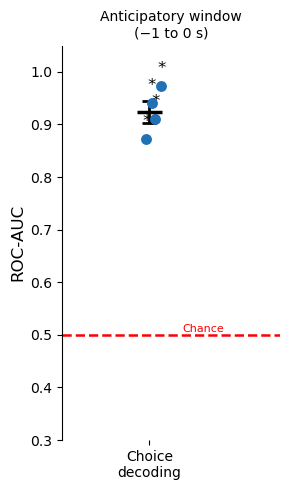

In [113]:
# ============================================================
# CELL 7 — POPULATION DECODING PLOT
# One point per mouse, mean ± SEM, chance reference
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# COLLECT DATA
# ------------------------------------------------------------

mouse_ids = list(permutation_results.keys())

aucs = np.array([
    permutation_results[m]["real_auc"]
    for m in mouse_ids
])

pvals = np.array([
    permutation_results[m]["p_value"]
    for m in mouse_ids
])

significant = pvals < 0.05


# ------------------------------------------------------------
# SUMMARY STATS
# ------------------------------------------------------------

mean_auc = np.mean(aucs)
sem_auc  = np.std(aucs, ddof=1) / np.sqrt(len(aucs))


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(3, 5))

x_pos = 0

# --- Chance line ---
ax.axhline(
    0.5,
    color="red",
    linestyle="--",
    linewidth=1.8,
    zorder=1
)

ax.text(
    0.55,
    0.502,
    "Chance",
    color="red",
    fontsize=8,
    va="bottom",
    transform=ax.get_yaxis_transform()
)

# --- Individual mice ---
np.random.seed(42)
jitter = np.random.uniform(-0.06, 0.06, size=len(aucs))

for i, (auc, sig) in enumerate(zip(aucs, significant)):

    ax.scatter(
        x_pos + jitter[i],
        auc,
        s=40,
        color="#2171b5" if sig else "white",
        edgecolors="#2171b5",
        linewidths=1.5,
        zorder=4
    )

    # Asterisk above significant points
    if sig:
        ax.text(
            x_pos + jitter[i],
            auc + 0.02,
            "*",
            ha="center",
            va="bottom",
            fontsize=12,
            color="black"
        )

# --- Mean ± SEM ---
ax.errorbar(
    x_pos,
    mean_auc,
    yerr=sem_auc,
    fmt="none",
    color="black",
    capsize=5,
    capthick=2,
    linewidth=2,
    zorder=3
)

ax.plot(
    x_pos,
    mean_auc,
    marker="_",
    markersize=18,
    markeredgewidth=2.5,
    color="black",
    zorder=5
)


# ------------------------------------------------------------
# AXES
# ------------------------------------------------------------

ax.set_xlim(-0.4, 0.6)
ax.set_ylim(0.3, 1.05)

ax.set_xticks([0])
ax.set_xticklabels(
    ["Choice\ndecoding"],
    fontsize=10
)

ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_title(
    "Anticipatory window\n(−1 to 0 s)",
    fontsize=10
)

ax.spines[["top", "right", "bottom"]].set_visible(False)

plt.tight_layout()
plt.show()

Analisis para ver la distrubicion de los ensayos (prosocial anbd selfish) traves del recording 

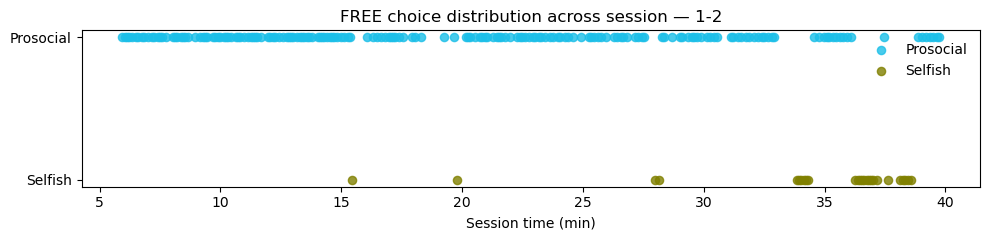

1-2: Pro = 185, Self = 26


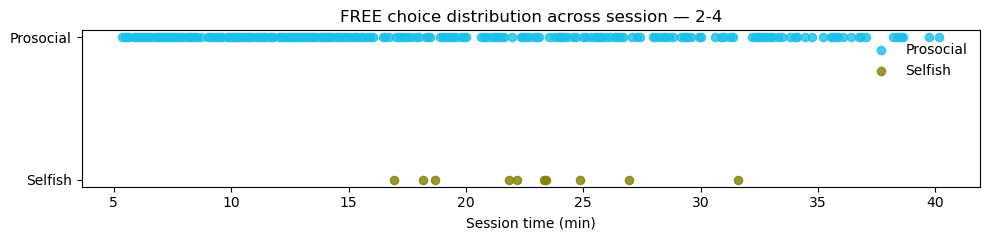

2-4: Pro = 219, Self = 10


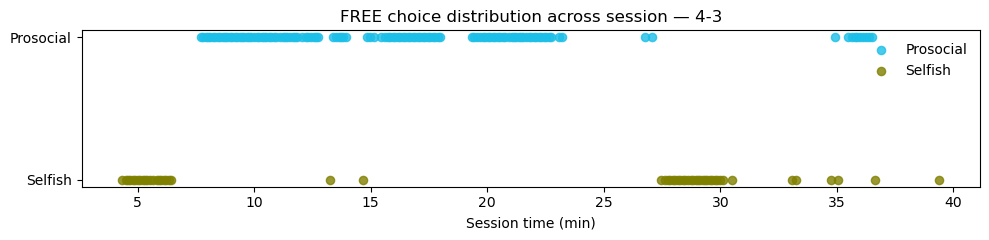

4-3: Pro = 126, Self = 54


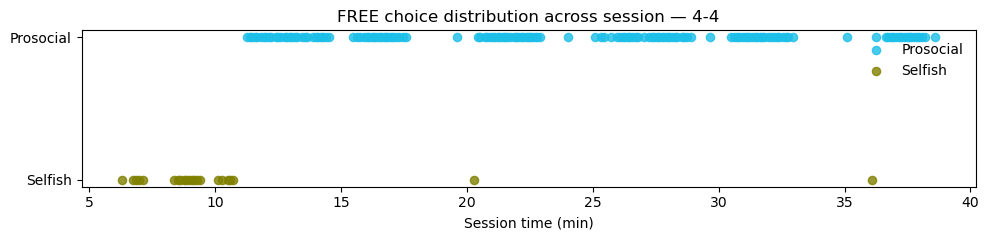

4-4: Pro = 149, Self = 22


In [109]:
# ============================================================
# CHOICE DISTRIBUTION ACROSS SESSION
# FREE TRIALS ONLY
# Prosocial vs Selfish nose-poke times
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


for recording_id in nosepoke_recordings:

    # --------------------------------------------------------
    # FREE TRIALS ONLY
    # --------------------------------------------------------

    pro_times = np.asarray(
        analysis["free"]["events"][recording_id]["prosocial"]
    )

    self_times = np.asarray(
        analysis["free"]["events"][recording_id]["selfish"]
    )


    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 2.5)
    )


    # Prosocial FREE trials
    ax.scatter(
        pro_times / 60,
        np.ones(len(pro_times)),
        color="#1CBFE8",
        s=35,
        alpha=0.8,
        label="Prosocial"
    )


    # Selfish FREE trials
    ax.scatter(
        self_times / 60,
        np.zeros(len(self_times)),
        color="#808000",
        s=35,
        alpha=0.8,
        label="Selfish"
    )


    # --------------------------------------------------------
    # FORMAT
    # --------------------------------------------------------

    ax.set_yticks([0, 1])

    ax.set_yticklabels([
        "Selfish",
        "Prosocial"
    ])

    ax.set_xlabel(
        "Session time (min)"
    )

    ax.set_title(
        f"FREE choice distribution across session — {recording_id}"
    )

    ax.legend(
        frameon=False,
        loc="upper right"
    )

    plt.tight_layout()
    plt.show()


    # --------------------------------------------------------
    # CHECK TRIAL NUMBERS
    # --------------------------------------------------------

    print(
        f"{recording_id}: "
        f"Pro = {len(pro_times)}, "
        f"Self = {len(self_times)}"
    )